# CS 5450 Project - Airbnb user experience prediction & analysis of relation to home values

## Introduction:

For our project, we wanted to understand two key problems:
1. How do the features of an airbnb (bedrooms, bathrooms, amenities offered, etc.) affect the average user experience (as reflected by the rating the user leaves on an airbnb?
2. How does average price of a rental unit/home in a neighborhood relate to the average price of an airbnb in the same area?

To understand the first question, we had to combine a variety of airbnb datasets from different cities, using data from insideairbnb.com. Each dataset (stored by convention as the variable `{cityname}Airbnbdf` ) contains the number of bedrooms/bathrooms, amenities (stored as a string of varying amenities), airbnb review score, and other relevant features. Although there are certainly risks in combining together airbnb data from very different cities, we have done a lot to mitigate any unexpected variance in our data (e.g. by normalizing prices over each region, rather than using raw price values) - and that these risks are worth it for the sake of having a large enough dataset to test non-trivial models on.

To understand the second question, we limited ourselves to just looking at New York city, with two datasets: `NYAirbnbdf` which is a very large dataset with detailed information about airbnb listings in New York City, and `NYHousingdf` which contains information about prices of apartments/homes in New York City. By grouping by zipcode, we analyzed how the prices in airbnb listings and prices of apartment listings were related.

Our findings and techniques for answering both questions are detailed below. Please enjoy!


# Part 0 - Setting everything up

In [ ]:
#Installs
!pip install kagglehub[pandas-datasets]
!pip install forex_python
!pip install currencyconverter

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 643.9/643.9 kB 15.7 MB/s eta 0:00:00


### Part 0.a - Necessary **Imports**

In [ ]:
#Imports
import pandas as pd
import numpy as np
import math
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
import duckdb
import kagglehub
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_absolute_error
from kagglehub import KaggleDatasetAdapter
from forex_python.converter import CurrencyRates
from currency_converter import CurrencyConverter
import pprint
from imblearn.pipeline import Pipeline
from imblearn.under_sampling import RandomUnderSampler
from imblearn.over_sampling import SMOTEN
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import accuracy_score
import pickle
from sklearn import tree
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, accuracy_score, ConfusionMatrixDisplay
from sklearn.ensemble import RandomForestClassifier


### Part 0.b - Loading datasets using kagglehub into pandas dataframes

In [ ]:
#First datasets are available via Kaggle

#Loads New York City Dataset w/ Housing prices
NYHousingdf = kagglehub.load_dataset(
     KaggleDatasetAdapter.PANDAS,
    "ericpierce/new-york-housing-zillow-api",
    "newyork_housing.csv"
)[["address/city", "address/streetAddress", "address/zipcode", "bathrooms", "bedrooms", "price","latitude","longitude"]]

#Loads New York city dataset with airbnb data
NYAirbnbdf = kagglehub.load_dataset(
    KaggleDatasetAdapter.PANDAS,
    "arianazmoudeh/airbnbopendata",
    "Airbnb_Open_Data.csv"
)

#Loads Seattle Airbnb data
seattleAirbnbdf = kagglehub.load_dataset(
    KaggleDatasetAdapter.PANDAS,
    "airbnb/seattle",
    "listings.csv"
)

#Loads Boston Airbnb data
bostonAirbnbdf = kagglehub.load_dataset(
    KaggleDatasetAdapter.PANDAS,
    "airbnb/boston",
    "listings.csv"
)

#Loads Madrid Airbnb data
madridAirbnbdf = kagglehub.load_dataset(
  KaggleDatasetAdapter.PANDAS,
  "rusiano/madrid-airbnb-data",
  "listings_detailed.csv",
  # Provide any additional arguments like
  # sql_query or pandas_kwargs. See the
  # documenation for more information:
  # https://github.com/Kaggle/kagglehub/blob/main/README.md#kaggledatasetadapterpandas
)

#Loads New Orleans Airbnb data
newOrleansAirbnbdf = kagglehub.load_dataset(
  KaggleDatasetAdapter.PANDAS,
  "ruthgn/new-orleans-airbnb-listings-and-reviews",
  "new_orleans_airbnb_listings.csv"
  # Provide any additional arguments like
  # sql_query or pandas_kwargs. See the
  # documenation for more information:
  # https://github.com/Kaggle/kagglehub/blob/main/README.md#kaggledatasetadapterpandas
)

#Loads Amsterdam Airbnb data
amsterdamAirbnbdf = kagglehub.load_dataset(
  KaggleDatasetAdapter.PANDAS,
  "erikbruin/airbnb-amsterdam",
  "listings_details.csv",
  # Provide any additional arguments like
  # sql_query or pandas_kwargs. See the
  # documenation for more information:
  # https://github.com/Kaggle/kagglehub/blob/main/README.md#kaggledatasetadapterpandas
)


#Next datasets are not available on Kaggle, but are open source, via insideairbnb.com
 #(Licensed data under the Creative Commons Attribution 4.0 International License.)

# Installs the data into our local environment
!wget https://data.insideairbnb.com/united-states/dc/washington-dc/2025-09-22/data/listings.csv.gz -O washDCListings.csv.gz
!wget https://data.insideairbnb.com/united-states/tx/austin/2025-09-16/data/listings.csv.gz -O austinListings.csv.gz
!wget https://data.insideairbnb.com/united-states/il/chicago/2025-09-22/data/listings.csv.gz -O chicagoListings.csv.gz
!wget https://data.insideairbnb.com/united-states/tx/dallas/2026-01-20/data/listings.csv.gz -O dallasListings.csv.gz
!wget https://data.insideairbnb.com/united-states/co/denver/2025-09-29/data/listings.csv.gz -O denverListings.csv.gz
!wget https://data.insideairbnb.com/united-states/oh/columbus/2025-09-26/data/listings.csv.gz -O columbusListings.csv.gz
!wget https://data.insideairbnb.com/united-states/ca/los-angeles/2025-12-04/data/listings.csv.gz -O losangelesListings.csv.gz
!wget https://data.insideairbnb.com/united-states/ny/new-york-city/2026-02-13/data/listings.csv.gz -O newyorkListings.csv.gz
!wget https://data.insideairbnb.com/united-states/ca/san-diego/2025-09-25/data/listings.csv.gz -O sandiegoListings.csv.gz
!wget https://data.insideairbnb.com/united-states/ca/san-francisco/2025-12-04/data/listings.csv.gz -O sanfranciscoListings.csv.gz
!wget https://data.insideairbnb.com/united-states/tn/nashville/2025-09-23/data/listings.csv.gz -O nashvilleListings.csv.gz


#Uncompresses and loads the different datasets in dataframes
austinAirbnbdf = pd.read_csv('austinListings.csv.gz', compression='gzip')
washdcAirbnbdf = pd.read_csv('washDCListings.csv.gz', compression = 'gzip')
chicagoAirbnbdf = pd.read_csv('chicagoListings.csv.gz', compression = 'gzip')
dallasAirbnbdf = pd.read_csv('dallasListings.csv.gz', compression = 'gzip')
denverAirbnbdf = pd.read_csv('denverListings.csv.gz', compression = 'gzip')
columbusAirbnbdf = pd.read_csv('columbusListings.csv.gz', compression = 'gzip')
losangelesAirbnbdf = pd.read_csv('losangelesListings.csv.gz', compression = 'gzip')
newyorkAirbndfBetter = pd.read_csv('newyorkListings.csv.gz', compression = 'gzip')
sandiegoAirbnbdf = pd.read_csv('sandiegoListings.csv.gz', compression = 'gzip')
sanfranciscoAirbnbdf = pd.read_csv('sanfranciscoListings.csv.gz', compression = 'gzip')
nashvilleAirbnbdf = pd.read_csv('nashvilleListings.csv.gz', compression = 'gzip')

# I know it seems weird to import new york airbnb data twice, but the second new york is formatted in a
#  more similar way to the other data that we want to use for analyzing amenities

/tmp/ipykernel_2132/1338512712.py:4: DeprecationWarning: Use dataset_load() instead of load_dataset(). load_dataset() will be removed in a future version.
  NYHousingdf = kagglehub.load_dataset(


100%|██████████| 59.9M/59.9M [00:00<00:00, 99.0MB/s]

Extracting zip of newyork_housing.csv...



/usr/local/lib/python3.12/dist-packages/kagglehub/pandas_datasets.py:92: DtypeWarning: Columns (2,5,51,52,53,54,55,56,57,58,59,60,61,62,63,64,65,66,67,68,69,70,71,72,73,74,75,76,77,78,79,80,81,82,83,84,85,86,87,88,89,90,91,92,93,94,95,96,97,98,99,100,101,102,103,104,105,106,107,108,109,110,111,112,113,114,115,116,117,118,119,120,121,122,123,124,125,126,127,128,129,130,131,132,133,134,135,136,137,138,139,140,141,142,143,144,145,146,147,148,149,150,151,152,153,154,155,156,157,158,159,160,161,162,163,164,165,166,167,168,169,170,171,172,173,174,175,176,177,178,179,180,181,182,183,184,185,186,187,188,189,190,191,192,193,194,195,196,197,198,199,200,201,202,203,204,205,206,207,208,209,210,211,212,213,214,215,216,217,218,219,220,221,222,223,224,225,226,227,228,229,230,231,232,233,234,235,236,237,238,239,240,241,242,243,244,245,246,247,248,249,250,251,252,253,254,255,256,257,258,259,260,261,262,263,264,265,266,267,268,269,270,271,272,273,274,275,276,277,278,279,280,281,282,283,284,285,286,287,

100%|██████████| 10.5M/10.5M [00:00<00:00, 58.7MB/s]

...


/tmp/ipykernel_2132/1338512712.py:54: DeprecationWarning: Use dataset_load() instead of load_dataset(). load_dataset() will be removed in a future version.
  amsterdamAirbnbdf = kagglehub.load_dataset(


100%|██████████| 18.1M/18.1M [00:00<00:00, 69.4MB/s]

Extracting zip of listings_details.csv...



/usr/local/lib/python3.12/dist-packages/kagglehub/pandas_datasets.py:92: DtypeWarning: Columns (87) have mixed types. Specify dtype option on import or set low_memory=False.
  result = read_function(


--2026-04-27 13:33:11--  https://data.insideairbnb.com/united-states/dc/washington-dc/2025-09-22/data/listings.csv.gz
Resolving data.insideairbnb.com (data.insideairbnb.com)... 3.163.189.63, 3.163.189.67, 3.163.189.99, ...
Connecting to data.insideairbnb.com (data.insideairbnb.com)|3.163.189.63|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 3926626 (3.7M) [application/x-gzip]
Saving to: ‘washDCListings.csv.gz’

washDCListings.csv. 100%[===================>]   3.74M  --.-KB/s    in 0.05s   

2026-04-27 13:33:12 (78.5 MB/s) - ‘washDCListings.csv.gz’ saved [3926626/3926626]

--2026-04-27 13:33:12--  https://data.insideairbnb.com/united-states/tx/austin/2025-09-16/data/listings.csv.gz
Resolving data.insideairbnb.com (data.insideairbnb.com)... 3.163.189.63, 3.163.189.67, 3.163.189.99, ...
Connecting to data.insideairbnb.com (data.insideairbnb.com)|3.163.189.63|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 6496388 (6.2M) [application/x-g

Note - there are many other columns to use for the NYHousing dataset (which had ~1500 features) however most columns have some issues, namely
1. Too many null values to be usable
2. Were columns consisting of links to photos
3. were columns consisting of some historical information (i.e. price at a previous point in time, listing date at a previous time, etc.)


# Part 1 - An amenity vs price/rating comparison



## 1.1 Understanding the data

In [ ]:
#Glimpse at columns of our dataframe
dallasAirbnbdf.columns

Index(['id', 'listing_url', 'scrape_id', 'last_scraped', 'source', 'name',
       'description', 'neighborhood_overview', 'picture_url', 'host_id',
       'host_url', 'host_profile_id', 'host_profile_url', 'host_name',
       'host_since', 'hosts_time_as_user_years', 'hosts_time_as_user_months',
       'hosts_time_as_host_years', 'hosts_time_as_host_months',
       'host_location', 'host_about', 'host_response_time',
       'host_response_rate', 'host_acceptance_rate', 'host_is_superhost',
       'host_thumbnail_url', 'host_picture_url', 'host_neighbourhood',
       'host_listings_count', 'host_total_listings_count',
       'host_verifications', 'host_has_profile_pic', 'host_identity_verified',
       'neighbourhood', 'neighbourhood_cleansed',
       'neighbourhood_group_cleansed', 'latitude', 'longitude',
       'property_type', 'room_type', 'accommodates', 'bathrooms',
       'bathrooms_text', 'bedrooms', 'beds', 'amenities', 'price',
       'minimum_nights', 'maximum_nights', 'minim

As we can see above, we have a **lot** of features to choose from. Since we are more concerned with how features *about the home* affect price / review score, we think it is best to first restrict to these features

In [ ]:
#Take a subset of the features, for simplicity
LimitedBostonDf = bostonAirbnbdf[['id', 'city', 'property_type', 'room_type', 'accommodates', 'bathrooms', 'bedrooms', 'amenities', 'square_feet', 'price', "number_of_reviews", "review_scores_rating", "minimum_nights"]]
LimitedSeattleDf = seattleAirbnbdf[['id', 'city', 'property_type', 'room_type', 'accommodates', 'bathrooms', 'bedrooms', 'amenities', 'square_feet', 'price', "number_of_reviews", "review_scores_rating", "minimum_nights"]]
LimitedMadridDf = madridAirbnbdf[['id', 'property_type', 'room_type', 'accommodates', 'bathrooms_text', 'bedrooms', 'amenities', 'price', "number_of_reviews", "review_scores_rating", "minimum_nights"]]
LimitedAmsterdamDf = amsterdamAirbnbdf[['id', 'city', 'property_type', 'room_type', 'accommodates', 'bathrooms', 'bedrooms', 'amenities', 'square_feet', 'price', "number_of_reviews", "review_scores_rating", "minimum_nights"]]
LimitedNewOrleansDf = newOrleansAirbnbdf[['id', 'property_type', 'room_type', 'accommodates', 'bathrooms_text', 'bedrooms', 'amenities', 'price', "number_of_reviews", "review_scores_rating", "minimum_nights"]]
LimitedAustinDf = austinAirbnbdf[['id', 'property_type', 'room_type', 'accommodates', 'bathrooms', 'bedrooms', 'amenities', 'price', "number_of_reviews", "review_scores_rating", "minimum_nights"]]
LimitedWashDCDf = washdcAirbnbdf[['id', 'property_type', 'room_type', 'accommodates', 'bathrooms', 'bedrooms', 'amenities', 'price', "number_of_reviews", "review_scores_rating", "minimum_nights"]]
LimitedChicagoDf = chicagoAirbnbdf[['id', 'property_type', 'room_type', 'accommodates', 'bathrooms', 'bedrooms', 'amenities', 'price', "number_of_reviews", "review_scores_rating", "minimum_nights"]]
LimitedDallasDf = dallasAirbnbdf[['id', 'property_type', 'room_type', 'accommodates', 'bathrooms', 'bedrooms', 'amenities', 'price', "number_of_reviews", "review_scores_rating", "minimum_nights"]]
LimitedDenverDf = denverAirbnbdf[['id', 'property_type', 'room_type', 'accommodates', 'bathrooms', 'bedrooms', 'amenities', 'price', "number_of_reviews", "review_scores_rating", "minimum_nights"]]
LimitedColumbusDf = columbusAirbnbdf[['id', 'property_type', 'room_type', 'accommodates', 'bathrooms', 'bedrooms', 'amenities', 'price', "number_of_reviews", "review_scores_rating", "minimum_nights"]]
LimitedLosangelesDf = losangelesAirbnbdf[['id', 'property_type', 'room_type', 'accommodates', 'bathrooms', 'bedrooms', 'amenities', 'price', "number_of_reviews", "review_scores_rating", "minimum_nights"]]
LimitedNewyorkDf = newyorkAirbndfBetter[['id', 'property_type', 'room_type', 'accommodates', 'bathrooms', 'bedrooms', 'amenities', 'price', "number_of_reviews", "review_scores_rating", "minimum_nights"]]
LimitedSandiegoDf = sandiegoAirbnbdf[['id', 'property_type', 'room_type', 'accommodates', 'bathrooms', 'bedrooms', 'amenities', 'price', "number_of_reviews", "review_scores_rating", "minimum_nights"]]
LimitedSanfranDf = sanfranciscoAirbnbdf[['id', 'property_type', 'room_type', 'accommodates', 'bathrooms', 'bedrooms', 'amenities', 'price', "number_of_reviews", "review_scores_rating", "minimum_nights"]]
LimitedNashvilleDf = nashvilleAirbnbdf[['id', 'property_type', 'room_type', 'accommodates', 'bathrooms', 'bedrooms', 'amenities', 'price', "number_of_reviews", "review_scores_rating", "minimum_nights"]]


# Stores the dataframes in a list, to simplify some of our data cleaning process
databases = [('Boston', LimitedBostonDf), ('Seattle', LimitedSeattleDf),('Madrid',LimitedMadridDf), ('Amsterdam', LimitedAmsterdamDf),
            ('NewOrleans', LimitedNewOrleansDf), ('Austin', LimitedAustinDf), ('Wash D.C.', LimitedWashDCDf),
             ('Chicago', LimitedChicagoDf), ('Dallas', LimitedDallasDf), ('Denver', LimitedDenverDf), ('Columbus', LimitedColumbusDf),
             ('Los Angeles', LimitedLosangelesDf), ('New York City', LimitedNewyorkDf), ('San Diego', LimitedSandiegoDf),
              ('San Francisco', LimitedSanfranDf), ('Nashville', LimitedNashvilleDf)]

#Systematically print info about each of our databases
print('\n\n Database Info:\n\n')
for name, df in databases:
  print(name + " info:\n\n")
  df.info()
  print("\n\n")





 Database Info:


Boston info:


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3585 entries, 0 to 3584
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   id                    3585 non-null   int64  
 1   city                  3583 non-null   object 
 2   property_type         3582 non-null   object 
 3   room_type             3585 non-null   object 
 4   accommodates          3585 non-null   int64  
 5   bathrooms             3571 non-null   float64
 6   bedrooms              3575 non-null   float64
 7   amenities             3585 non-null   object 
 8   square_feet           56 non-null     float64
 9   price                 3585 non-null   object 
 10  number_of_reviews     3585 non-null   int64  
 11  review_scores_rating  2772 non-null   float64
 12  minimum_nights        3585 non-null   int64  
dtypes: float64(4), int64(4), object(5)
memory usage: 364.2+ KB



Seattle info:


<class 'pa

**Things to note about our data**:
 - Dallas, Los Angeles, New York, and San francisco datasets have no price inputs! However, we still want to use the other data from these datasets, say for analyzing how different amenities tend to affect user experience - so we split up into two separate lists of datasets.
 - Madrid is missing a city column (should be manually added), and a square footage column (can live without this)
 - Madrid DOES have a bathrooms column - but actually has NO values in it! better to use its 'bathrooms_text'
 - Austin, Wash D.C., Chicago, Dallas, Denver, Columbus missing city & square_feet column
 - NewOrleans is missing: city, square_feet, and bathrooms
 - However, NewOrleans is a bit special; it actually DOES have information on number of bathrooms, just as a separate bathrooms_text column

In [ ]:
#Create new list of dataframes that contain a 'price' feature
databases_with_price = [('Boston', LimitedBostonDf.copy(deep = True)), ('Seattle', LimitedSeattleDf.copy(deep = True)),('Madrid',LimitedMadridDf.copy(deep = True)), ('Amsterdam', LimitedAmsterdamDf.copy(deep = True)),
            ('NewOrleans', LimitedNewOrleansDf.copy(deep = True)), ('Austin', LimitedAustinDf.copy(deep = True)), ('Wash D.C.', LimitedWashDCDf.copy(deep = True)),
             ('Chicago', LimitedChicagoDf.copy(deep = True)), ('Denver', LimitedDenverDf.copy(deep = True)), ('Columbus', LimitedColumbusDf.copy(deep = True)),
              ('San Diego', LimitedSandiegoDf.copy(deep = True)), ('Nashville', LimitedNashvilleDf.copy(deep = True))]

#Create list of all dataframes (including those without a 'price' feature)
databases_no_price = [('Boston', LimitedBostonDf.copy(deep = True)), ('Seattle', LimitedSeattleDf.copy(deep = True)),('Madrid',LimitedMadridDf.copy(deep = True)), ('Amsterdam', LimitedAmsterdamDf.copy(deep = True)),
            ('NewOrleans', LimitedNewOrleansDf.copy(deep = True)), ('Austin', LimitedAustinDf.copy(deep = True)), ('Wash D.C.', LimitedWashDCDf.copy(deep = True)),
             ('Chicago', LimitedChicagoDf.copy(deep = True)), ('Dallas', LimitedDallasDf.copy(deep = True)), ('Denver', LimitedDenverDf.copy(deep = True)), ('Columbus', LimitedColumbusDf.copy(deep = True)),
             ('Los Angeles', LimitedLosangelesDf.copy(deep = True)), ('New York City', LimitedNewyorkDf.copy(deep = True)),
             ('San Diego', LimitedSandiegoDf.copy(deep = True)), ('San Francisco', LimitedSanfranDf.copy(deep = True)), ('Nashville', LimitedNashvilleDf.copy(deep = True))]
#print([name for (name, df) in databases_adjusted])

## 1.2 Removing unnecessary columns & adjusting for poorly formatted data

5 main issues to address:
- As above, in our dataframes, there is either no square_feet data, or it is incredibly rare, so it's better to just remove this columns altogether
- Price is formatted differently in each dataframe, and never as a number
- Dataframes that were missing city values need to have these added for later, as it will be useful when we merge all these dataframes into one
- Need to apply regex methods to data in the 'bathrooms_text' column for New Orleans specifically
- Normalizing the way that our databases store review scores (some are on a 5 point scale, others are on a 100 point scale)
     - For simplicity, easier to adjust 100 -> 5 point scale - but also would be good to add a simpler characterization of experience, e.g. 3 categories of 'negative experience', 'average experience', above average experience'



### 1.2.1 Dropping square_feet columns & Null values

Note: we could also opt to drop any null values... but if you look at the .info() outputs from above, you'll see that the review_scores_rating rows have a LOT of null values - we just need to keep in mind that we are potentially losing out on a good amount of good data in the other categories

In [ ]:

#Drops 'square_feet feature - since many of our dataframes do not have this feature
if 'square_feet' in LimitedBostonDf.columns:
  LimitedBostonDf = LimitedBostonDf.drop(columns = 'square_feet') #drops unnecessary columns
if 'square_feet' in LimitedAmsterdamDf.columns:
  LimitedAmsterdamDf = LimitedAmsterdamDf.drop(columns = 'square_feet') #drops unnecessary columns
if 'square_feet' in LimitedSeattleDf.columns:
  LimitedSeattleDf = LimitedSeattleDf.drop(columns = 'square_feet') #drops unnecessary columns

#Iterates through our dataframes and drops rows with null values
for i, tup in enumerate(databases_with_price):
  databases_with_price[i][1].dropna(inplace = True, how = 'any')

#Same as above, but also drops the price column (since some dataframes have only/mostly null values in this column)
for i, tup in enumerate(databases_no_price):
  print(tup[0])
  if 'price' in databases_no_price[i][1].columns:
    databases_no_price[i][1].drop(columns = 'price', inplace = True)
  databases_no_price[i][1].dropna(inplace=True, how = 'any')

#NOTE TO SELF - when you work with lists of dataframes, weird things can happen...
#
#    Namely, when we assign a variable to elements of a list (e.g. for df in dataframe_list)
#        df is a COPY of the dataframe from the list - NOT the original dataframe contained in the list
#

Boston
Seattle
Madrid
Amsterdam
NewOrleans
Austin
Wash D.C.
Chicago
Dallas
Denver
Columbus
Los Angeles
New York City
San Diego
San Francisco
Nashville


In [ ]:
print(databases_with_price[2][0])
# Note that because when we make lists of dataframes,
# these lists actually contain COPIES of the dataframes NOT pointers!
# So after we make changes, we have to reaccess the dataframes through these lists
databases_with_price[2][1].head()

Madrid


,id,property_type,room_type,accommodates,bathrooms_text,bedrooms,amenities,price,number_of_reviews,review_scores_rating,minimum_nights
0,6369,Private room in apartment,Private room,2,1 shared bath,1.0,"[""Kitchen"", ""Elevator"", ""Extra pillows and bla...",$60.00,78,98.0,1
1,21853,Private room in apartment,Private room,1,1 bath,1.0,"[""Bed linens"", ""Refrigerator"", ""Dishes and sil...",$31.00,33,92.0,4
4,26825,Private room in house,Private room,1,1 private bath,1.0,"[""Elevator"", ""Patio or balcony"", ""Bed linens"",...",$26.00,149,94.0,2
6,30320,Entire apartment,Entire home/apt,2,1 bath,1.0,"[""TV with standard cable"", ""Heating"", ""Air con...",$65.00,170,93.0,5
7,30959,Entire loft,Entire home/apt,2,1 bath,1.0,"[""TV with standard cable"", ""Kitchen"", ""Elevato...",$54.00,8,88.0,3


### 1.2.2 - Price formatting

In [ ]:
# Note that actually all of the dataframes format price in terms of strings like '$100.00'
from pandas.api.types import is_string_dtype

#Iterate though dataframes
for i, tup in enumerate(databases_with_price):
  df = tup[1]
  #Check if the dataframe is a string
  if is_string_dtype(df['price'].dtype):
    print(tup[0])

    #Create new Series, which reformats the string '$100.00' as a float 100.0
    AdjustedPriceSeries = (df['price'].str.replace('$', '')
                                .str.replace(',', '')
                                .astype(float))

    #Replaces the 'price' feature in our dataframe with the above series
    databases_with_price[i][1]['price'] = AdjustedPriceSeries # <---- weird indexing, but remember that we have to change the original dataframe, which is only
    #                                                                 possible if we index the list itself



Boston
Seattle
Madrid
Amsterdam
NewOrleans
Austin
Wash D.C.
Chicago
Denver
Columbus
San Diego
Nashville


### 1.2.3 - Price conversions
According to insideairbnb's data dictionary... " price is in local currency. NOTE: the $ sign is a technical artifact of the export, please ignore it"

This means that for madrid and Amsterdam, we would need to convert these prices into dollars

#### A small aside on accuracy vs speed trade-offs

Although currency conversion is a fairly simple issue, we already see the impacts of small choices when working with large datasets. Below we have two options of currency conversion modules:
- CurrencyConverter - which uses fixed rate conversion (e.g. rates obtained at **time of import**)
- CurrencyRates - which uses up-to-date conversions (e.g. rates obtained at **runtime**)

Testing these on a set of 100 random values in the range [0,100], we see that there are some noticable differences between the two, albeit small

In [ ]:
%%time
d = CurrencyConverter()

#Make Series with 100 random values (in range [0, 100]) - representing EUR values
test = pd.Series(np.random.rand(100) * 100)

#Convert the entries in the series to USD
test.apply(lambda x: d.convert(x, 'EUR', 'USD'))


print('Using fixed historical conversions:')

Using fixed historical conversions:
CPU times: user 295 ms, sys: 20.7 ms, total: 315 ms
Wall time: 320 ms


In [ ]:
%%time
c = CurrencyRates()

#Make Series with 100 random values (in range [0, 100]) - representing EUR values
test = pd.Series(np.random.rand(100) * 100)

#Convert the entries in the series to USD
test.apply(lambda x: c.convert('EUR', 'USD', x))
print('Using up-to-date conversions:')

Using up-to-date conversions:
CPU times: user 909 ms, sys: 73.6 ms, total: 982 ms
Wall time: 1min 8s


However, when we have to make a choice about which to use on our ~50000+ row dataset, the slower option took *more than 20 minutes* (and even at that point was still running) - hence was completely unusable. Thus, we made a tradeoff of accuracy for having an easier to run module

In [ ]:
#Loads the faster currency converter
d = CurrencyConverter()

#iterates through our list of dataframes
for i, tup in enumerate(databases_with_price):
  df = tup[1]
  city = tup[0]
  #Checks if the cities are non-US cities
  if city  in ['Madrid', 'Amsterdam']:

    #Changes the price column via conversion to Euros
    df['price'] = df['price'].apply(lambda x: d.convert(x, 'EUR', 'USD'))




### 1.2.4 - Adding city values

In [ ]:

#Iterates through list of dataframes
for i, tup in enumerate(databases_with_price):

  #Checks if we have a 'city' feature in our dataframe
  if 'city' not in databases_with_price[i][1].columns:
    #If not, adds this feature
    databases_with_price[i][1]['city'] = tup[0]

#Same as above
for i, tup in enumerate(databases_no_price):
  if 'city' not in databases_no_price[i][1].columns:
    databases_no_price[i][1]['city'] = tup[0]

### 1.2.5 - Fixing bathroom values

In [ ]:
#Create list of only two cities that do not have a standardized 'bathrooms' feature already
bathroom_fix_list = ["NewOrleans", 'Madrid']

#Make a regex string - the goal is to convert entries like '2 bathrooms' or '1.5 bathrooms' into a float
intGetRegex = r"^(?P<bathrooms>[\d\.]+) .*"

#Iterates through our list of dataframes
for i, tup in enumerate(databases_with_price):
  df = tup[1]

  #Checks if this dataframe is one of the problematic ones
  if tup[0] in bathroom_fix_list:

    #Applies our regex function to pull out a new Series
    # which consists of the groups from the regex
    bathSeries = df['bathrooms_text'].str.extract(intGetRegex)

    #Replaces 'bathrooms' feature with this new series
    databases_with_price[i][1]['bathrooms'] = bathSeries

#Same as above
for i, tup in enumerate(databases_no_price):
  df = tup[1]
  if tup[0] in bathroom_fix_list:
    bathSeries = df['bathrooms_text'].str.extract(intGetRegex)
    databases_no_price[i][1]['bathrooms'] = bathSeries



### 1.2.6 - Normalizing review values

In [ ]:
#Iterates through dataframes
for i, tup in enumerate(databases_with_price):
  df = tup[1]

  #Check to see how many entries of our dataframe have reviews with a score that is MORE than 5
  # (We want our reviews to be only OUT of 5, so we are fixing the problematic cases)
  count = (df['review_scores_rating'] > 5).sum()
  if count > 0:

    #The only cases for our dataframes are that 1. reviews are scores x out of 5, or 2. reviews are scores x out of 100
    #The if statement ensures we are not in the first case, hence the review must be a score out of 100
    # ---> Thus we divide by 20 to get to a review out of 5
    databases_with_price[i][1]['review_scores_rating'] = (df['review_scores_rating'] / 20).round(2)

#Same as above
for i, tup in enumerate(databases_no_price):
  df = tup[1]
  count = (df['review_scores_rating'] > 5).sum()
  if count > 0:
    databases_no_price[i][1]['review_scores_rating'] = (df['review_scores_rating'] / 20).round(2)


## 1.3 - Generating Visualizations

To have a first idea of what our data looks like, we plot price against number of reviews, review score rating and the number of bedrooms and bathrooms.

Number of reviews Vs. Price

<Figure size 1000x3000 with 0 Axes>

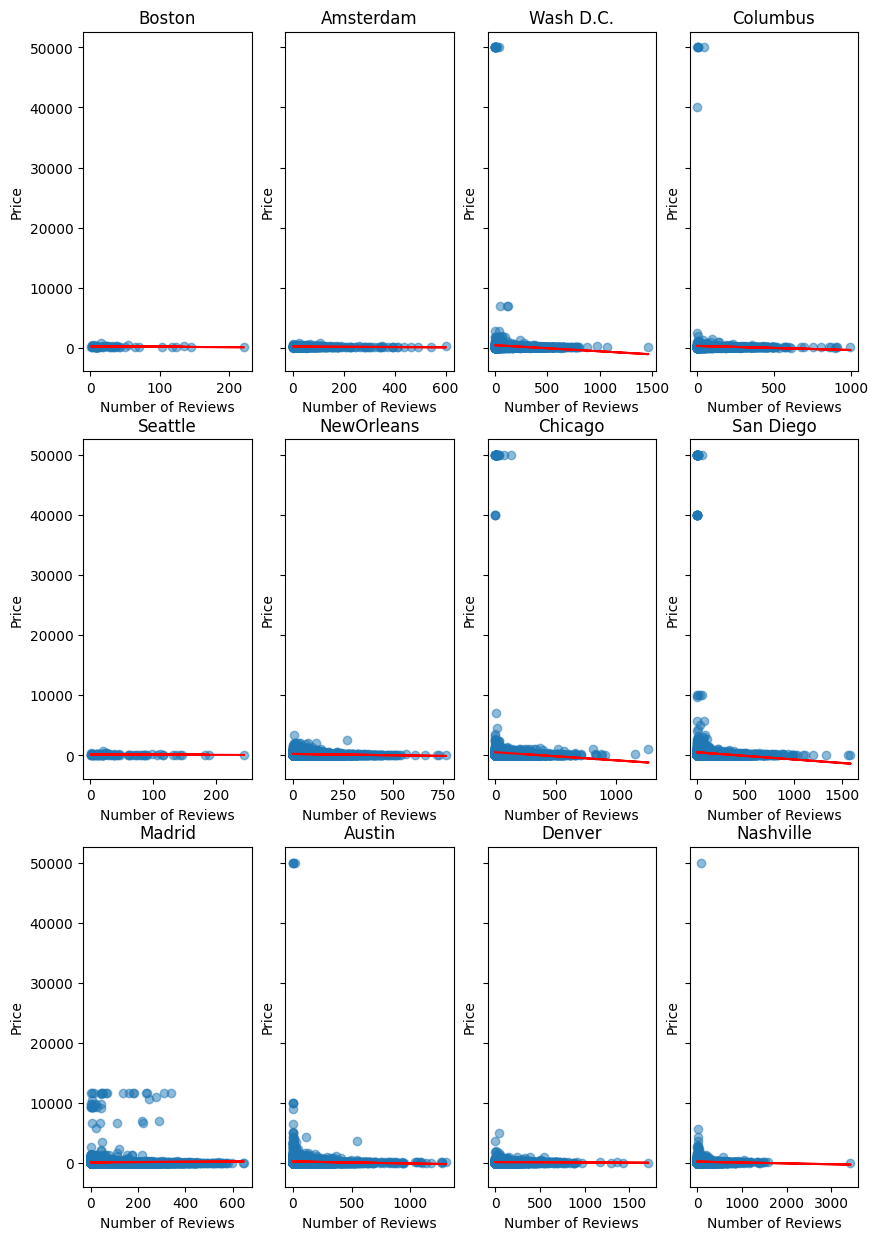

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import math
plt.figure(figsize=(10,30))

#Creates a function which fills an axis with a reviews vs. price scattter plot
def plot_reviews_vs_price(df, city_name, axis):
    x = df['number_of_reviews']
    y = df['price']


    axis.scatter(x, y, alpha=0.5)

    #Fits a one-degree polynomial (i.e. linear regression)
    m, b = np.polyfit(x, y, 1)
    axis.plot(x, m*x + b, color='red')

    #equation = f"y = {m:.2f}x + {b:.2f}"
    #axis.text(
    #    0.05, 0.95, equation,
    #    transform=plt.gca().transAxes,
    #    fontsize=10,
    #    verticalalignment='top'
    #)

    #Sets metadata about our plot
    axis.set_title(f"{city_name}")
    axis.set_xlabel("Number of Reviews")
    axis.set_ylabel("Price")

# All the code does below is iterate through each of our databases so that we can get the figure in one single set of subplots
num_rows = 3
num_columns = math.ceil(len(databases_with_price) / num_rows)
fig, ax = plt.subplots(num_rows,num_columns, sharey = True, figsize = (10, 15))
for i, tup in enumerate(databases_with_price):
  plot_reviews_vs_price(tup[1], tup[0], ax[i % (num_rows)][i // num_rows])

plt.show()



Average review ratings vs. price

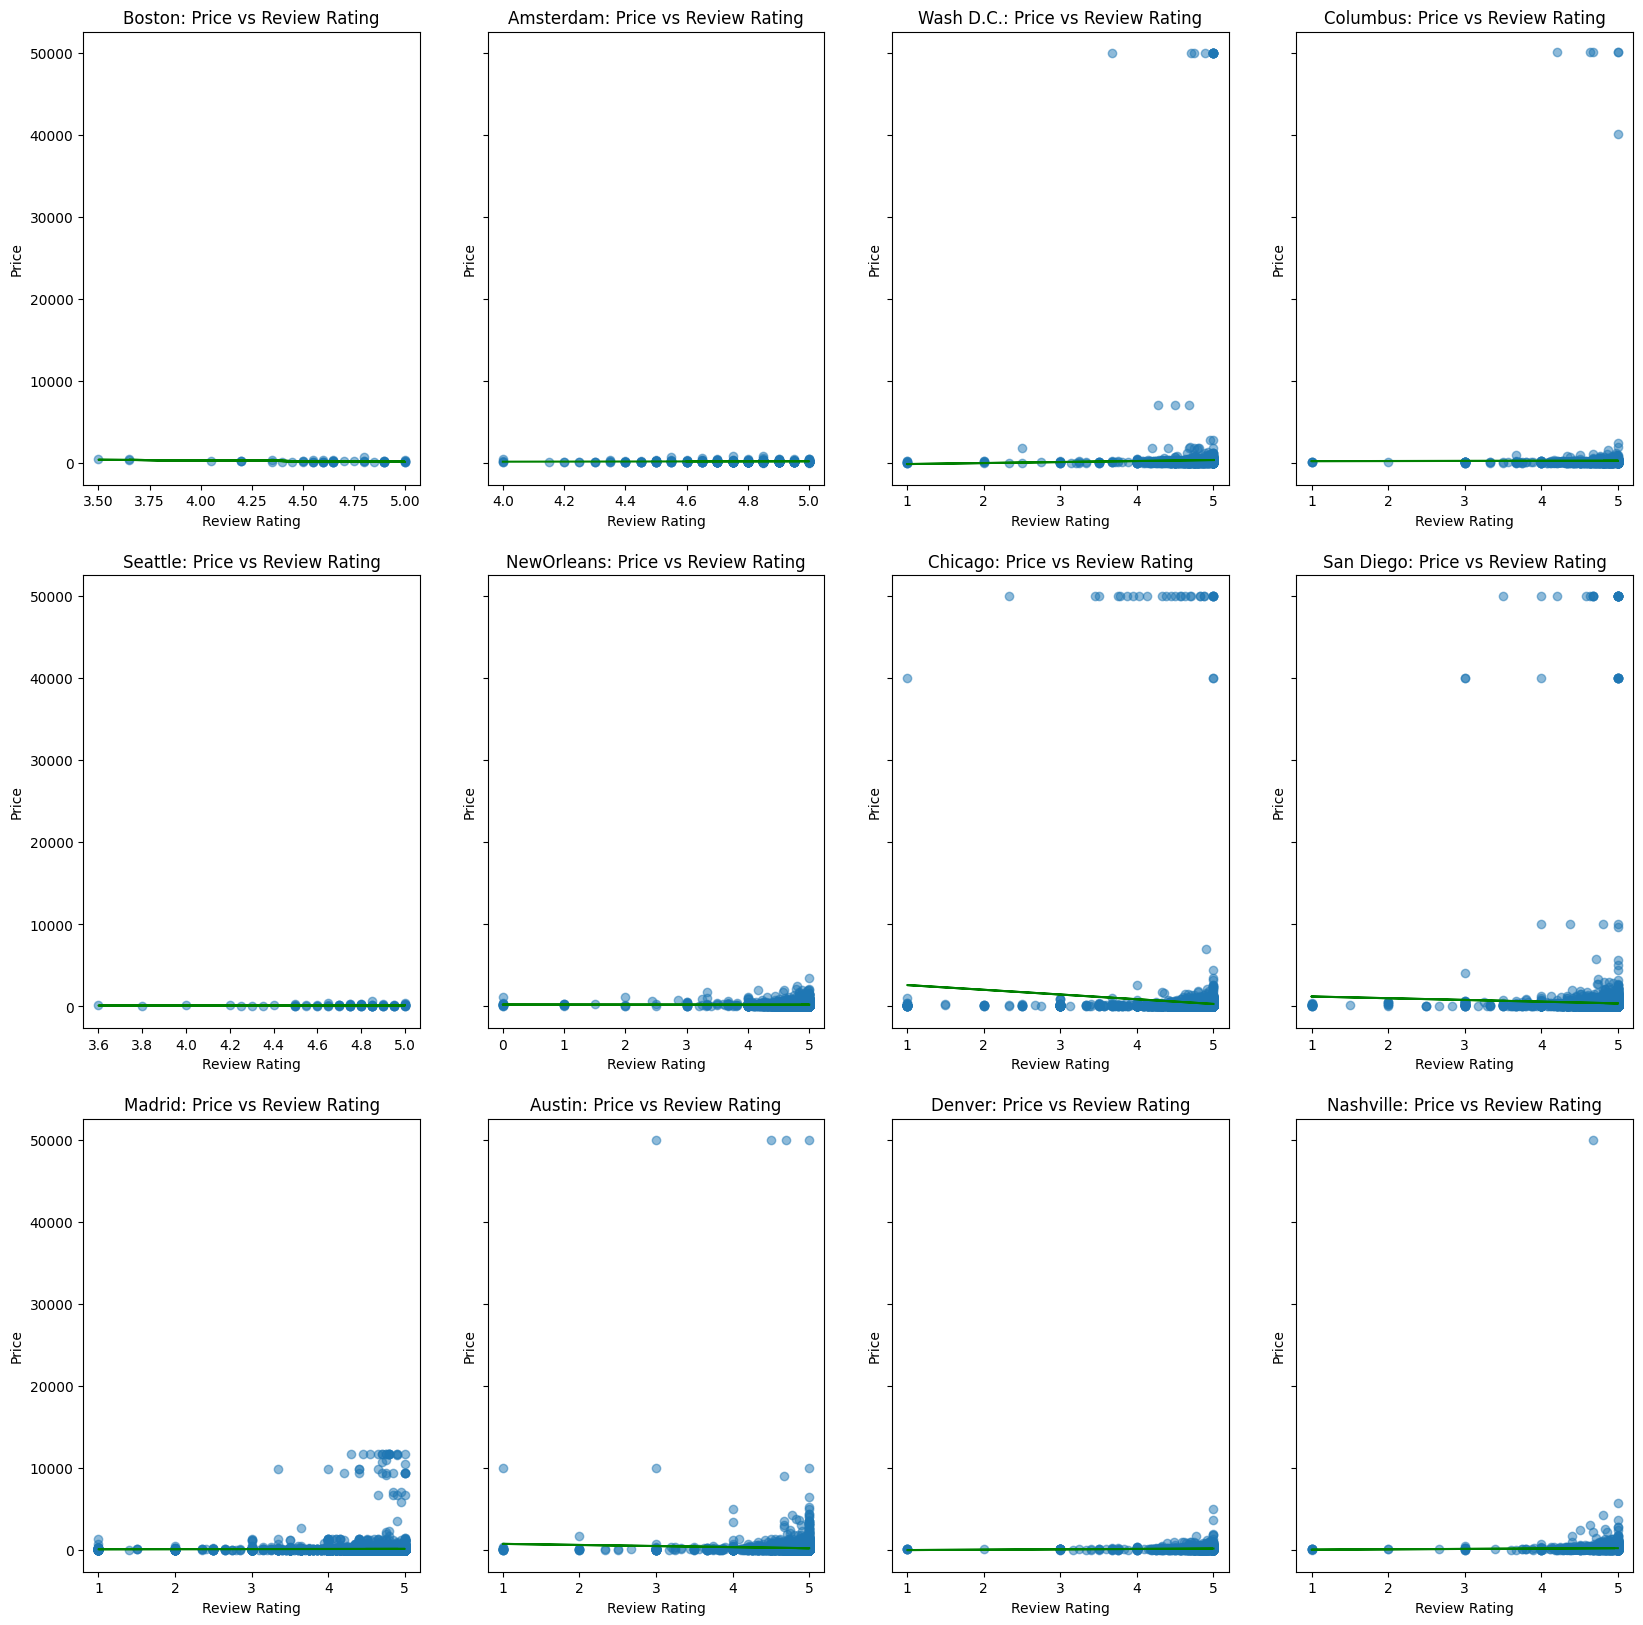

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

#Function which populates an axis with a review_scores vs. price scatter plot
def plot_rating_vs_price(df, city_name, axis):
    x = df['review_scores_rating']
    y = df['price']

    mask = x.notna() & y.notna()
    x = x[mask]
    y = y[mask]

    #plt.figure(figsize=(8,5))

    axis.scatter(x, y, alpha=0.5)


    #Graphs a line of best fit over data
    m, b = np.polyfit(x, y, 1)
    axis.plot(x, m*x + b, color='green')

    #equation = f"y = {m:.2f}x + {b:.2f}"
    #axis.text(
    #    0.05, 0.95, equation,
    #    transform=plt.gca().transAxes,
    #    fontsize=10,
    #    verticalalignment='top'
    #)


    #Sets metadata about plot
    axis.set_title(f"{city_name}: Price vs Review Rating")
    axis.set_xlabel("Review Rating")
    axis.set_ylabel("Price")

# All the code does below is iterate through each of our databases so that we can get the figure in one single set of subplots
num_rows = 3
num_columns = math.ceil(len(databases_with_price) / num_rows)
fig, ax = plt.subplots(num_rows,num_columns, sharey = True, figsize = (20, 20))
for i, tup in enumerate(databases_with_price):
  plot_rating_vs_price(tup[1], tup[0], ax[i % (num_rows)][i // num_rows])

plt.show()


Number of bedrooms and bathrooms vs. Price

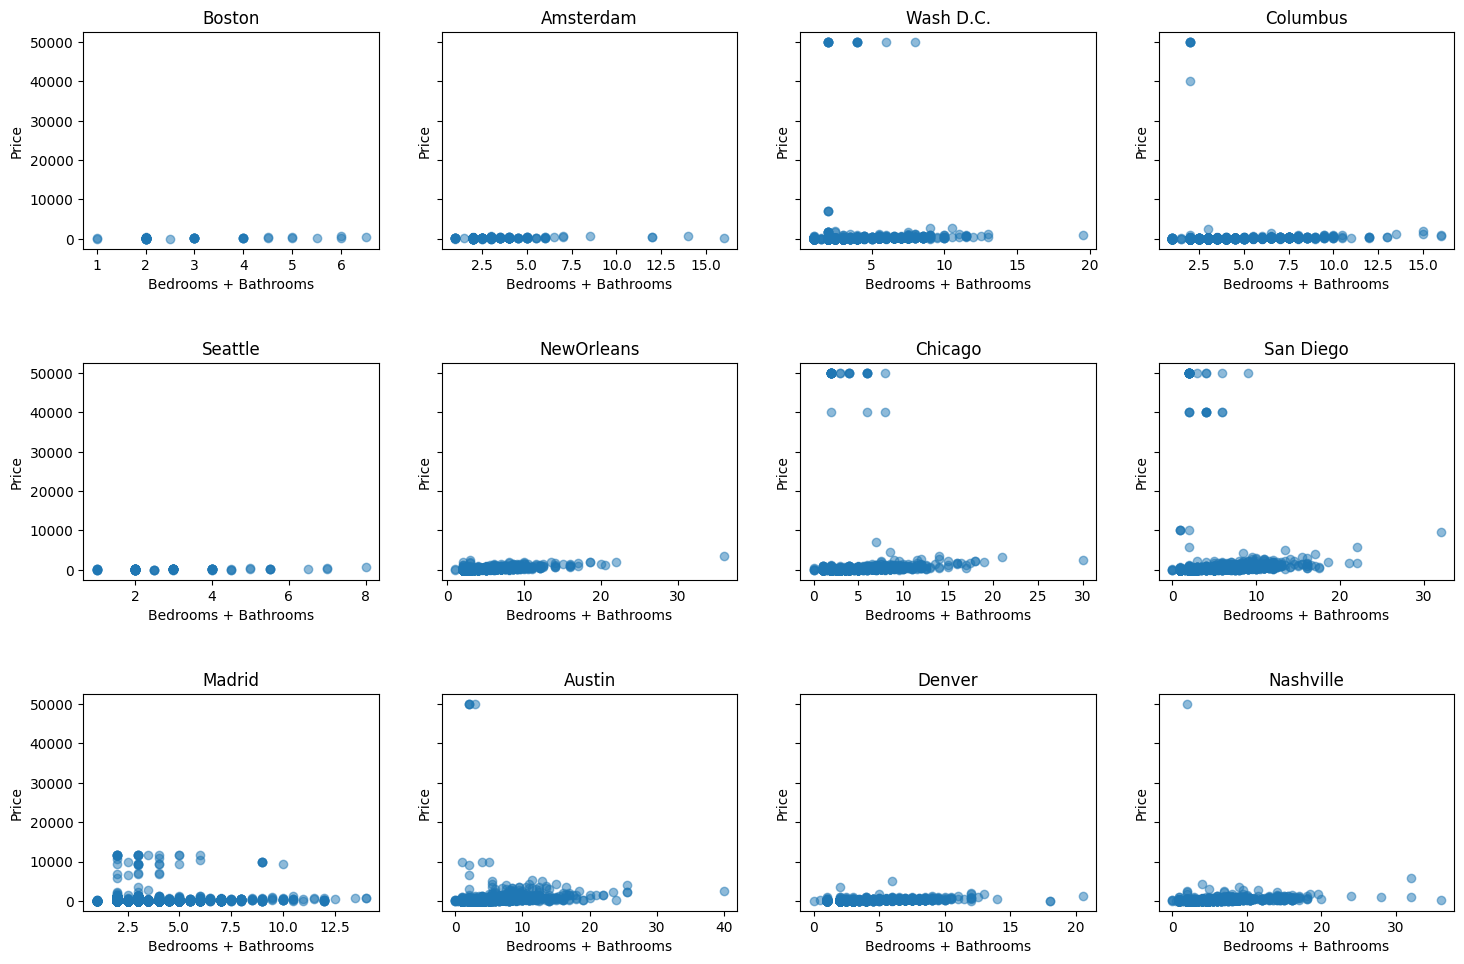

In [ ]:

#function for populating an axis with a actual vs. predicted price
# To do this - uses a linear regression on the features 'bathrooms' and 'bedrooms'
def plot_multilinear_price(df, city_name, axis):
    df = df.copy()

    df['bedrooms'] = pd.to_numeric(df['bedrooms'], errors='coerce')
    df['bathrooms'] = pd.to_numeric(df['bathrooms'], errors='coerce')
    df['price'] = pd.to_numeric(df['price'], errors='coerce')

    #Ensures we don't have any lingering null values in these plots
    df = df.dropna(subset=['bedrooms', 'bathrooms', 'price'])

    #Ensures our data actually is a numeric type
    X1 = df['bedrooms'].values.astype(float)
    X2 = df['bathrooms'].values.astype(float)
    y = df['price'].values.astype(float)


    X = np.column_stack((np.ones(len(X1)), X1, X2))

    beta = np.linalg.lstsq(X, y, rcond=None)[0]
    b0, b1, b2 = beta

    y_pred = b0 + b1*X1 + b2*X2

    #plt.figure(figsize=(8,5))
    axis.scatter(y, y_pred, alpha=0.5)

    axis.plot([y.min(), y.max()], [y.min(), y.max()], color='red')

    #equation = f"price = {b0:.2f} + {b1:.2f}*bed + {b2:.2f}*bath"

    #axis.text(
    #    0.05, 0.95,
    ##    equation,
    #    transform=plt.gca().transAxes,
    #    fontsize=10,
    #    verticalalignment='top'
    #)

    axis.set_title(f"{city_name}: Actual vs Predicted Price")
    axis.set_xlabel("Actual Price")
    axis.set_ylabel("Predicted Price")

# NOTE - the function above plots instead an actual vs. predicted price
#        based on a linear regression with number of rooms as predictor
#
# However, I have opted to instead use the below function which just gives us a
#  base plot of number of rooms vs price


#Populates an axis with bathrooms + bedrooms vs. price scatter plot
def plot_bathroomsbedrooms_vs_price(df, city_name, axis):
    #Adds together number of bedrooms + bathrooms, as a single Series
    x = df['bathrooms'].astype(float) + df['bedrooms'].astype(float)
    y = df['price']


    axis.scatter(x, y, alpha=0.5)

    #m, b = np.polyfit(x, y, 1)
    #axis.plot(x, m*x + b, color='red')

    #equation = f"y = {m:.2f}x + {b:.2f}"
    #axis.text(
    #    0.05, 0.95, equation,
    #    transform=plt.gca().transAxes,
    #    fontsize=10,
    #    verticalalignment='top'
    #)

    axis.set_title(f"{city_name}")
    axis.set_xlabel("Bedrooms + Bathrooms")
    axis.set_ylabel("Price")

# All the code does below is iterate through each of our databases so that we can get the figure in one single set of subplots
num_rows = 3
num_columns = 4
fig, ax = plt.subplots(num_rows,num_columns, sharey = True, figsize = (15, 10))
for i, tup in enumerate(databases_with_price):
  city = tup[0]
  df = tup[1]
  plot_bathroomsbedrooms_vs_price(df, city, ax[i % (num_rows)][i // num_rows])

plt.tight_layout(pad=2.0, h_pad=3.5, w_pad=2.5)
plt.show()



**Takeaways so far**:

The data seems to have *a lot* of outliers in the price feature - so much so that it is hard to understand what trend (if any occurs in the data between different variables). Moreover, the price feature itself is a bit odd - one would assume that the price is telling you the price of a single night's stay at a given listing. However, given that some prices for places like Colombus approach up to $50000, it is reasonable to guess that perhaps price is actually computing something a bit more complicated.

Our guess was initially that price was telling you the price of a **minimum stay**  - that is, it would by the nightly price * the minimum number of stays + cleaning fees - or something similar to this. To test this, we decided to plot price vs. minimum number of nights of stay required. If price is actually doing a computation above, then there would be a clear linear relation between minimum number of nights and price.

Price vs Min number of nights (To see if the price is implicitly taking this into account)

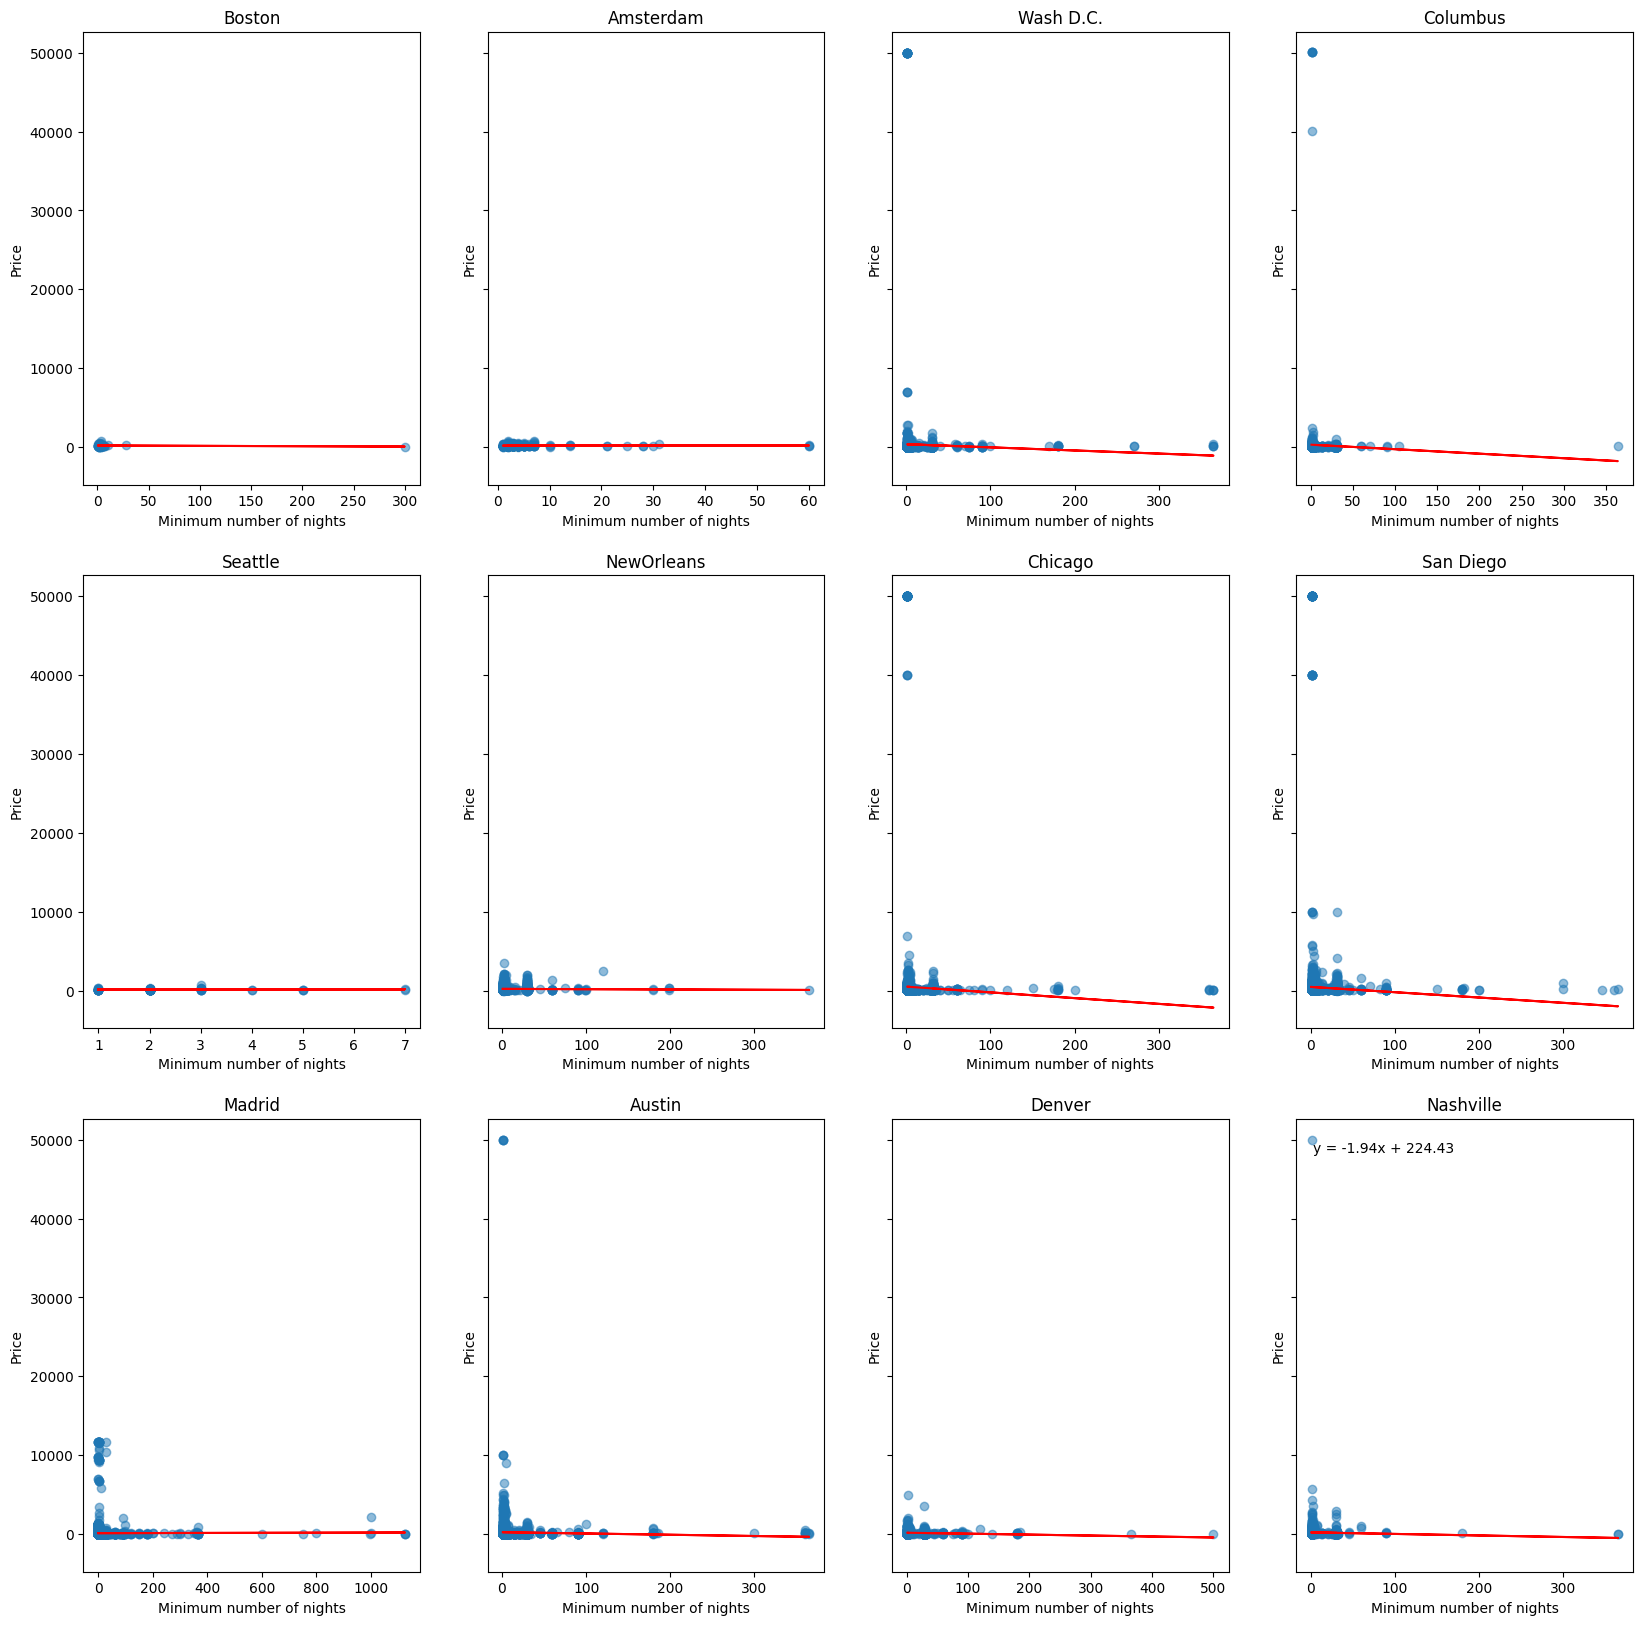

In [ ]:
#Function that populates a given axis with minimum nights vs price scatter plot
def plot_min_nights_vs_price(df, city_name, axis):
    x = df['minimum_nights']
    y = df['price']


    axis.scatter(x, y, alpha=0.5)

    #Fits line of best fit to the data and plots it
    m, b = np.polyfit(x, y, 1)
    axis.plot(x, m*x + b, color='red')

    #Metadata about parameters for linear regression computed above
    #Code below attaches this to our graph
    equation = f"y = {m:.2f}x + {b:.2f}"
    axis.text(
        0.05, 0.95, equation,
        transform=plt.gca().transAxes,
        fontsize=10,
        verticalalignment='top'
    )

    #Metadata about plot
    axis.set_title(f"{city_name}")
    axis.set_xlabel("Minimum number of nights")
    axis.set_ylabel("Price")

# All the code does below is iterate through each of our databases so that we can get the figure in one single set of subplots
num_rows = 3
num_columns = math.ceil(len(databases_with_price) / num_rows)
fig, ax = plt.subplots(num_rows,num_columns, sharey = True, figsize = (20, 20))
for i, tup in enumerate(databases_with_price):
  plot_min_nights_vs_price(tup[1], tup[0], ax[i % (num_rows)][i // num_rows])

plt.show()



Price vs Property type

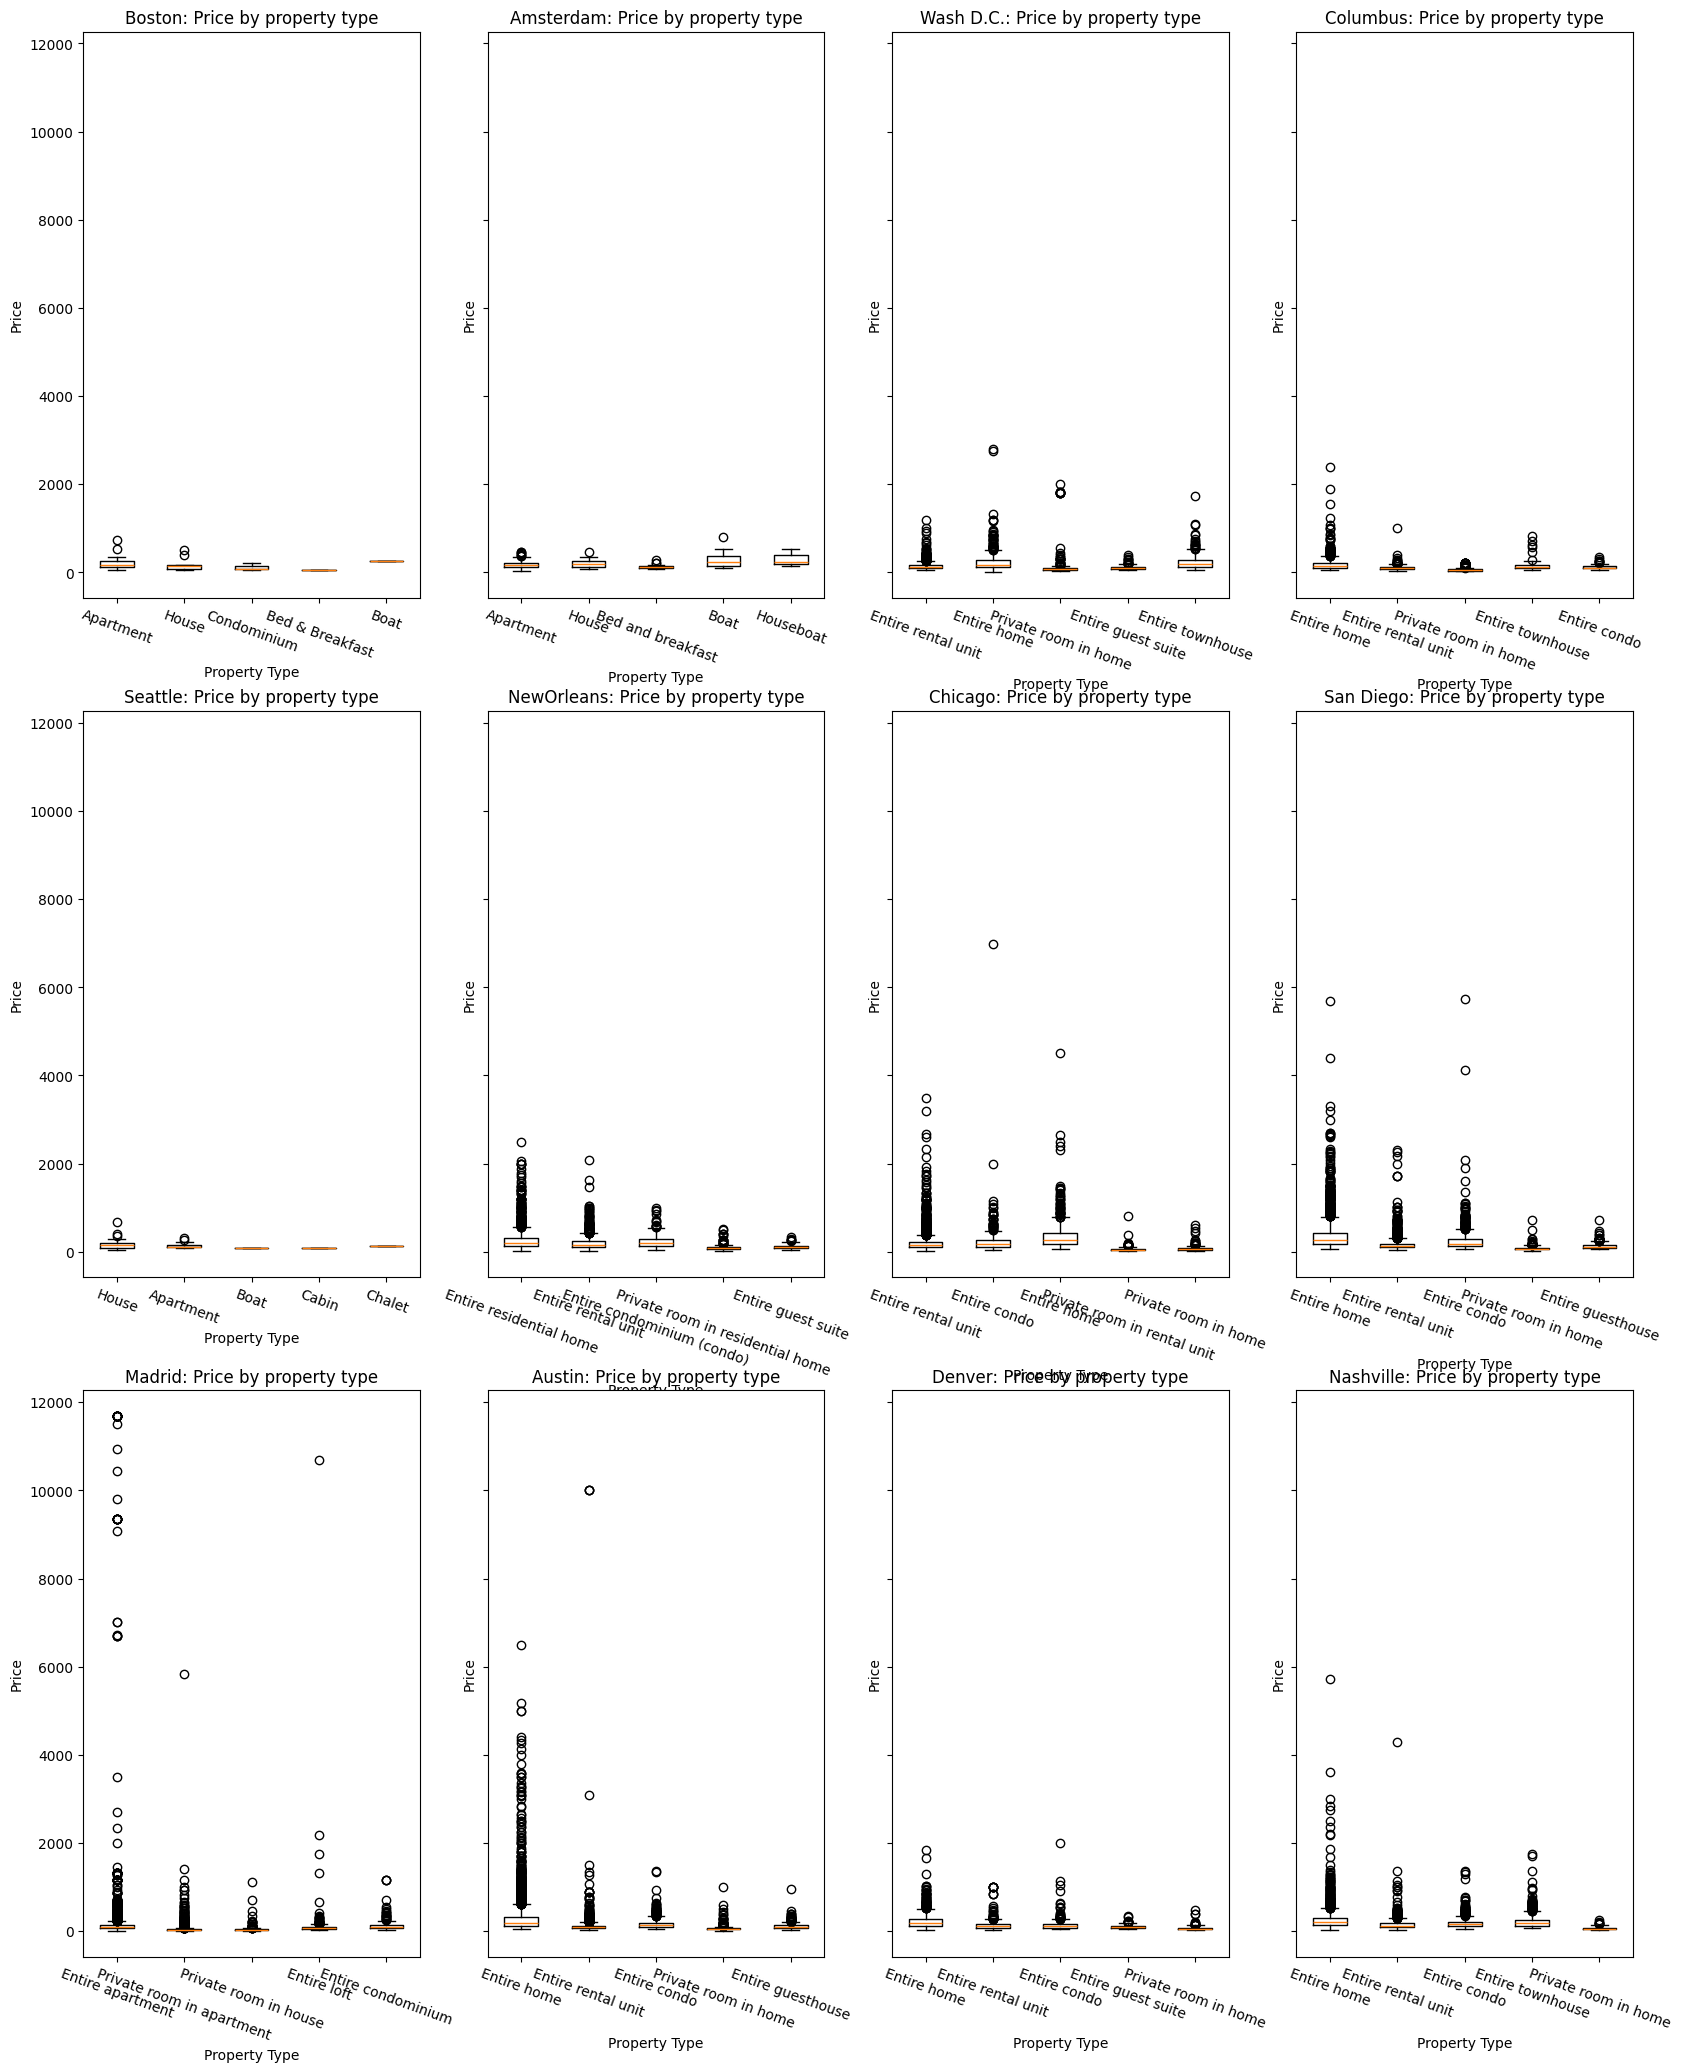

In [ ]:
## TODO - ADJUST VERTICAL MARGINS ON THESE GRAPHS



#Function which populates a given axis with property_type vs price box & whiskers plot
def price_by_prop_type(df, city, axis):


  # Compute top 5 most common property types from each of our dataframes
  property_types = df['property_type'].value_counts().iloc[0:5].index.tolist()
  price_list = []
  medians = []

  #Collect price data for each of these property types
  for prop in property_types:
    price_arr = (df.loc[df['property_type'] == prop])['price'].to_numpy()
    price_list.append(price_arr)
    medians.append(np.median(price_arr))

  #Draws boxplots, using our computed medians for our set of data
  axis.boxplot(price_list, tick_labels = property_types, usermedians = medians)

  axis.set_title(f"{city}: Price by property type")
  axis.set_xlabel("Property Type")
  axis.set_ylabel("Price")
  axis.tick_params(axis='x', labelrotation=-20)

#Splits up different cities into different subplots
num_rows = 3
num_columns = math.ceil(len(databases_with_price) / num_rows)
fig, ax = plt.subplots(num_rows,num_columns, sharey = True, figsize = (20, 25))

#Iterates though cities, and plots relevant dataframes
for i, tup in enumerate(databases_with_price):
  price_by_prop_type(tup[1], tup[0], ax[i % (num_rows)][i // num_rows])
#plt.xticks(rotation=30)
plt.show()


### Main takeaways from analysis of figures:
- The outliers in price seem to be a HUGE issue (Just look at how many there are in the box plots above - any point that's plotted is a point which lies ABOVE 1.5 IQR (interquartile range) + 75th percentile point of data
   - Moreover, I'd be willing to bet those outlier prices are simply not correct (There is no possible way that an airbnb is going for a price of ~10000 a night)
   - Additionally, the outliers must be handled separately by city - in chicago outliers go upwards of \$50000, yet in Madrid, they only go up to around \$10000
   - (Initially, my guess was that listed price was implicitly using minimum nights (e.g. price = price_per_night * minimum_nights + fees) but clearly the 3rd plot says otherwise)
- There is something weird going in with prices in Madrid - all of them seem to cap out around 10000
- Although most common property types seem to vary by city, there appears to be a consistent trend where "entire home" or "entire condo" or "entire apt" will be the more expensive option

## 1.4 - Handling outliers and regional price differences

For each of our datasets, price might be in a different currency dependending on location. Moreover, even for multiple cities in the same country, the price might not have the same meaning. For example, a $200 a night rental in New york city would likely be closer to average than the same listing would be in New Orleans. Therefore, it would be a good to have an adjusted dataset for each of these places which:
   - throws away any price listings which are above the 97.5 or below the 2.5 percentile (getting rid of outliers)
   - Calculates average price of rental based on city
   - adds a row showing how many standard deviations the price falls away from the mean (this will be useful because it is invariant of currency)

### 1.4.1 - Computing 97.5 / 2.5 percentiles & dropping values

In [ ]:
databases_no_outliers = []

#Iterate through dataframes - but just those with a price feature
for i, tup in enumerate(databases_with_price):
  df = tup[1]
  price_arr = df['price'].to_numpy()

  #Compute our cutoffs - any data above/below these points will be considered outliers, and not included
  highPriceCutoff = np.quantile(price_arr, 0.95)
  lowPriceCutoff = np.quantile(price_arr, 0.05)

  #Compute number of outliers
  highOutliers = np.sum(price_arr > highPriceCutoff)
  lowOutliers = np.sum(price_arr < lowPriceCutoff)


  print(f'Outlier count for {tup[0]}')
  print(f'95th percentile cutoff = {highPriceCutoff} and exists {highOutliers} high outliers')
  print(f'5th percentile cutoff = {lowPriceCutoff} and exists {lowOutliers} low outliers\n\n')

  #filter dataframe to lie between our cutoff thresholds
  dfNoOutliers = df.loc[(df['price'] < highPriceCutoff) & (df['price'] > lowPriceCutoff), :]
  #Adds filtered dataframe to a new list
  databases_no_outliers.append(dfNoOutliers)



Outlier count for Boston
95th percentile cutoff = 439.9999999999999 and exists 3 high outliers
5th percentile cutoff = 61.2 and exists 3 low outliers


Outlier count for Seattle
95th percentile cutoff = 287.99999999999983 and exists 5 high outliers
5th percentile cutoff = 60.0 and exists 3 low outliers


Outlier count for Madrid
95th percentile cutoff = 243.02720000000002 and exists 632 high outliers
5th percentile cutoff = 21.031200000000002 and exists 547 low outliers


Outlier count for Amsterdam
95th percentile cutoff = 350.52000000000004 and exists 18 high outliers
5th percentile cutoff = 88.2142 and exists 20 low outliers


Outlier count for NewOrleans
95th percentile cutoff = 590.0500000000002 and exists 255 high outliers
5th percentile cutoff = 63.0 and exists 254 low outliers


Outlier count for Austin
95th percentile cutoff = 630.0 and exists 442 high outliers
5th percentile cutoff = 44.0 and exists 435 low outliers


Outlier count for Wash D.C.
95th percentile cutoff = 375.0

### 1.4.2 -  Retesting some of our graphs w/o outliers



Num bathrooms + bedrooms vs price

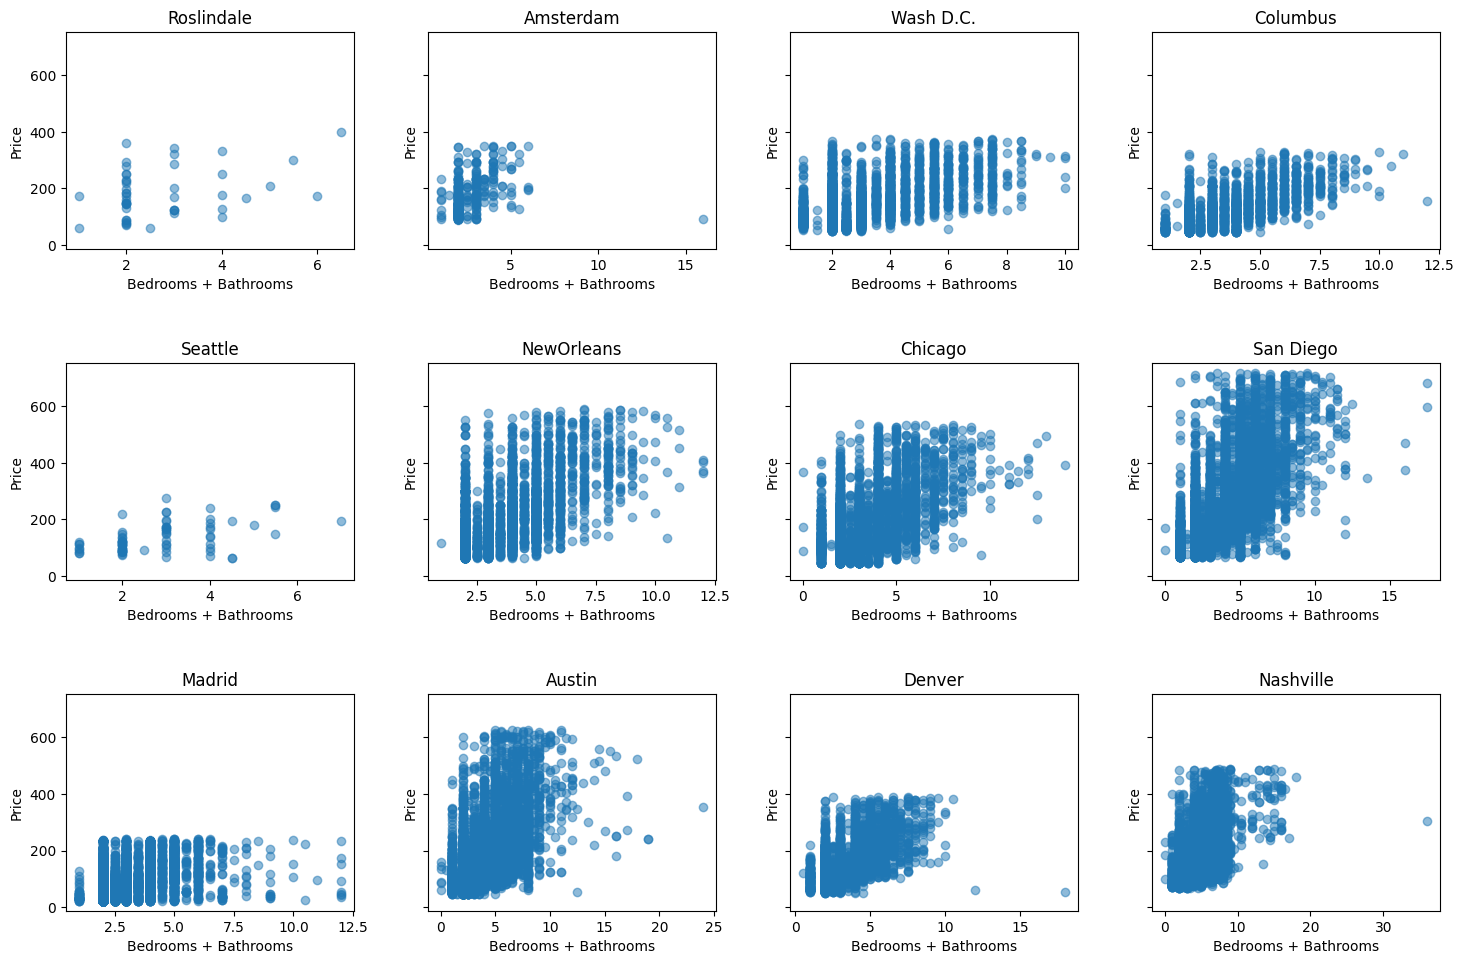

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import math

#Repeats the same function as previously implemented
def plot_bathroomsbedrooms_vs_price(df, city_name, axis):
    x = df['bathrooms'].astype(float) + df['bedrooms'].astype(float)
    y = df['price']


    axis.scatter(x, y, alpha=0.5)

    #m, b = np.polyfit(x, y, 1)
    #axis.plot(x, m*x + b, color='red')

    #equation = f"y = {m:.2f}x + {b:.2f}"
    #axis.text(
    #    0.05, 0.95, equation,
    #    transform=plt.gca().transAxes,
    #    fontsize=10,
    #    verticalalignment='top'
    #)

    axis.set_title(f"{city_name}")
    axis.set_xlabel("Bedrooms + Bathrooms")
    axis.set_ylabel("Price")

# All the code does below is iterate through each of our databases so that we can get the figure in one single set of subplots
num_rows = 3
num_columns = 4
fig, ax = plt.subplots(num_rows,num_columns, sharey = True, figsize = (15, 10))
for i, df in enumerate(databases_no_outliers):
  city = df['city'].iloc[0]
  plot_bathroomsbedrooms_vs_price(df, city, ax[i % (num_rows)][i // num_rows])

plt.tight_layout(pad=2.0, h_pad=3.5, w_pad=2.5)
plt.show()

#
#plot_reviews_vs_price(LimitedSeattleDf, "Seattle")
#  plot_reviews_vs_price(LimitedBostonDf, "Boston")
#  plot_reviews_vs_price(LimitedMadridDf, "Madrid")
#  plot_reviews_vs_price(LimitedNewOrleansDf, "New Orleans")
#  plot_reviews_vs_price(LimitedAmsterdamDf, "Amsterdam")


Good news - there is a much more visible trend with the data now!
Thus, we continue to re-generate some of the previous visualizations

Price by property type

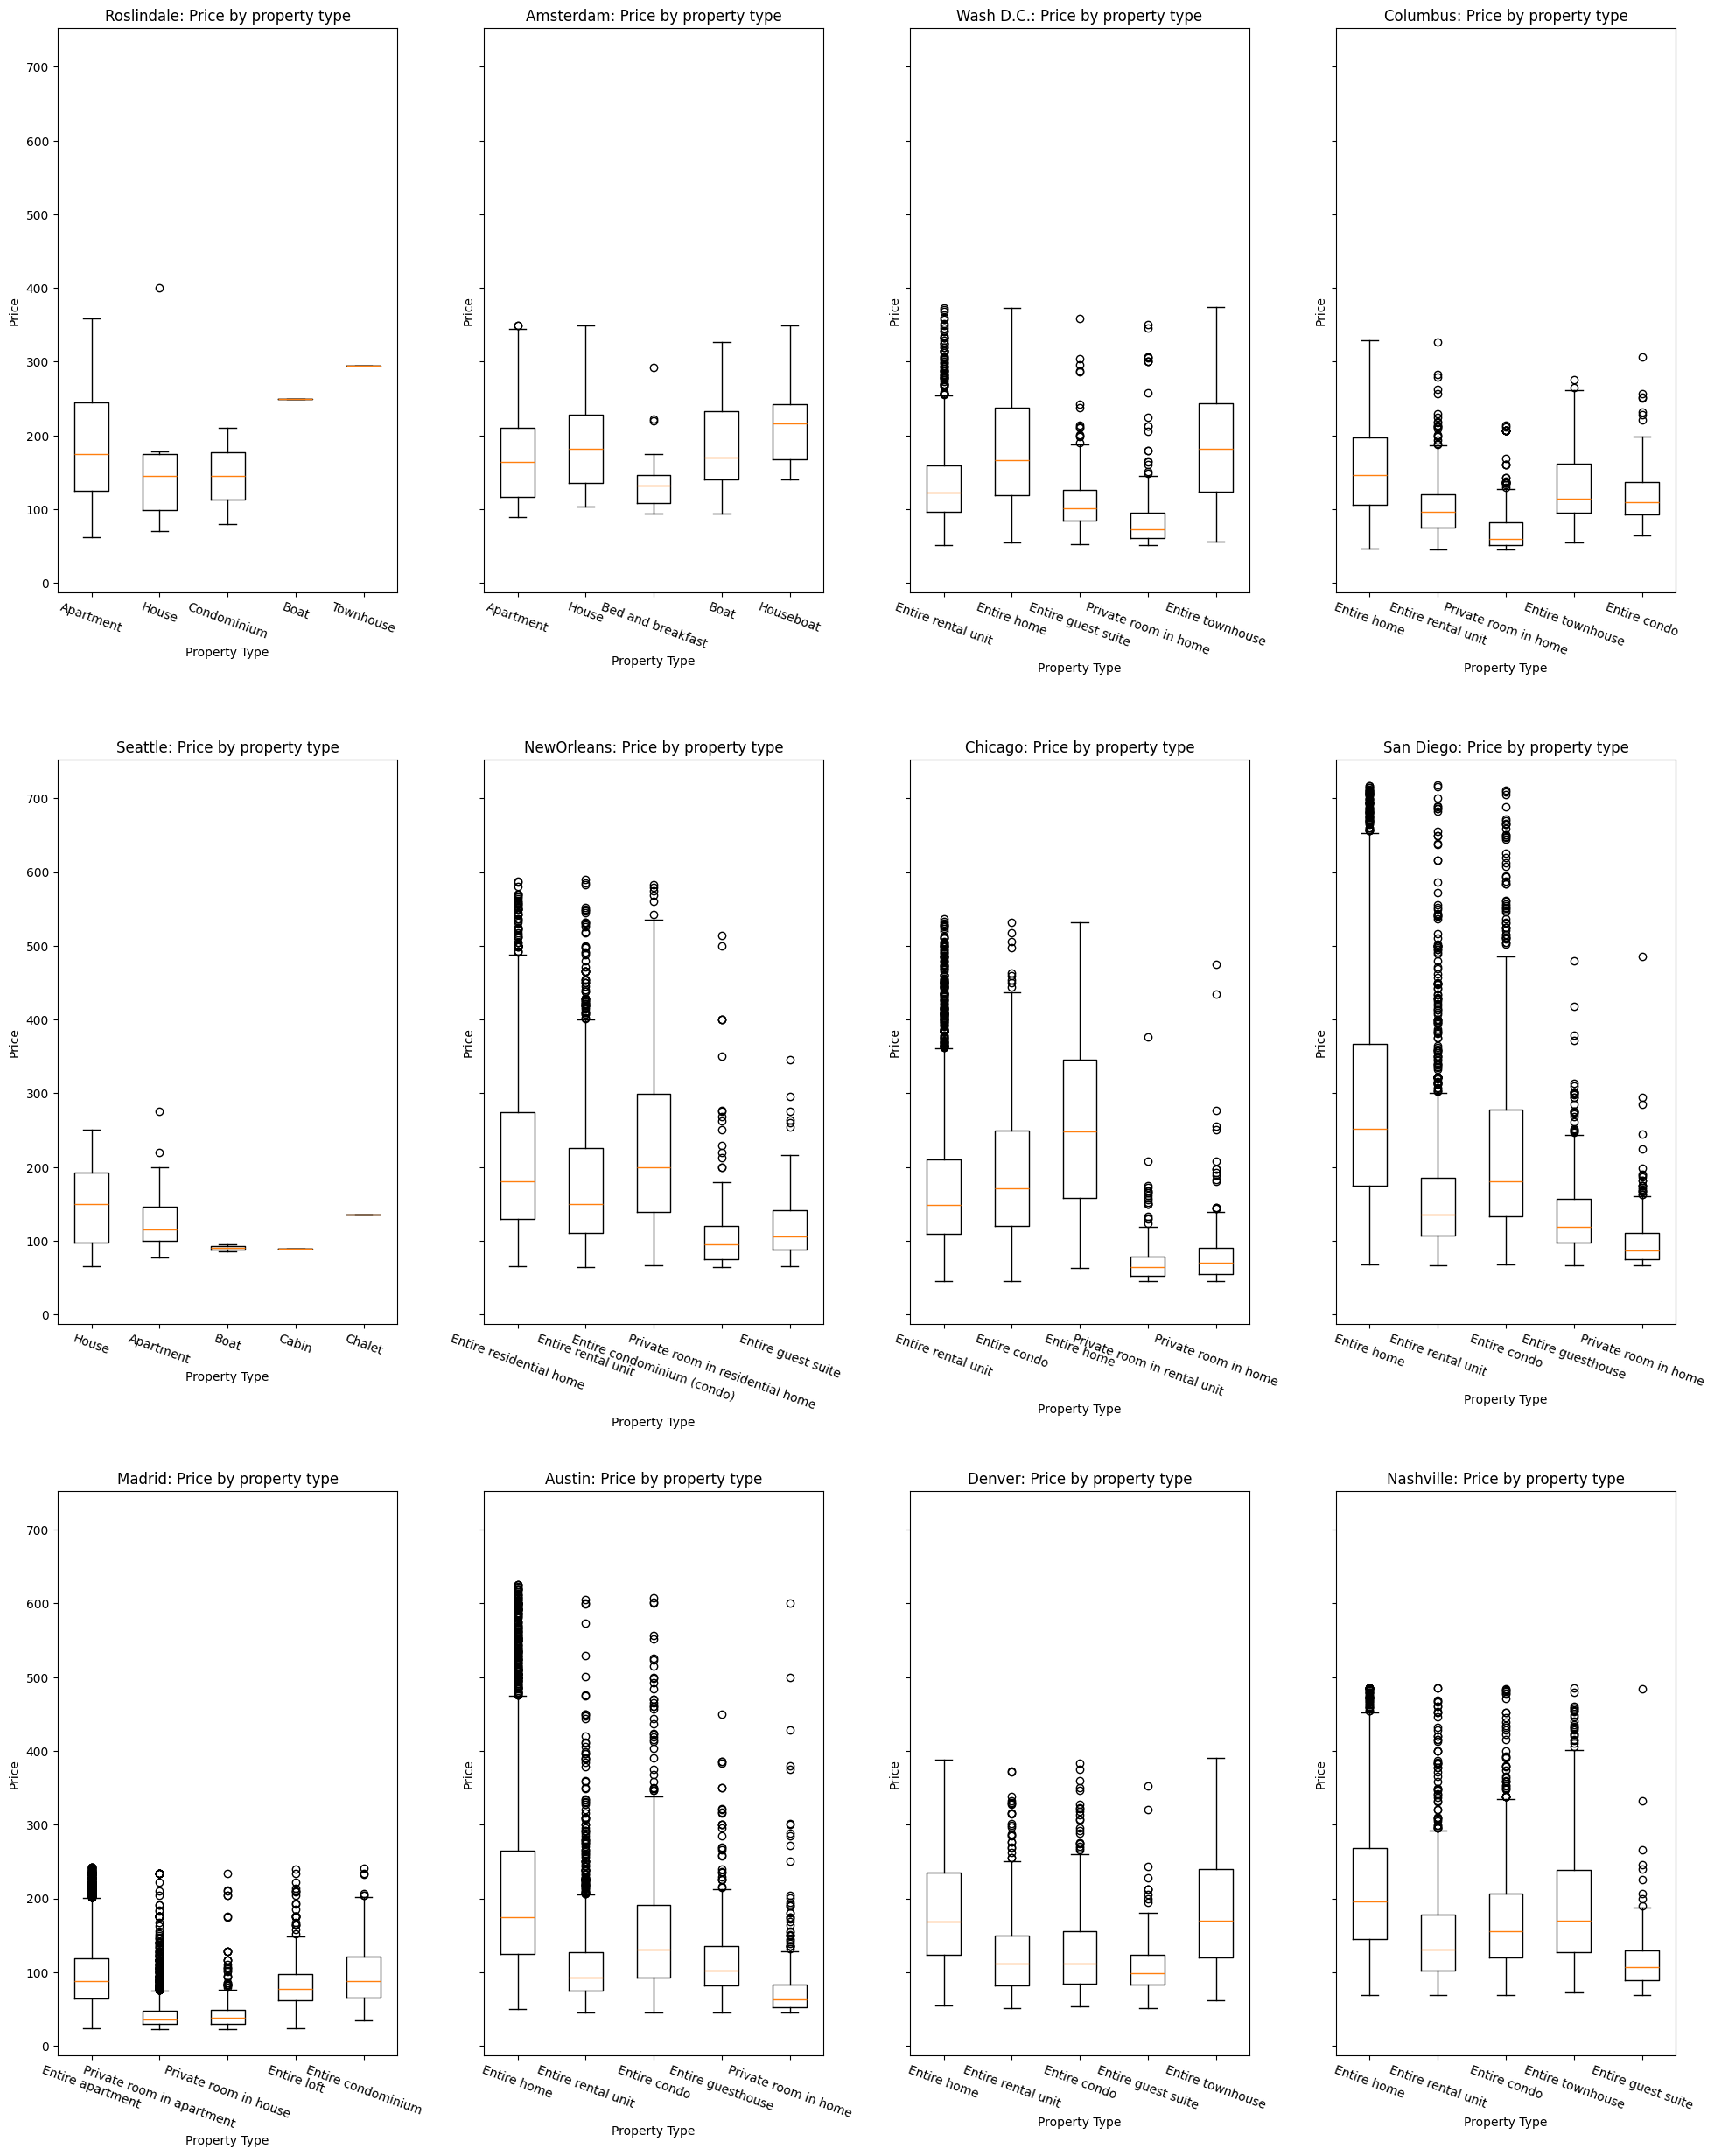

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

#Determines how many rows / columns we need of subplots in order
# to fit all the cities from our list of dataframes
num_rows = 3
num_columns = math.ceil(len(databases_no_outliers) / num_rows)

#Creates new set of subplots
fig, ax = plt.subplots(num_rows,num_columns, sharey = True, figsize = (20, 25))

#iterates through dataframes which are now filtered to exclude outliers
for i, df in enumerate(databases_no_outliers):
  city = df['city'].iloc[0]
  #calls a previous function, which populates a given axis with a
  # scatter plot of bedrooms + bathrooms vs. price
  price_by_prop_type(df, city, ax[i % (num_rows)][i // num_rows])

plt.tight_layout(pad=2.0, h_pad=3.5, w_pad=2.5)
plt.show()


Ok, still no clear coorelation - but at least the figures look a little better than they did previously

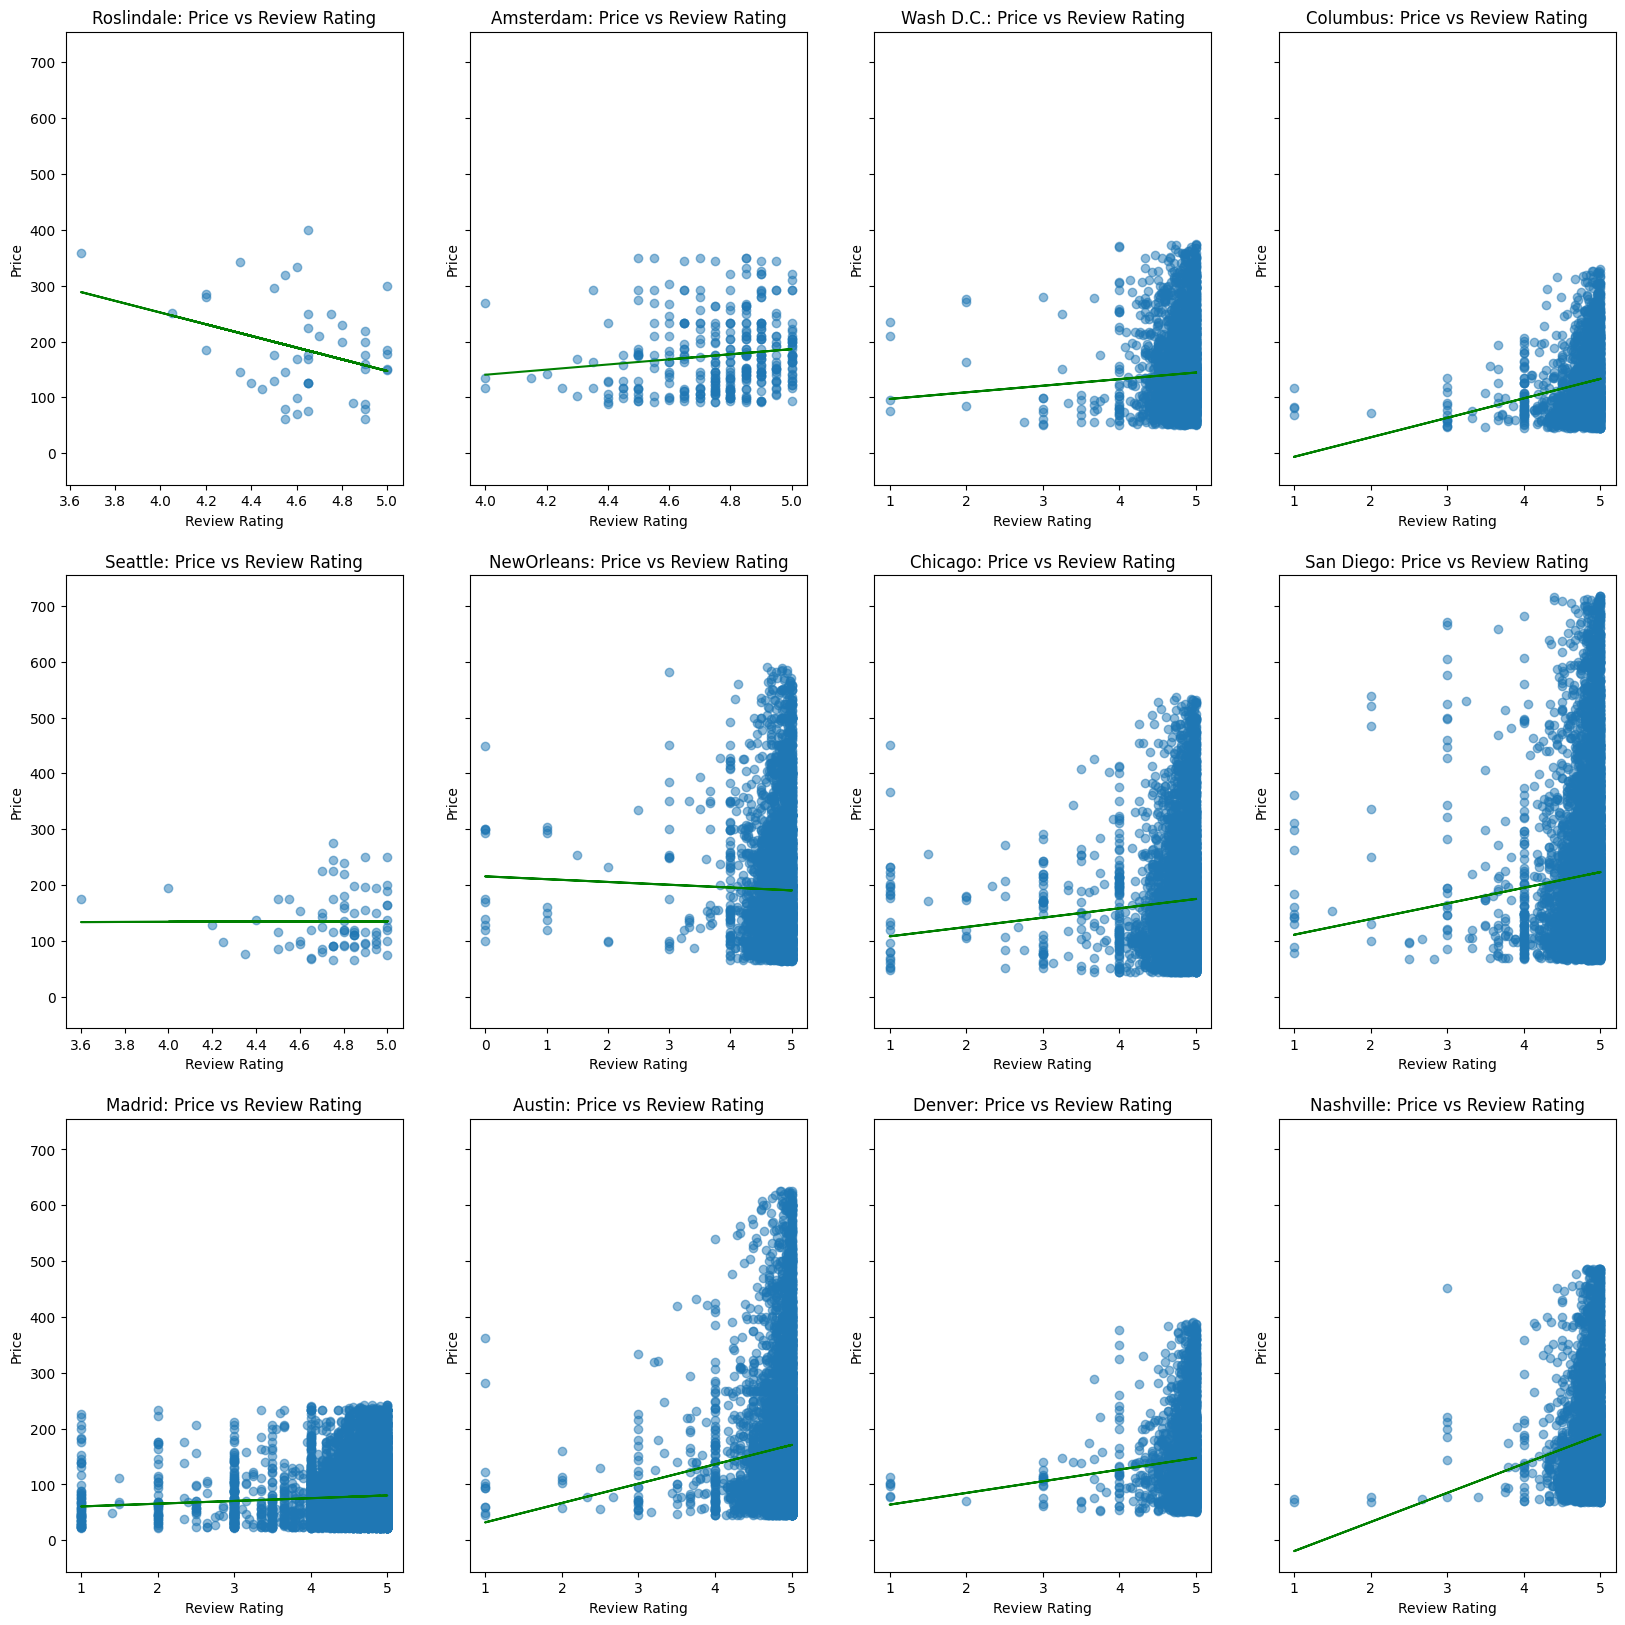

In [ ]:
#Determines number of rows/ columns of subplots
num_rows = 3
num_columns = math.ceil(len(databases_no_outliers) / num_rows)

#Creates new set of subplots and figure
fig, ax = plt.subplots(num_rows,num_columns, sharey = True, figsize = (20, 20))

#Iterates through filtered dataframes
for i, df in enumerate(databases_no_outliers):
  city = df['city'].iloc[0]

  #calls a previous function, populating our subplot with
  # a scatter plot of review score vs price
  plot_rating_vs_price(df, city, ax[i % (num_rows)][i // num_rows])

plt.show()

Number of reviews vs review scores (do those who airbnb frequently tend to have higher review ratings?)

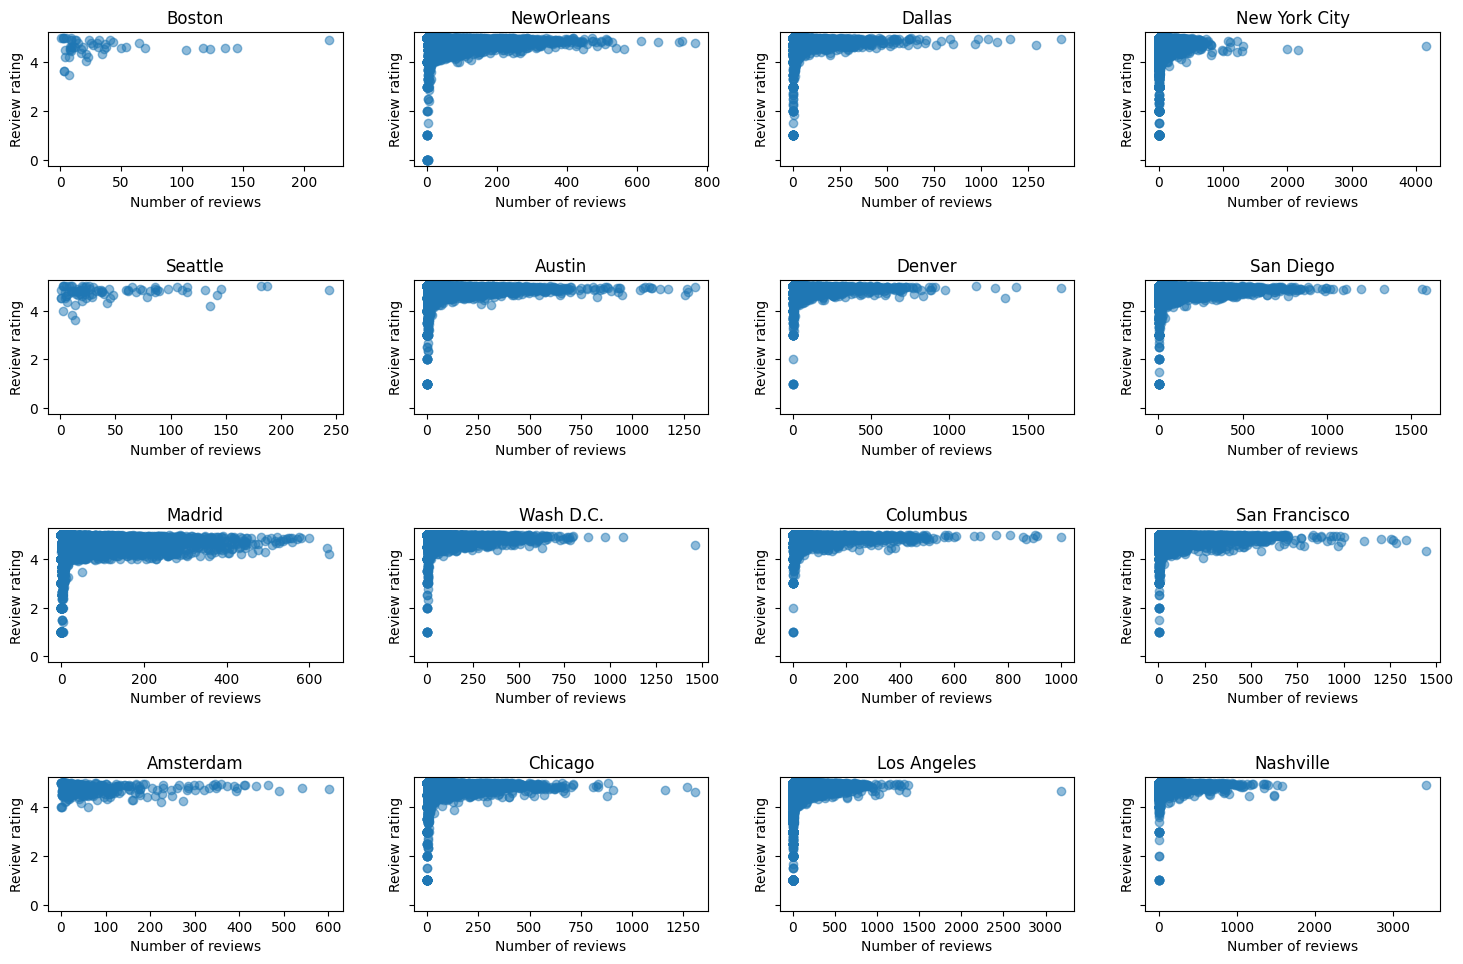

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import math

#New function, which populates an axis with scatter plot of number of reviews vs. review scores
def plot_numreviews_vs_scores(df, city_name, axis):
    x = df['number_of_reviews']
    y = df['review_scores_rating']


    axis.scatter(x, y, alpha=0.5)

    #m, b = np.polyfit(x, y, 1)
    #axis.plot(x, m*x + b, color='red')

    #equation = f"y = {m:.2f}x + {b:.2f}"
    #axis.text(
    #    0.05, 0.95, equation,
    #    transform=plt.gca().transAxes,
    #    fontsize=10,
    #    verticalalignment='top'
    #)

    axis.set_title(f"{city_name}")
    axis.set_xlabel("Number of reviews")
    axis.set_ylabel("Review rating")



# All the code does below is iterate through each of our databases so that we can get the figure in one single set of subplots

# This creates a 4x4 grid of subplots, instead of what we had been doing previously
num_rows = 4
num_cols = 4

#Creates new set of subplots
fig, ax = plt.subplots(num_rows,num_cols, sharey = True, figsize = (15, 10))

#Iterates through ALL dataframes (even those without a 'price' feature)
for i, tup in enumerate(databases_no_price):
  df = tup[1]
  city = tup[0]

  #calls function defined above to populate a given subplot
  plot_numreviews_vs_scores(df, city, ax[i % (num_rows)][i // num_rows])


plt.tight_layout(pad=2.0, h_pad=3.5, w_pad=2.5)
plt.show()


### Main takeaways
- For listings with low numbers of reviews, review rating will vary substantially
- However, it seems that having a high number of reviews limits this variance substantially, trending towards having a very positive review rating
- There seems to be no visible trend between price and reviews
- Bedrooms + bathrooms do not super closely follow a linear trend with price, however, it seems that in general, more bathrooms+bedrooms will tend to correspond to a more expensive listing
- Property type can also vary quite a bit in price, but as a general trend, property types with "Entire" in the name (e.g. 'Entire home', 'entire condo') tend to be more expensive

### 1.4.3 - Computing mean / standard deviation from mean

- If our goal is to combine all of our dataframes into one single dataframe for analysis, then it would be good if we could have some price feature which was 'region invariant' - hence we try to such a quantity by instead looking at how much a property varies from the mean property value within a given region

In [ ]:
# Iterate through dataframes which are filtered to exclude outliers
for i, df in enumerate(databases_no_outliers):

  #Save price series as a new variable
  new_price_arr = df['price'].to_numpy()

  #Compute, mean, standard deviation of the above series
  avg_price = np.mean(new_price_arr)
  std_dev = np.std(new_price_arr, mean = avg_price)

  #Create a new feature which is just a list of only one value
  # (the average price of an airbnb in a city)
  databases_no_outliers[i]['avg_price'] = np.round(avg_price, 2)

  #Create a new feature which computes how many standard deviations
  #  a given airbnb's price listing is away from the mean (BY CITY)
  databases_no_outliers[i]['std_devs'] = np.round((new_price_arr - avg_price) / std_dev, 2)

databases_no_outliers[4].head()

/tmp/ipykernel_2132/69861918.py:13: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  databases_no_outliers[i]['avg_price'] = np.round(avg_price, 2)
/tmp/ipykernel_2132/69861918.py:17: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  databases_no_outliers[i]['std_devs'] = np.round((new_price_arr - avg_price) / std_dev, 2)
/tmp/ipykernel_2132/69861918.py:13: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the ca

,id,property_type,room_type,accommodates,bathrooms_text,bedrooms,amenities,price,number_of_reviews,review_scores_rating,minimum_nights,city,bathrooms,avg_price,std_devs
0,19091,Entire rental unit,Entire home/apt,3,1 bath,1.0,"[""TV with standard cable"", ""Hair dryer"", ""Air ...",67.0,474,4.89,1,NewOrleans,1,191.66,-1.15
1,26834,Entire residential home,Entire home/apt,2,1 bath,1.0,"[""Air conditioning"", ""Refrigerator"", ""Essentia...",129.0,263,4.96,5,NewOrleans,1,191.66,-0.58
2,71624,Entire rental unit,Entire home/apt,2,1 bath,1.0,"[""TV with standard cable"", ""Hair dryer"", ""Air ...",130.0,242,4.94,3,NewOrleans,1,191.66,-0.57
3,74498,Entire rental unit,Entire home/apt,2,1 bath,1.0,"[""Air conditioning"", ""Refrigerator"", ""Essentia...",98.0,515,4.90,3,NewOrleans,1,191.66,-0.86
4,79536,Entire rental unit,Entire home/apt,2,1 bath,1.0,"[""Air conditioning"", ""Refrigerator"", ""Essentia...",72.0,519,4.86,3,NewOrleans,1,191.66,-1.10


#### Combining dataframes into one dataframe


In [ ]:
#Prepares a common set of features to join all of our dataframes
common_cols = ['property_type', 'room_type', 'accomodates', 'bedrooms', 'bathrooms', 'amenities', 'price', 'number_of_reviews', 'review_scores_rating', 'minimum_nights', 'city', 'avg_price', 'std_devs']

#Concatenates ALONG INDEX (i.e. we are 'vertically stacking' our dataframes)
total_df = pd.concat(databases_no_outliers, join='inner')

#Drops any left-over null values
total_df.dropna(inplace = True)
print("\nInfo about databases w/ price\n\n")
total_df.info()

#Prepares common set of features for dataframes which DO NOT have a price feature
common_cols.remove('price')

#Concatenates dataframes w/o price vertically (i.e. along index)
total_no_price_df = pd.concat([tup[1] for tup in databases_no_price], join = 'inner')
total_no_price_df.dropna(inplace = True)
print("\n\nInfo about databases w/o price\n\n")

total_no_price_df.info()



Info about databases w/ price


<class 'pandas.core.frame.DataFrame'>
Index: 53570 entries, 47 to 9428
Data columns (total 14 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   id                    53570 non-null  int64  
 1   city                  53570 non-null  object 
 2   property_type         53570 non-null  object 
 3   room_type             53570 non-null  object 
 4   accommodates          53570 non-null  int64  
 5   bathrooms             53570 non-null  object 
 6   bedrooms              53570 non-null  float64
 7   amenities             53570 non-null  object 
 8   price                 53570 non-null  float64
 9   number_of_reviews     53570 non-null  int64  
 10  review_scores_rating  53570 non-null  float64
 11  minimum_nights        53570 non-null  int64  
 12  avg_price             53570 non-null  float64
 13  std_devs              53570 non-null  float64
dtypes: float64(5), int64(4), object(5)
memory 

Now we have our two key dataframes we work with for the rest of this section:
- `total_df`: dataframe containing all the airbnb data from cities which contained a 'price' feature (~ 50_000 rows)
- `total_no_price_df`: dataframe containing all the airbnb data from all cities, but with price feature removed (~ 100_000 rows)

## 1.5: Computing Most Common Amentities:

Now that our data is more clean / normalized, we can start doing analysis using the amenities - however, in order to do this, it would be helpful to reduce the amenities to a shorter list which is more standardized (that way, we limit our analysis to only the most common / important amenities)

### 1.5.1 - Extracting amenities into list object

First, replace strings looking like dictionaries of amenities with list objects

In [ ]:
# Right now, entries in the 'amenities' feature look like:
#   '{TV, Wifi, Kitchen, Smoke alarm, ... }' <-- stored as a string

# Our goal is to replace these entries with a list of amenities inside this string

#
cleanedAmenities = (total_df['amenities'].str.replace('{', '') #Drops '{' from the string
                    .str.replace('}', '') #Drops '}' from the string
                    .str.replace('"', '') #Drops any quotation marks
                    .str.split(',') #Splits by commas -> this creates a list in place of the previous string
                    )
#The entire thing is stored as a new series - cleanedAmenities

#Repeat process above, but now for the dataframe consisting of cities w/o price features
cleanedAmenities2 = (total_no_price_df['amenities'].str.replace('{', '')
                    .str.replace('}', '')
                    .str.replace('"', '')
                    .str.split(',')
                    )


cleanedAmenities2.head() #Sanity check to make sure what we are doing actually works

,amenities
8,"[Wireless Internet, Pets live on this property..."
47,"[Cable TV, Internet, Wireless Internet, Air Co..."
50,"[TV, Cable TV, Internet, Wireless Internet, Ai..."
59,"[TV, Cable TV, Internet, Wireless Internet, Ki..."
72,"[Internet, Wireless Internet, Air Conditioning..."


In [ ]:
#Replace 'amenities' feature from our two dataframes with their cleaned versions, respectively
total_df['amenities'] = cleanedAmenities
total_no_price_df['amenities'] = cleanedAmenities2

#Again, just check that this does what we think it does
total_df.head()

,id,city,property_type,room_type,accommodates,bathrooms,bedrooms,amenities,price,number_of_reviews,review_scores_rating,minimum_nights,avg_price,std_devs
47,1494726,Roslindale,House,Private room,1,1.0,1.0,"[Cable TV, Internet, Wireless Internet, Air Co...",75.0,9,4.65,3,185.23,-1.30
72,519272,Boston,Apartment,Private room,2,1.5,1.0,"[Internet, Wireless Internet, Air Conditioning...",62.0,9,4.90,3,185.23,-1.45
132,2308630,Boston,Apartment,Entire home/apt,4,1.0,2.0,"[TV, Internet, Wireless Internet, Air Conditio...",200.0,32,4.90,2,185.23,0.17
152,799701,Jamaica Plain,Apartment,Entire home/apt,8,1.5,4.0,"[TV, Cable TV, Internet, Wireless Internet, Ki...",300.0,2,5.00,4,185.23,1.35
209,1222327,Jamaica Plain,House,Entire home/apt,4,2.0,2.0,"[TV, Internet, Wireless Internet, Air Conditio...",178.0,2,5.00,7,185.23,-0.09


Looking above, we can see that at least now we have a list of features in the amenity column - although we still have some work to do to find which features are the most common among all listings

### 1.5.2 - Compute top amenities / Adding one-hot encoding

By restricting to only, say, the 10 most common amenities, we avoid polluting our data with significantly underrepresented amenities

In [ ]:
#
#  We compute top amenities in a more systematic and repeatable way:
#      - rather than having to guess a number, we allow users to input a number
#      - so long as amenitySeries is passed in as a series containing lists of strings, then this will work
#           (and when we apply to other dataframes, we will ensure that our series are formatted in this way)
#
#      returns: new pd.Series, indexed by amenity name, and with values given by number of occurences of that amenity
#
def top_n_amenities(n, amenitySeries):
  expandedSeries = amenitySeries.explode() # expands each distinct value in our list into a separate entry for a given index
  if n < len(amenitySeries):
    top_n_vals = expandedSeries.value_counts()  # counts up how many of a given amenity we have and sorts them in decreasing order
    top_n_vals = top_n_vals.iloc[:n]            #keeps only top n occurences
    return top_n_vals
  else:
    return expandedSeries.value_counts()     #if n is too large, just return the whole list of possible values

#
#  This is a more general version of the method above:
#      Namely  - we add extra columns (of form has_amenity - binary valued columns)
#
#      inputs: n (number of desired amenities to keep), df (input dataframe - NEEDS an 'amenities' column)
#      returns: new_df (new dataframe which has expanded 'has_xyz'columns), new_cols (list of new column names - helpful for later)
#
def has_amenity_df(n, df):
  new_df = df.copy()
  try:
    amenitySeries = df['amenities']

  except:
    return 'Either df variable was not a pandas dataframe, or did not contain an "amenities" column'
  top_amenities = top_n_amenities(n, amenitySeries).index.to_list()  #converts the output to just the amenity names, as a list
  #print(top_amenities)
  new_cols = []
  for amenity in top_amenities:
    column_name = 'has_'+str(amenity)
    new_df[column_name] = df['amenities'].astype(str).str.contains(str(amenity)).astype(int)
    new_cols.append(column_name)
  return new_df, new_cols


#
# This is basically the same thing as above, but rather than work with an ''amenity'' feature, its meant to work with a dataframe
# AFTER we have already used sentiment analysis and KMeans clustering to form a groups column
#
# - input num_groups should be the same as was used in the KMeans() that was fit to your dataframe
def has_group_df(num_groups, df):
  new_df = df.copy()
  try:
    amenitySeries = df['groups'] # Here we change it to use the new groups formed by KMeans clustering
  except:
    return 'Either df variable was not a pandas dataframe, or did not contain an "groups" column'
  #top_amenities = top_n_amenities(num_groups, amenitySeries).index.to_list()  #converts the output to just the amenity names, as a list
  #print(top_amenities)
  new_cols = []
  for i in range(num_groups):
    column_name = 'has_group_'+str(i)
    new_df[column_name] = df['groups'].apply(lambda x: int(i in x))
    new_cols.append(column_name)
  return new_df, new_cols


Q: What actually *are* the most common amenities?

In [ ]:
#Creates a new dataframe, with features of form: 'has_{amenity}' , for each of our top 20 most common amenities
#  -- uses helper functions defined shortly before this cell
expanded_df, col_names = has_amenity_df(20, total_df)

print(f"Top amenities for database with prices:")
pprint.pprint(col_names)
#col_names consists of the top 20 most common amenities, so we print these


#Same as above, but now with dataframe consisting of data from ALL cities, w/o 'price' feature
expanded_df2, col_names_no_price = has_amenity_df(20, total_no_price_df)
print(f"\n\nTop amenities for database without prices:")
pprint.pprint(col_names_no_price)

#expanded_df.head(10)

Top amenities for database with prices:
['has_ Wifi',
 'has_ Kitchen',
 'has_ Hot water',
 'has_ Iron',
 'has_ Hangers',
 'has_ Essentials',
 'has_ Microwave',
 'has_ Hair dryer',
 'has_ Cooking basics',
 'has_ Smoke alarm',
 'has_ Dishes and silverware',
 'has_ Bed linens',
 'has_ Refrigerator',
 'has_ Fire extinguisher',
 'has_ Carbon monoxide alarm',
 'has_ Shampoo',
 'has_ Long term stays allowed',
 'has_ TV',
 'has_ Dedicated workspace',
 'has_ Self check-in']


Top amenities for database without prices:
['has_ Wifi',
 'has_ Smoke alarm',
 'has_ Kitchen',
 'has_ Hot water',
 'has_ Hangers',
 'has_ Essentials',
 'has_ Hair dryer',
 'has_ Iron',
 'has_ Carbon monoxide alarm',
 'has_ Microwave',
 'has_ Cooking basics',
 'has_ Refrigerator',
 'has_ Dishes and silverware',
 'has_ Shampoo',
 'has_ Fire extinguisher',
 'has_ Bed linens',
 'has_ Self check-in',
 'has_ Long term stays allowed',
 'has_ First aid kit',
 'has_ Air conditioning']


Takeaways: it seems the most common amenities are very basic - namely, kitchen supplies, wifi, or clothing/beauty products.

We would not expect all of these to have a large impact on the user reviews - in particular, things like a smoke alarm, carbon monoxide alarm, or a fire extinguisher are not typically what we would expect to make a listing be worth of 5 stars.

However, there are plenty of amenities from the above lists which we very much **would** expect to affect user experiences - Wifi, cooking basics, and a TV, just to name a few. This informs us that by limiting to this most common list, we can hope that we could create a model which differentiates between the best reviewed places and the lowest reviewed places

Two forms of analysis we can do:

 - Understand how existence of amenities should affect price
      - here, we would want some form of regression, and looking to our previous homework as inspiration, we see that we could use a linear regression
- Understanding how existence of amenities affects user experience:
      - We can understand this as a classifier, by grouping user experience into 3/4 categories:
          - 'Positive experience' = user gave a rating of 4.0 - 5.0 stars
          - 'Medium experience' = user gave a rating of 3-3.99 stars
          - 'Negative experience' = user gave a rating of < 3.0 stars

      - Once these categories are defined, we can then perform a randomForest classification or some other kind of thing

## 1.6 Multilinear regression w/ bootstrapping

In [ ]:
## Analysis done using amenities directly

df, col_names = has_amenity_df(10, total_df)
col_names += ['bathrooms', 'bedrooms']
coeffs = []
intercepts = []
for _ in range(20_000): # repeat our sampling process 10_000 times
  mlr = LinearRegression()
  sampled = df.sample(10_000, replace = True) #take a sample from our dataset, with replacement
  #mlr.fit(sampled[col_names], sampled['price']) #Currently uses price as what we are predicting - but we could just as easily switch this out with the std-dev
  mlr.fit(sampled[col_names], sampled['std_devs'])
  coeffs.append(mlr.coef_)
  intercepts.append(mlr.intercept_)
coeffs = np.array(coeffs)
intercepts = np.array(intercepts)
mean_coeffs = np.mean(coeffs, axis = 0)
mean_intercepts = np.mean(intercepts, axis = 0)
p025 = np.quantile(coeffs, q = 0.025, axis = 0)
p975 = np.quantile(coeffs, q = 0.975, axis = 0)
print("Results for amenity analysis directly:")
print(p025)
print(p975)
print(mean_coeffs)

#Note - To reduce monte carlo error, it is important that our sampling size be somewhat smaller
# than our number of iterations - hence why we do not just sample with the size of the dataset itself




Results for amenity analysis directly:
[-0.10595738  0.02524988 -0.25047061  0.06126007 -0.07261903 -0.07904471
 -0.08217756  0.15818017 -0.05437904 -0.31493503  0.18558596  0.32165704]
[-0.01808609  0.1505436  -0.12389109  0.16096688  0.05008755  0.03196124
  0.02431362  0.26454909  0.05510195 -0.21910561  0.27981245  0.38011061]
[-0.06186609  0.08872356 -0.18688889  0.11131322 -0.01021175 -0.02362417
 -0.02916997  0.21120497  0.00039568 -0.26640802  0.23297684  0.35116137]


In [ ]:
actual_coeff_mean = np.mean(coeffs, axis = 0).tolist()
actual_intercept_mean = np.mean(intercepts, axis = 0).tolist()

#Now we iterate over each feature, and display its coefficient - this will tell us intuitively how much each feature contributes to the price
for i, feature in enumerate(col_names):
  print(f'{feature} has coefficient {actual_coeff_mean[i]}')

has_ Wifi has coefficient -0.06186608589016084
has_ Kitchen has coefficient 0.08872355588416539
has_ Hot water has coefficient -0.18688888994250355
has_ Iron has coefficient 0.11131322273201297
has_ Hangers has coefficient -0.010211750487223064
has_ Essentials has coefficient -0.023624165687255245
has_ Microwave has coefficient -0.02916997418615597
has_ Hair dryer has coefficient 0.2112049717193821
has_ Cooking basics has coefficient 0.00039568345981674536
has_ Smoke alarm has coefficient -0.2664080190117554
bathrooms has coefficient 0.23297684185601455
bedrooms has coefficient 0.35116136981654883


### Takeaways

- A basic analysis tells us that (controlling for other features) having cooking basics corresponds to having a lower price
- Moreover, out of the extracted list of amenities, having a hair dryer seems to correspond with the highest price increase
- As somewhat anticipated, more bathrooms+ bedrooms tend to correspond to a higher price of airbnb

## 1.7 - Analysis of user experience

We now attempt to look at how some of these features affect the ratings received by the airbnb. Since most users already tend to review things in a non-continuous manner (e.g. integers 1-5), I believe it makes most sense to view this as a classification problem, rather than a regression problem. However, in order to phrase it in this manner, we first need to add a feature to our total_no_price_df dataframe, called userExperience taking 2 values:
- positive experience (encoded by the number 1)
- Average/below average experience (encoded by the number 0)

### 1.7.1 - Adding classification of experience column

First we check that our cutoffs make sense (the reviews are already pretty skewed upwards, so we have to choose some high rated cutoffs)
. Otherwise, our negative experience group would be way to small to even be meaningful

In [ ]:


#count_very_positive = len(total_no_price_df.loc[(total_no_price_df['review_scores_rating'] >= 4.9) & (total_no_price_df['review_scores_rating'] < 5) ])
count_good = len(total_no_price_df.loc[(total_no_price_df['review_scores_rating'] >= 4.8)])
count_average = len(total_no_price_df.loc[(total_no_price_df['review_scores_rating'] < 4.8) ])

#print(f"Number of perfect reviews: {count_perfect}\nNumber of Very Positive reviews: {count_very_positive}\nNumber of positive reviews: {count_good}\nNumber of average reviews: {count_average}\nNumber of negative reviews: {count_negative}")
print(f"Number of good reviews: {count_good}\nNumber of average reviews: {count_average}")

Number of good reviews: 74679
Number of average reviews: 36788


Now, we can add our labels to our data, using duckDB

In [ ]:
import duckdb

# Now we add these labels to our dataset
#Just for ease, we do this in duckdb


query = """ SELECT *, (CASE
            WHEN review_scores_rating >= 4.8 THEN 1
            ELSE 0
            END) AS user_experience
            FROM total_no_price_df
"""
total_no_price_df_adj = duckdb.sql(query).to_df()
total_no_price_df_adj.head()


,id,city,property_type,room_type,accommodates,bathrooms,bedrooms,amenities,number_of_reviews,review_scores_rating,minimum_nights,user_experience
0,753446,Roslindale,Condominium,Private room,2,1.0,1.0,"[Wireless Internet, Pets live on this property...",65,4.80,2.0,1
1,1494726,Roslindale,House,Private room,1,1.0,1.0,"[Cable TV, Internet, Wireless Internet, Air Co...",9,4.65,3.0,0
2,1591827,Roslindale,House,Private room,2,1.0,1.0,"[TV, Cable TV, Internet, Wireless Internet, Ai...",117,4.60,2.0,0
3,735970,Boston,Bed & Breakfast,Private room,2,1.0,1.0,"[TV, Cable TV, Internet, Wireless Internet, Ki...",3,5.00,300.0,1
4,519272,Boston,Apartment,Private room,2,1.5,1.0,"[Internet, Wireless Internet, Air Conditioning...",9,4.90,3.0,1


In [ ]:
total_no_price_df_adj.dropna(inplace=True)
total_no_price_df_adj.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 111467 entries, 0 to 111466
Data columns (total 12 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   id                    111467 non-null  int64  
 1   city                  111467 non-null  object 
 2   property_type         111467 non-null  object 
 3   room_type             111467 non-null  object 
 4   accommodates          111467 non-null  int64  
 5   bathrooms             111467 non-null  object 
 6   bedrooms              111467 non-null  float64
 7   amenities             111467 non-null  object 
 8   number_of_reviews     111467 non-null  int64  
 9   review_scores_rating  111467 non-null  float64
 10  minimum_nights        111467 non-null  float64
 11  user_experience       111467 non-null  int32  
dtypes: float64(3), int32(1), int64(3), object(5)
memory usage: 9.8+ MB


## 1.8 - Binary Decision Tree

In [ ]:
total_no_price_df_adj.columns

Index(['id', 'city', 'property_type', 'room_type', 'accommodates', 'bathrooms',
       'bedrooms', 'amenities', 'number_of_reviews', 'review_scores_rating',
       'minimum_nights', 'user_experience'],
      dtype='object')

First, we train our Decision Tree on a portion of our dataset

In [ ]:


df, col_names = has_amenity_df(15, total_no_price_df_adj)
col_names += ['bathrooms', 'bedrooms', 'accommodates']
# This just gets the list of column names (col_names)
# and creates a dataframe that has a 1-hot encoding of the top 15 amenities
# We also add in a few extra features,
# which we consider are close enough to amenities to be worth considering

train_df, test_df = train_test_split(df, train_size = 0.8)
#Splits our dataframe into a testing and training sample

tr = tree.DecisionTreeClassifier()
#No extra parameters for now

tr.fit(train_df[col_names], train_df['user_experience'])


DecisionTreeClassifier()

We now visualize the first few layers of how our binary decision tree is working

[Text(0.5, 0.9, 'has_ Smoke alarm <= 0.5\ngini = 0.442\nsamples = 89173\nvalue = [29431.0, 59742.0]'),
 Text(0.25, 0.7, 'accommodates <= 2.5\ngini = 0.5\nsamples = 11960\nvalue = [5972, 5988]'),
 Text(0.375, 0.8, 'True  '),
 Text(0.125, 0.5, 'bathrooms <= 1.75\ngini = 0.498\nsamples = 6190\nvalue = [2893, 3297]'),
 Text(0.0625, 0.3, 'accommodates <= 1.5\ngini = 0.496\nsamples = 5591\nvalue = [2543, 3048]'),
 Text(0.03125, 0.1, '\n  (...)  \n'),
 Text(0.09375, 0.1, '\n  (...)  \n'),
 Text(0.1875, 0.3, 'has_ Iron <= 0.5\ngini = 0.486\nsamples = 599\nvalue = [350, 249]'),
 Text(0.15625, 0.1, '\n  (...)  \n'),
 Text(0.21875, 0.1, '\n  (...)  \n'),
 Text(0.375, 0.5, 'bathrooms <= 1.75\ngini = 0.498\nsamples = 5770\nvalue = [3079, 2691]'),
 Text(0.3125, 0.3, 'accommodates <= 4.5\ngini = 0.492\nsamples = 4023\nvalue = [2259, 1764]'),
 Text(0.28125, 0.1, '\n  (...)  \n'),
 Text(0.34375, 0.1, '\n  (...)  \n'),
 Text(0.4375, 0.3, 'bedrooms <= 1.5\ngini = 0.498\nsamples = 1747\nvalue = [820, 927]

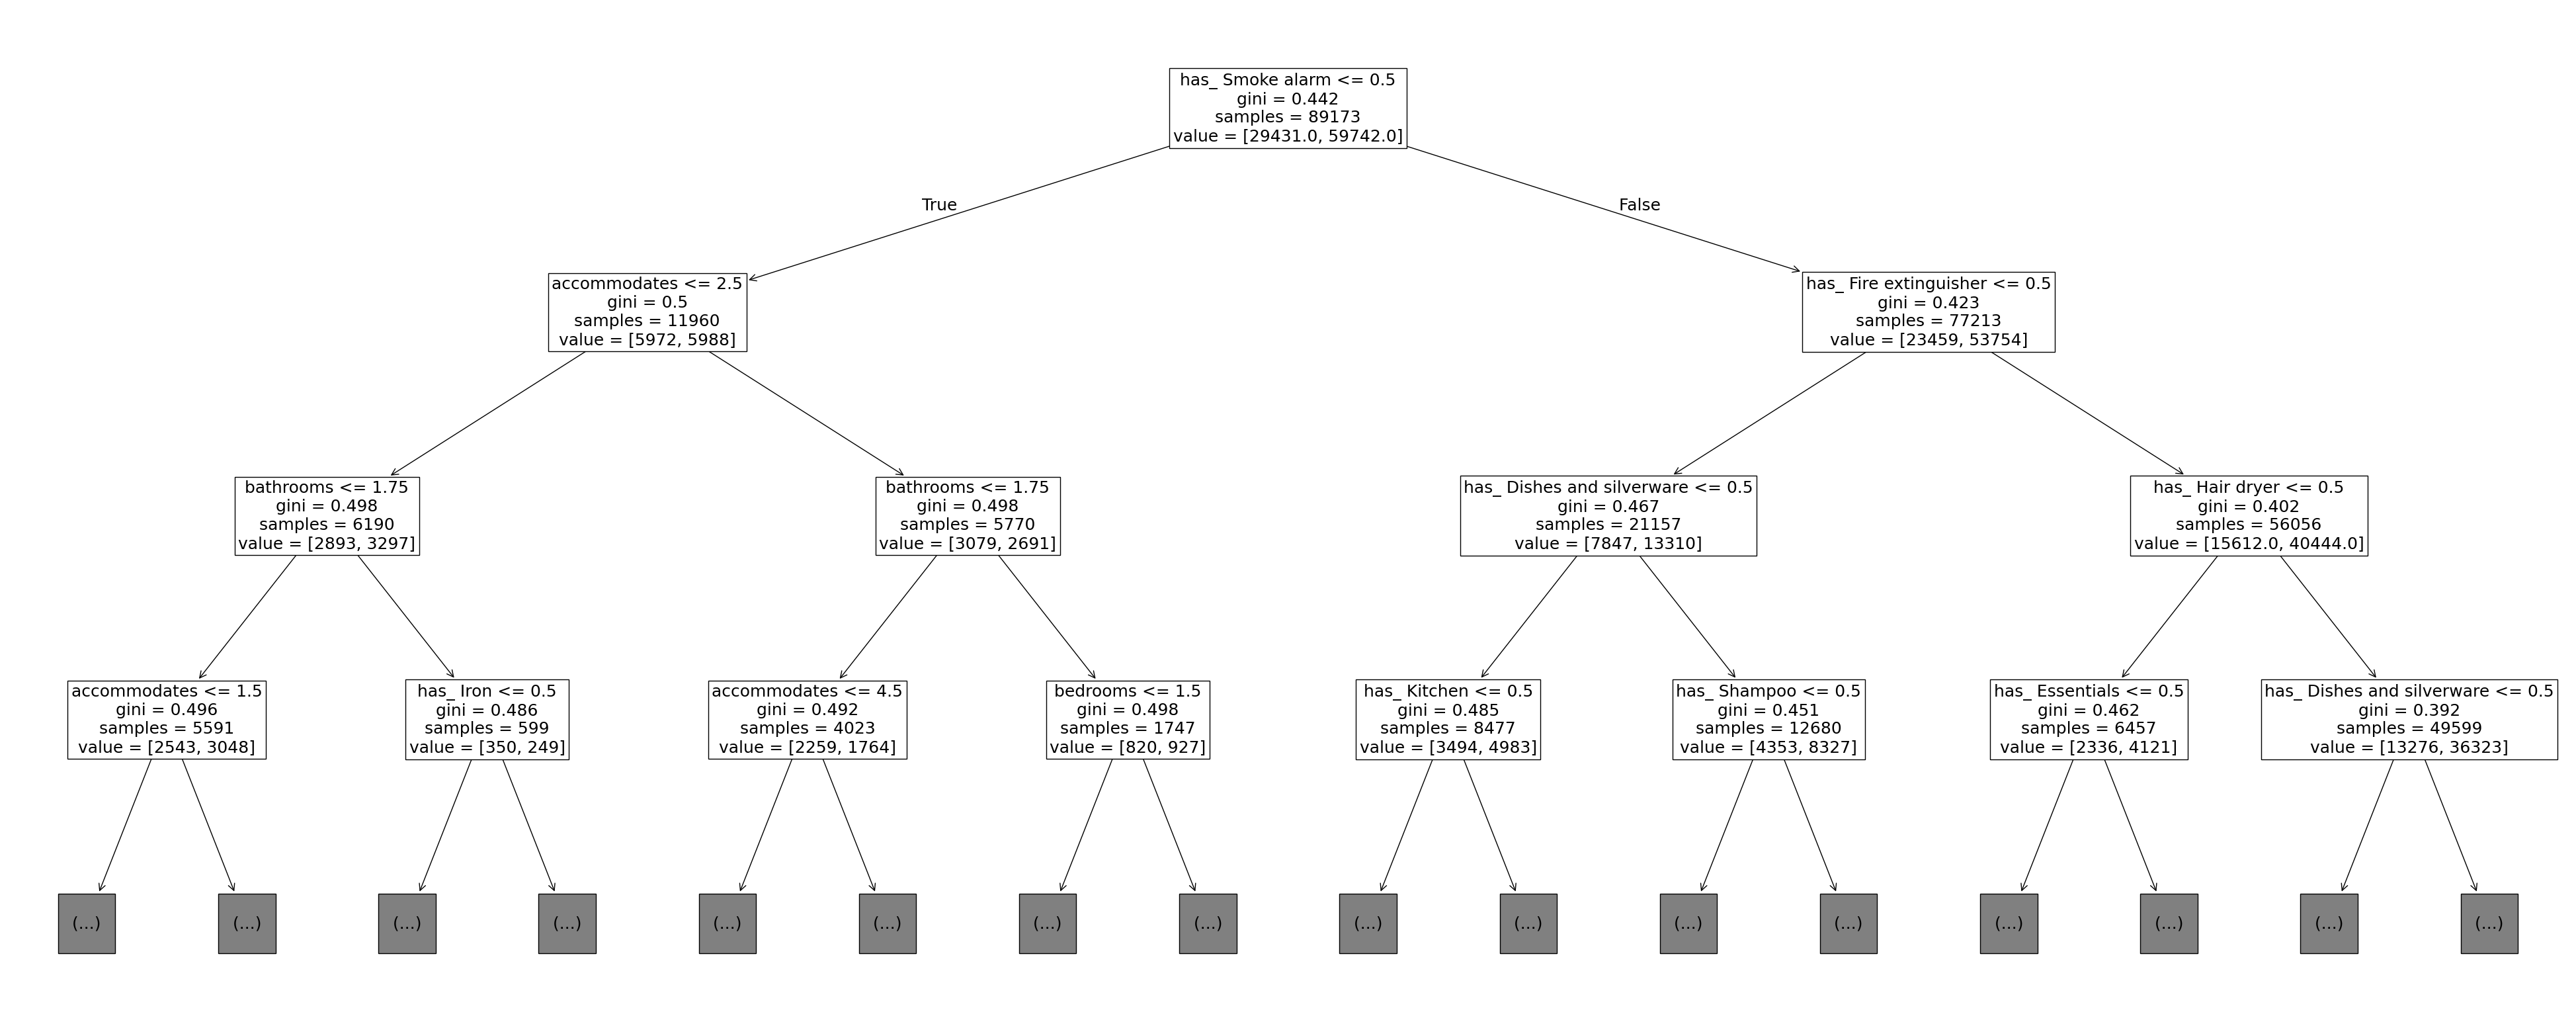

In [ ]:
fig = plt.figure(figsize=(50, 20))
ax = fig.add_subplot()
tree.plot_tree(tr, max_depth = 3, feature_names = col_names, fontsize = 18, ax = ax) #Makes a visualization of how our tree is working

Before we jump to conclusions, we should also test to see how accurate our model really is

0.6487395711850722


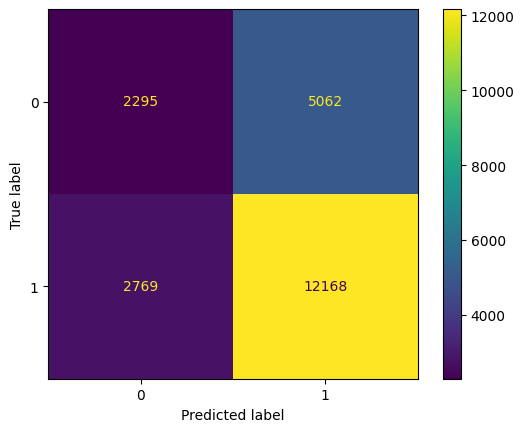

In [ ]:
y_pred = tr.predict(test_df[col_names])
y_actual = test_df['user_experience']
accuracy = accuracy_score(y_pred, test_df['user_experience'])
print(accuracy)
cm = confusion_matrix(y_actual, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm,
                              display_labels=tr.classes_)
disp.plot()
plt.show()

#### Takeaways

*  Our model is somewhat better than random guessing, which is reassuring
*  However, when we already see the issue of unbalanced classes coming back to bite us - when restricting to **accuracy on average rated listings**, our accuracy was only *~33%*  

In terms of interpreting the results, our decision tree diagram tells us that some of the most influential amenities were:
*  Having a smoke alarm
*  Having cooking supplies / having a kitchen
*  Number of guests we can accommodate / bathrooms / bedrooms

## 1.9 - Random Forest Classifier

Random Forest Classifiers are slightly less interpretable, but in turn, are more sophisticated. For a binary classification problem, it is natural to consider such a model, which we implement below

In [ ]:
df, col_names = has_amenity_df(10, total_no_price_df_adj)
col_names += ['bathrooms', 'bedrooms', 'accommodates']

#Once again, split our data into testing and training data:
train_df, test_df = train_test_split(df, train_size = 0.8)

#Load/fit our model
rfc = RandomForestClassifier()
rfc.fit(train_df[col_names], train_df['user_experience'])

#Prediction
y_pred = rfc.predict(test_df[col_names])
y_actual = test_df['user_experience']
accuracy = accuracy_score(y_pred, test_df['user_experience'])

#Plotting/printing accuracy
print(accuracy)


0.6726024939445591


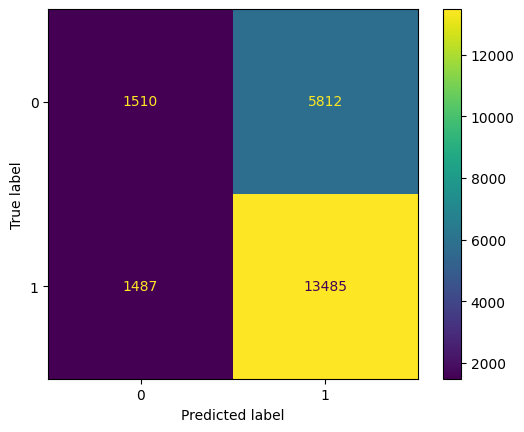

In [ ]:
cm = confusion_matrix(y_actual, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm,
                              display_labels=rfc.classes_)
disp.plot()
plt.show()

#### Takeaways/Issues

Our accuracy was marginally better, but it seems as if all the gains in accuracy came from over-guessing in the 1 category. Note that for our binary decision tree, we had ~33% accuracy when restricting to data labeled 0, but now that has *reduced down to ~21%* - this further emphasizes the necessity of using some kind of under/oversampling methods




#### Saving DataFrames Locally with Pickle

Because the next few models can be ram intensive, it is good practice to save our work so far to disk using Pickle, so that, in case of a crash, we can recover it (so long as the Jupyter kernel is still active)

In [ ]:
import pickle

#store our dataframe with prices
pickle.dump(total_df, open('total_df.pkl', 'wb'))


#store our dataframe w/o prices
pickle.dump(total_no_price_df_adj, open('total_no_price_df_adj.pkl', 'wb'))

In [ ]:
#Test that this works...
import pickle
total_no_price_df_adj = pickle.load(open('total_no_price_df_adj.pkl', 'rb'))
total_no_price_df_adj.head()

,id,city,property_type,room_type,accommodates,bathrooms,bedrooms,amenities,number_of_reviews,review_scores_rating,minimum_nights,user_experience
0,753446,Roslindale,Condominium,Private room,2,1.0,1.0,"[Wireless Internet, Pets live on this property...",65,4.80,2.0,1
1,1494726,Roslindale,House,Private room,1,1.0,1.0,"[Cable TV, Internet, Wireless Internet, Air Co...",9,4.65,3.0,0
2,1591827,Roslindale,House,Private room,2,1.0,1.0,"[TV, Cable TV, Internet, Wireless Internet, Ai...",117,4.60,2.0,0
3,735970,Boston,Bed & Breakfast,Private room,2,1.0,1.0,"[TV, Cable TV, Internet, Wireless Internet, Ki...",3,5.00,300.0,1
4,519272,Boston,Apartment,Private room,2,1.5,1.0,"[Internet, Wireless Internet, Air Conditioning...",9,4.90,3.0,1


## 1.10 - Hyperparameter optimization + Under/over sampling

**Problems** - With our last model, we saw two main issues:
1. The unequal size of classes caused our models to learn 'bad' strategies - like preferring to guess that the airbnb listing was above average. The model overall would had a accuracy that was much better than guessing, but this came at the cost of having a very terrible accuracy when it came specifically to airbnb listings that were below average (In other words, the miss-rate for listings labelled 0 was very high)

2. There were several steps where we simply guessed a parameter value - for instance, when we decided how many amenities to include in our one-hot encoding.

**Solutions** - We now have the chance to remedy these issues by implementing three new strategies:
1. We can undersample the overrepresented class (listings which have above high ratings) or alternatively oversample the underrepresented class. Here, we choice to do random undersampling rather than SMOTEN, and this is justified later.
2. We can implement a randomized grid search. This has the benefit of being more efficient than just using exhaustive search over the entire parameter space, which will give us more freedom to include a large amount of parameters to check
3. We can specify a *different scoring function* to give a larger weight to misses on our underrepresented class - for our purposes, we decided on `'balanced_accuracy_score'`

Before we start, we should note that we actually have *several* parameters we can optimize over, many of which are not parameters of the Random Forest classifier. It will help to think about / list all the 'guesses' that we have made in the construction of our modelling problem up until this point:
*   Number of amenities to include in our one-hot encoding
*   Cut-off point for good vs average experience
*   Related to the above - number of groups to classify user experiences (i.e. why not include a Below average experience category?)
*   Probability to use for our random undersampling / random oversampling
*   Max depth or other parameters from our random forest classifier



In [ ]:

#Import various random distributions from scipy.stats
from scipy.stats import uniform, binom
from sklearn.model_selection import RandomizedSearchCV
amenity_param = [10, 15, 20, 25, 30, 35]
max_param = max(amenity_param)

df, col_names = has_amenity_df(max_param, total_no_price_df_adj)
#If we generate our dataframe based on the max params, then we only have to do this function call once
# and we can just restrict the columns that we use for fitting with differnet iterations

train_df, test_df = train_test_split(df, train_size = 0.8)
# even before we start looking at parameters, it is best practice
# that our test data is already set aside for later


#Iterate over possible choices for number of amenities:
# so we are still doing an exhaustive search over this parameter
for amenity_num in amenity_param:
  print(f"Current amenity_num: {amenity_num}\n\n")
  relevant_cols = col_names[:amenity_num] # gets only the columns corresponding to top {amenity_num} amenities
  relevant_cols += ['bathrooms', 'bedrooms', 'accommodates']


  #EXAMPLE USAGE
  # {'C': scipy.stats.expon(scale=100), 'gamma': scipy.stats.expon(scale=.1),
  #'kernel': ['rbf'], 'class_weight':['balanced', None]}

  # rvs(loc=0, scale=1, size=1, random_state=None)

  #Define our sequence for our pipeline
  steps = [('ru', RandomUnderSampler()), ('rf', RandomForestClassifier())]
  pipeline = Pipeline(steps = steps)

  #Define our parameters to optimize
  param_grid = {'ru__sampling_strategy': uniform(loc = 0.6, scale=0.25), # This parameter controls the ratio of our minority class / majority class
  #                                      ^-- tells our model to sample uniformly between [.6, .825]
                'rf__n_estimators': binom(n = 50, p = 0.1, loc = 150),
  #                                 ^--- tells our model to sample with essentially a discretized, skewed, normal distribution, centered at 150
                'rf__max_depth': [12, 14, 16, 18]}
  #                               ^--- this uniformly samples between these 4 entries, rather than perform an exhaustive search

  # Note - since we are using a pipeline, then we have to do {model_name}__{parameter} in order to access a nested parameter

  search = RandomizedSearchCV(pipeline, param_grid, scoring='balanced_accuracy', verbose = 4)
  search.fit(train_df[relevant_cols], train_df['user_experience'])
    #Fits our pipeline to our data, restricted to columns determined by amenity parameter


  print(f"Best parameters:{search.best_params_}\nBest training score: {search.best_score_}")



Current amenity_num: 10


Fitting 5 folds for each of 10 candidates, totalling 50 fits
[CV 1/5] END rf__max_depth=16, rf__n_estimators=159, ru__sampling_strategy=0.7082534335169726;, score=0.571 total time=   7.0s
[CV 2/5] END rf__max_depth=16, rf__n_estimators=159, ru__sampling_strategy=0.7082534335169726;, score=0.571 total time=   5.4s
[CV 3/5] END rf__max_depth=16, rf__n_estimators=159, ru__sampling_strategy=0.7082534335169726;, score=0.572 total time=   6.9s
[CV 4/5] END rf__max_depth=16, rf__n_estimators=159, ru__sampling_strategy=0.7082534335169726;, score=0.569 total time=   5.8s
[CV 5/5] END rf__max_depth=16, rf__n_estimators=159, ru__sampling_strategy=0.7082534335169726;, score=0.576 total time=   7.0s
[CV 1/5] END rf__max_depth=12, rf__n_estimators=156, ru__sampling_strategy=0.7504029089937762;, score=0.575 total time=   4.1s
[CV 2/5] END rf__max_depth=12, rf__n_estimators=156, ru__sampling_strategy=0.7504029089937762;, score=0.576 total time=   4.3s
[CV 3/5] END rf__max_dep

#### Best Parameter Scores:

After searching our parameter space using a mix of a RandomizedCVSearch (for almost an hour!) along with an exhaustive parameter search for the number of amenities, we see that parameters which maximized training score were:
- max_depth = 16
- n_estimators = 154
- sampling_strategy ~0.75
- number of amenities = 35 (the maximum amount out of our choices)

Which these choices, we see a *balanced accuracy* of ~64 percent

#### Takeaways
- As a general trend, it seems that including more amenities continually increased the overall accuracy. Given more computing resources, it would be interesting to test what the upper limit of this is - it might very well be that 35 was a premature stopping point for the number of amenities used
- The other parameters varied in terms of what was optimal, **with the exception of sampling strategy** - it seems that losing more of our data in general caused our model to better learn to estimate the data on the smaller class
- Within a given choice of amenity number, the accuracies were all still fairly close to each other - the accuracies rarely seemed to vary more than ~5%

#### Justification for our pipeline

**Undersampling method**: Note that our choice of undersampling method, RandomUndersampling(), is fairly simplistic - it's a natural question to ask why we include a more sophisticated technique for oversampling the smaller data sample. Essentially two problems presented a barrier to this:
- The data is categorical (i.e. one-hot encoded data, mapped to a binary valued categorical output). This prevents the 'easy' creation of artifical data using SMOTE, or other similar methods (which essentially compute a convex hull of your data - e.g. relies on numerical data)
- We could have (and indeed tried) a version of SMOTE that works on categorical data, called SMOTEN - however, creating thousands of new samples of data (and doing so many, many times inside a GridSearchCV fitting) takes up an enormous amount of memory. With the free version of Colab, it caused too many crashes of the notebook from overusing memory. However, it would be interesting to try, if we had more computing resources

**Accuracy score**: As stated earlier, we chose to use `balanced_accuracy_score` with our randomized parameter search as opposed to the default accuracy score. From the sklearn documentation:

"... if the conventional accuracy is above chance only because the classifier takes advantage of an imbalanced test set, then the balanced accuracy, as appropriate, will drop to $\frac{1}{\text{num_classes}}$ "

This problem of the classifier taking advantage of an imbalanced test set is exactly what we were facing previously.



#### Testing best parameters on test data

Overall accuracy: 0.6914416434915224
Accuracy on label 0 data: 0.4919836956521739
Balanced accuracy: 0.6474291704842836


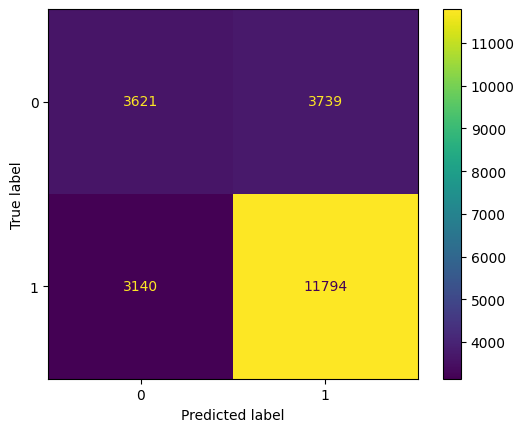

In [ ]:
from sklearn.metrics import balanced_accuracy_score
#Already have our test data saved as test_df, and our columns as col_names
relevant_cols = col_names + ['bathrooms', 'bedrooms', 'accommodates']
#Note that this is already set to include columns for 35 amenities (the optimal number from our search above)

#Load/fit our model
optimal_steps = [('ru', RandomUnderSampler(sampling_strategy = 0.75)), ('rf', RandomForestClassifier(n_estimators = 154, max_depth = 16))]
optimal_pipeline = Pipeline(steps = optimal_steps)
optimal_pipeline.fit(train_df[relevant_cols], train_df['user_experience'])

#Prediction
y_pred = optimal_pipeline.predict(test_df[relevant_cols])
y_actual = test_df['user_experience']
accuracy = accuracy_score(y_pred, test_df['user_experience'])
belowavg_accuracy = ((y_pred == 0) & (test_df['user_experience'] == 0)).sum()  / (test_df['user_experience'] == 0).sum()
balanced_acc = balanced_accuracy_score(y_pred, test_df['user_experience'])
#Plotting/printing accuracy
print(f"Overall accuracy: {accuracy}")
print(f"Accuracy on label 0 data: {belowavg_accuracy}")
print(f"Balanced accuracy: {balanced_acc}")
cm = confusion_matrix(y_actual, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm,
                              display_labels=optimal_pipeline.classes_)
disp.plot()
plt.show()

#### Lessons from optimizing models

As we see above, even after all this work of performing an randomized GridSearch on our data, we found slightly underwhelming results - namely, our model seems to have trouble with learning to predict the smaller class. Compared to our previous model, our overall accuracy has only improved a bit. However, the do find the positive result that our accuracy when restring to the 0-labeled data is **significantly improved**! (Up to ~50%, from previously ~33%)

As a key lesson, it is worth understanding that choosing to optimize with respect to different scoring functions comes with various costs. In this case, we see minimal improvements in terms of total accuracy, but at least our model is about as good as guessing on the 0-labeled data. It is worth keeping in mind, that by choosing a scoring function with even larger penalties for misguessing on the smaller class, we likely could have optimized this further, but it almost certainly would have come at a cost of having worse accuracy on the 1-labeled data.

## 1.11 - Second approach - Semantic Similarity Problem

Note that currently, we have many features might differ between airbnb listings, yet are ''essentially'' the same - e.g. Internet vs wifi vs wireless internet, etc. Since we would ideally like to simplify our feature space anyway, and would like to do this in a way which projects our feature space onto a large subspace with a lot of common entries, we approach this problem by using an imported model, model2vec (similar to a method discussed in class for identifying when two rows in two different tables should be joined, given no outside context about their similarity)

### 1.11.1 - Why we chose model2vec

Although there are many more sophisticated model choices (e.g. Jina) for the problem of semantic classification, the other models we tried ended up being drastically too slow for the dataset we were working with. Because we have more than 100000 rows of data, we were restricted to choosing a model that prioritizes efficiency, like model2vec

First, install and load our model:

In [ ]:
!pip install model2vec
from model2vec import StaticModel

#Load Model
model = StaticModel.from_pretrained("minishlab/potion-base-32M")


Fetching 10 files:   0%|          | 0/10 [00:00<?, ?it/s]

In [ ]:
# Create one large list of all possible amenity names

amenity_list = []
index = 0

# This isolates the Pandas Series consisting of the lists of amenities for each airbnb listing
# in a variable `cleanedAmenitiesBatch`
cleanedAmenitiesBatch = cleanedAmenities2

#Iterates through each apartment listing in our series of lists of amenities
# `sublist` will be a given airbnb's list of amenities
for sublist in cleanedAmenitiesBatch.tolist():
  #print(index)
  index += 1

  #Each entry in this cleanedAmenitiesBatch series is itself a list of amenities
  # so we just iterate over this list of amenities
  for amenity in sublist:

    # We check if we have already seen this amenity before (We want a list of unique amenities, so we don't skew our vectorization)
    if amenity not in amenity_list:


      amenity_list.append(amenity) # does not allow for repeats, so does not skew clustering
print(amenity_list[:100])

#Now we turn our list of amenities into a list of vectors using our model2vec model
embeddings = model.encode(amenity_list)


['Wireless Internet', 'Pets live on this property', 'Cat(s)', 'Heating', 'Family/Kid Friendly', 'Smoke Detector', 'Carbon Monoxide Detector', 'Shampoo', 'Hangers', 'Hair Dryer', 'Cable TV', 'Internet', 'Air Conditioning', 'Free Parking on Premises', 'Washer', 'Dryer', 'Fire Extinguisher', 'Essentials', 'Iron', 'Laptop Friendly Workspace', 'TV', 'Kitchen', 'Dog(s)', 'First Aid Kit', 'Breakfast', 'Indoor Fireplace', 'Buzzer/Wireless Intercom', '24-Hour Check-in', 'translation missing: en.hosting_amenity_49', 'Safety Card', 'Pets Allowed', 'Washer / Dryer', 'Wheelchair Accessible', 'Elevator in Building', 'Gym', 'Suitable for Events', 'translation missing: en.hosting_amenity_50', 'Hot Tub', 'Pool', 'Doorman', 'Lock on Bedroom Door', 'Smoking Allowed', 'Other pet(s)', '[Kitchen', ' Elevator', ' Extra pillows and blankets', ' Bed linens', ' Hangers', ' Iron', ' Shampoo', ' Wifi', ' Heating', ' Cooking basics', ' Hot water', ' Pocket wifi', ' Dishes and silverware', ' Long term stays allowed

In [ ]:
# Use KMeans clustering to cluster these different vectors
from sklearn.cluster import KMeans

#Instantiate model with 10 clusters
kmc = KMeans(n_clusters = 10)

#Fit our model to our list of all possible vectors we see from vectorizing amenities in our data
kmc.fit(embeddings)

# Compute a simple test to check that our model is working correctly
test = cleanedAmenitiesBatch.tolist()[0][0]
print(test)

#Computes which cluster the vectorized version of the above amenity belongs to
grouping = kmc.predict(model.encode(test).reshape(1, -1).astype('double'))
print(grouping)

Wireless Internet
[3]


### 1.11.2 - Understanding our groups

We sample some entries and try to find out what our groups "look like"

In [ ]:
import pprint
#^-- use this for a cleaner way to output our dictionary below

#Take a small sample of airbnb's from our data
sampled = cleanedAmenitiesBatch.sample(100)


new_dict = {}
for i in range(10):
  new_dict[i] = []
# Instantiates our dictionary with key:value pairs of form {i: []}, for each of our possible cluster numbers

#Iterate over our small sampling of airbnb listings
for entry in sampled.to_list():
  #So entry has form ['TV', 'Wifi'], etc.


  # Iterate over each amenity of the list `entry`
  for amenity in entry:

    #Compute the cluster group of the vectorized version of the above amenity
    group = kmc.predict(model.encode(amenity).reshape(1, -1).astype('double'))[0]


    if amenity not in new_dict[group]:

      #Keeps track of the amenity names we find in each cluster group
      new_dict[group].append(amenity)

#Print our dictionary
pprint.pprint(new_dict)

{0: [' Body soap',
     ' Bathtub',
     ' Body soap]',
     ' Assorted varieties  body soap',
     ' Molten Brown body soap',
     ' Dove body soap',
     ' Public Goods body soap',
     ' Dial body soap',
     '[Body soap'],
 1: [' Hot water kettle',
     ' Heating',
     ' Electric stove',
     ' Stove',
     ' Barbecue utensils',
     ' Gas stove',
     ' Samsung stainless steel electric stove',
     ' Rice maker',
     ' Stainless steel electric stove',
     '[Stove',
     ' Maytag stainless steel gas stove',
     ' Private BBQ grill: gas',
     ' LG stainless steel gas stove]',
     ' Unique gas stove',
     ' Stainless steel gas stove',
     ' Indoor fireplace: gas',
     ' GE stainless steel gas stove',
     ' Viking stainless steel gas stove',
     ' Frigidaire stainless steel gas stove',
     ' Whirlpool stainless steel electric stove',
     ' Kitchenette',
     ' Stove]'],
 2: [' Hair dryer',
     ' Conditioner',
     ' Air conditioning',
     ' Central air conditioning',
  

#### Takeaways:

- In short, it seems that the groups can be 'roughly classified' as follows:
0. Soap
1. Stove / Kitchen appliances
2. Unfortunate mix of hair products (conditioner) and house cooling (air conditioners)
3. Wifi
4. Sound systems
5. Essentially a 'catch-all' for amenities which did not clearly fit into other clusters
6. Shampoo
7. Other Kitchen appliances
8. Freezer/Refrigerator
9. Television/ Streaming service subscriptions
- We can hope that although we lose a lot of information, that maybe simplifying the common amenities in this way will prove to be useful for helping our model distinguish which types of features are actually important

(**Note**: If this cell is rerun, then the clusters will get a different numbering, but most of the same classification should be true)

#### Justification for number of clusters

Given the existence of cluster 5 above, which combines many unrelated amenities, it is natural to wonder whether picking a larger number of clusters wouldnt help filter some of these entries into more natural subclusters. However, in our testing, we found this not to be the case - instead, it would introduce very small clusters with only a few amenities, that were usually very niche - like having a specific brand of body soap or conditioner. Thus, we decided that having 10 clusters, which were occassionally too large was a superior alternative to introducing several super niche small clusters.

In [ ]:

#Now, we want to exchange lists of amenities, e.g. ['Wifi', 'TV']
#  with a corresponding list of cluster assignments for the vectorized versions of these amenity names
#  so ['Wifi', 'TV'] might correspond to a list of clusters [2, 4], which we add as a new feature to our data


#Copy our dataframe consisting of cleaned data about airbnb listings
SmallBatchTotal = total_no_price_df.copy()

#Save our series of amenity lists
cleanedAmenitiesBatch = cleanedAmenities

#create new list - we will use this to store each lists of cluster assignments
total_grouping = []

#Iterate through the different amenity lists from our data of airbnb listings
for sublist in cleanedAmenitiesBatch.tolist(): #Each entry in this cleanedAmenities2 series is itself a list of amenities

  # Create a list of cluster groupings e.g. [2,4]
  # Do this by vectorizing the entire amenity list at one time
  # then applying KMeans to the entire list of vectors
  grouping_list = np.unique(kmc.predict(model.encode(sublist).astype('double')))

  #Adds this list of cluster assignments to our `total_grouping` variable
  total_grouping.append(grouping_list)
  #print(grouping_list)

# Turns this list of lists (of cluster assignments) into a Series, and adds it as a feature to our dataframe
SmallBatchTotal['groups'] = pd.Series(total_grouping)

#Just a sanity check to make sure that we actually have done what we wanted to
SmallBatchTotal.head()

,id,city,property_type,room_type,accommodates,bathrooms,bedrooms,amenities,number_of_reviews,review_scores_rating,minimum_nights,groups
8,753446,Roslindale,Condominium,Private room,2,1.0,1.0,"[Wireless Internet, Pets live on this property...",65,4.80,2.0,"[1, 2, 3, 5, 9]"
47,1494726,Roslindale,House,Private room,1,1.0,1.0,"[Cable TV, Internet, Wireless Internet, Air Co...",9,4.65,3.0,"[1, 3, 5, 6, 9]"
50,1591827,Roslindale,House,Private room,2,1.0,1.0,"[TV, Cable TV, Internet, Wireless Internet, Ai...",117,4.60,2.0,"[1, 3, 5, 6]"
59,735970,Boston,Bed & Breakfast,Private room,2,1.0,1.0,"[TV, Cable TV, Internet, Wireless Internet, Ki...",3,5.00,300.0,"[1, 3, 5, 6, 7, 9]"
72,519272,Boston,Apartment,Private room,2,1.5,1.0,"[Internet, Wireless Internet, Air Conditioning...",9,4.90,3.0,"[1, 3, 5, 6, 7, 9]"


### 1.11.2.5 - Adding user experience labellings

In [ ]:

# Now we add these labels to our dataset
#Just for ease, we do this in duckdb


query = """ SELECT *, (CASE
            WHEN review_scores_rating >= 4.8 THEN 1
            ELSE 0
            END) AS user_experience
            FROM SmallBatchTotal
"""
#Creates new dataframe with an additional feature of `user_experience`
SmallBatchTotal_Adj = duckdb.sql(query).to_df()


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

### 1.11.3 - Binary Decision Tree on KMeans clusters




[Text(0.4523809523809524, 0.9, 'has_group_1 <= 0.5\ngini = 0.443\nsamples = 89173\nvalue = [29509, 59664]'),
 Text(0.21428571428571427, 0.7, 'has_group_5 <= 0.5\ngini = 0.435\nsamples = 10918\nvalue = [3497, 7421]'),
 Text(0.3333333333333333, 0.8, 'True  '),
 Text(0.09523809523809523, 0.5, 'has_group_7 <= 0.5\ngini = 0.48\nsamples = 10\nvalue = [6, 4]'),
 Text(0.047619047619047616, 0.3, 'gini = 0.49\nsamples = 7\nvalue = [4, 3]'),
 Text(0.14285714285714285, 0.3, 'gini = 0.444\nsamples = 3\nvalue = [2, 1]'),
 Text(0.3333333333333333, 0.5, 'has_group_4 <= 0.5\ngini = 0.435\nsamples = 10908\nvalue = [3491, 7417]'),
 Text(0.23809523809523808, 0.3, 'has_group_0 <= 0.5\ngini = 0.436\nsamples = 10796\nvalue = [3460, 7336]'),
 Text(0.19047619047619047, 0.1, '\n  (...)  \n'),
 Text(0.2857142857142857, 0.1, '\n  (...)  \n'),
 Text(0.42857142857142855, 0.3, 'has_group_2 <= 0.5\ngini = 0.4\nsamples = 112\nvalue = [31, 81]'),
 Text(0.38095238095238093, 0.1, '\n  (...)  \n'),
 Text(0.476190476190476

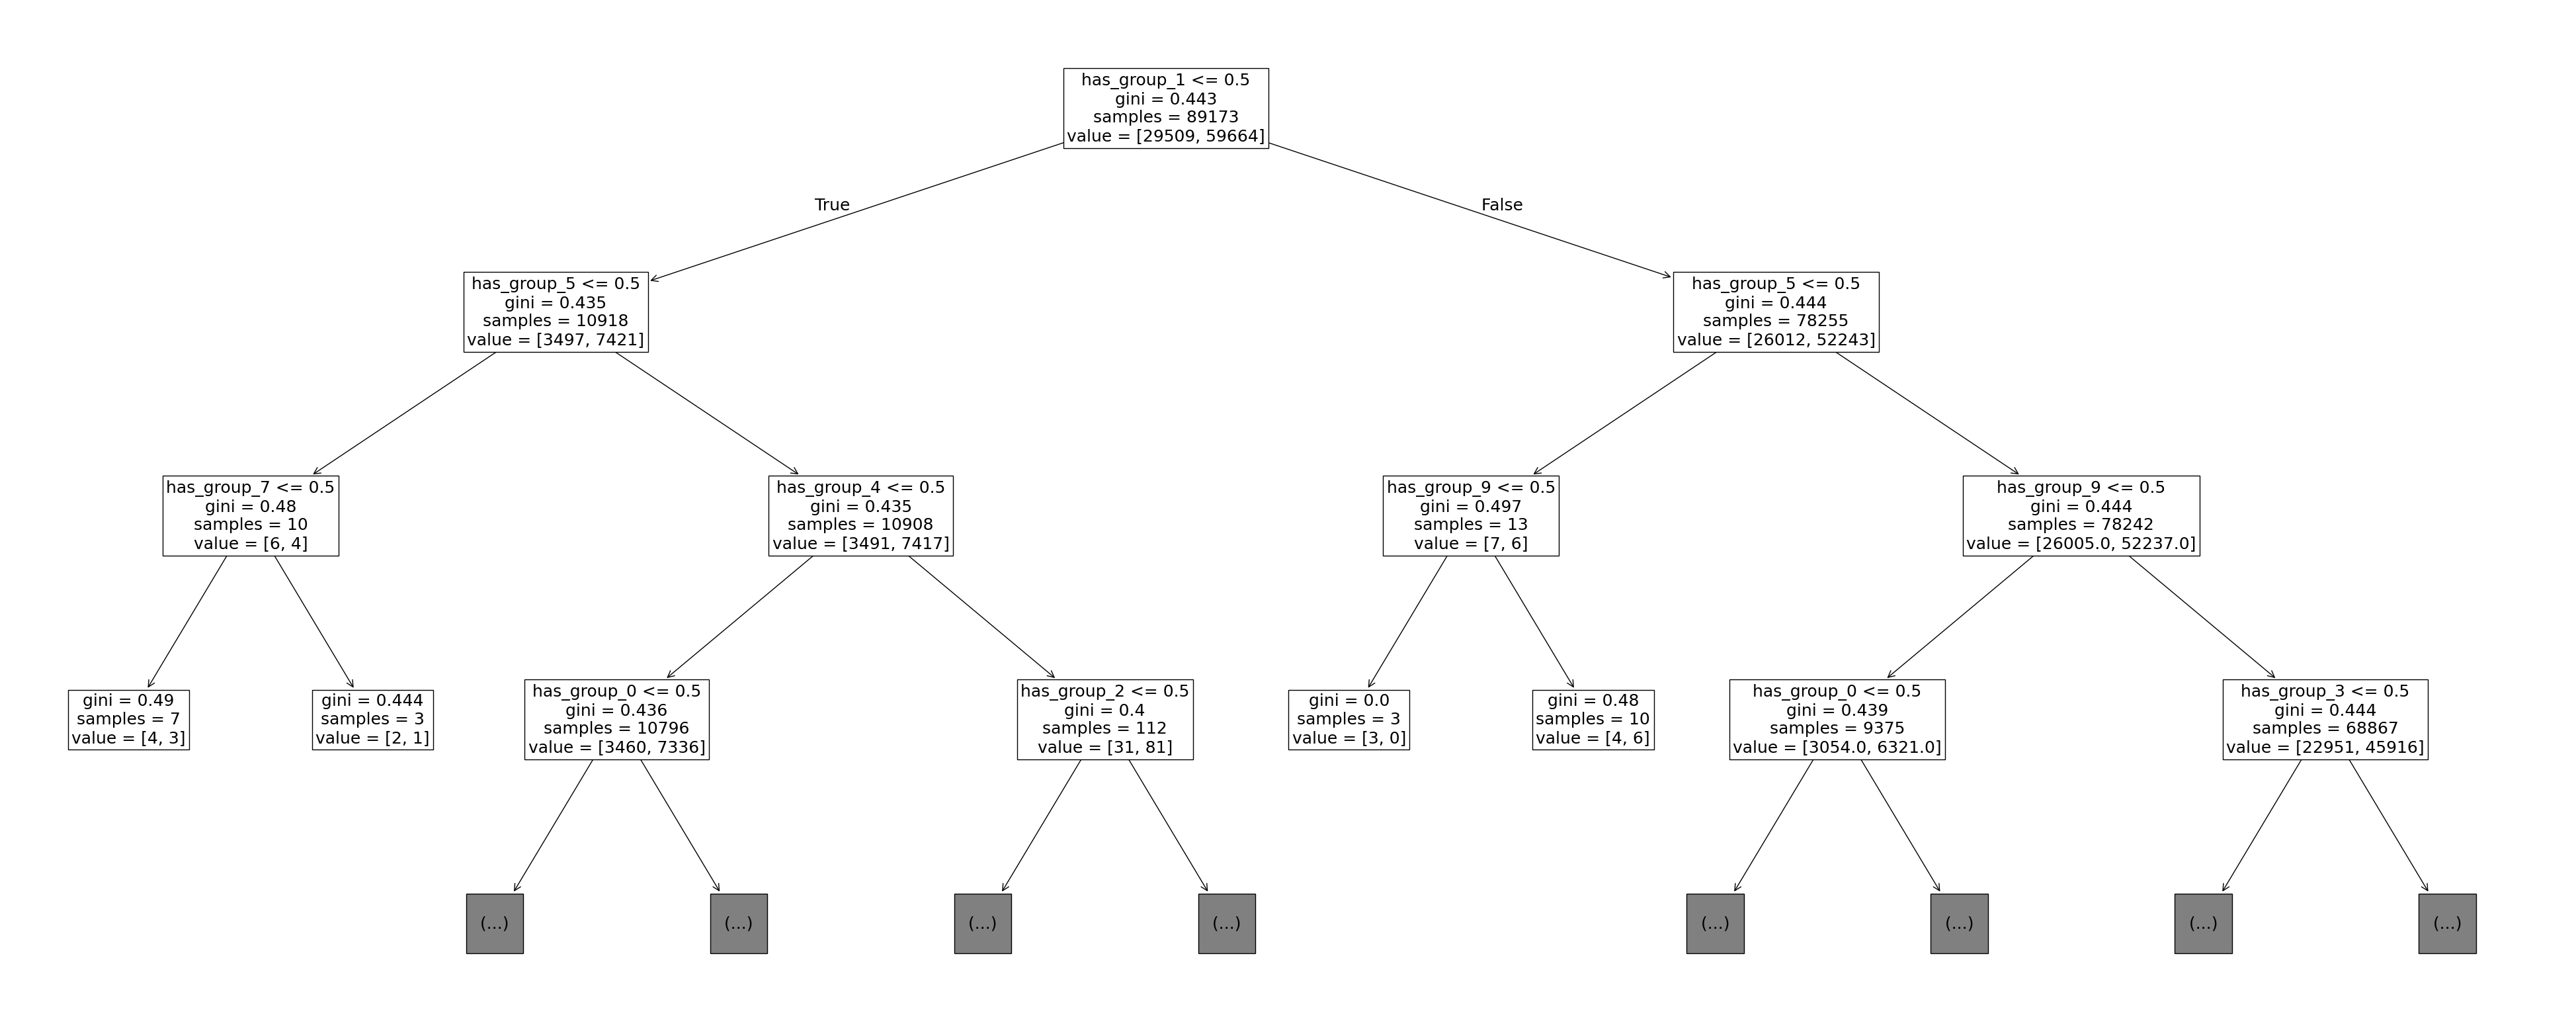

In [ ]:
## Analysis done using groups after KMeans clustering

#Drop any accidental Null values leftover in our dataset
SmallBatchTotal_Adj.dropna(inplace=True)

#
group_df, group_col_names = has_group_df(10, SmallBatchTotal_Adj) # Make sure number is the same as the Kmeans number of clusters
group_col_names += ['bathrooms', 'bedrooms', 'accommodates']

# This just gets the list of column names (col_names)
# and creates a dataframe that has a 1-hot encoding of the 10 clusters derived from our previous KMeans model
# We also add in a few extra features,
# which we consider are close enough to amenities to be worth considering

train_df, test_df = train_test_split(group_df, train_size = 0.8)
#Splits our dataframe into a testing and training sample

tr = tree.DecisionTreeClassifier()
#No extra parameters for now

tr.fit(train_df[col_names], train_df['user_experience'])

fig = plt.figure(figsize=(50, 20))
ax = fig.add_subplot()
tree.plot_tree(tr, max_depth = 3, feature_names = col_names, fontsize = 18, ax = ax) #Makes a visualization of how our tree is working

0.6726024939445591


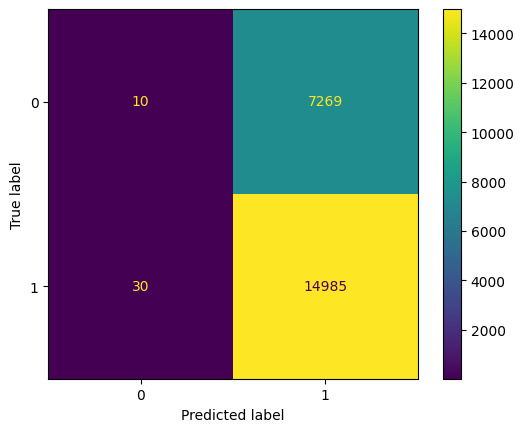

In [ ]:
y_pred = tr.predict(test_df[col_names])
y_actual = test_df['user_experience']
accuracy = accuracy_score(y_pred, test_df['user_experience'])
print(accuracy)
cm = confusion_matrix(y_actual, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm,
                              display_labels=tr.classes_)
disp.plot()
plt.show()

#### Takeaways
Our tree seems to be classifying primarly based on groups 1, 9, and 5, which if we recall, tended to correspond to features like having a kitchen/stove, having a television/streaming services, and 5 was sort of a catch-all cluster. Thus, we can takeaway that having a kitchen and television/streaming services was a contributing factor to users having a positive experience at an airbnb listing.

However, note that the accuracy from this graph leaves quite a bit to be desired - in general, it seems that our model simply learned to guess 1 the majority of the time.

### 1.11.4 - Random forest classifier on KMeans clusters (Using previously optimized parameters)

Overall accuracy: 0.6517448640889926
Accuracy on label 0 data: 0.14295476288096215
Balanced accuracy: 0.5472672973344501


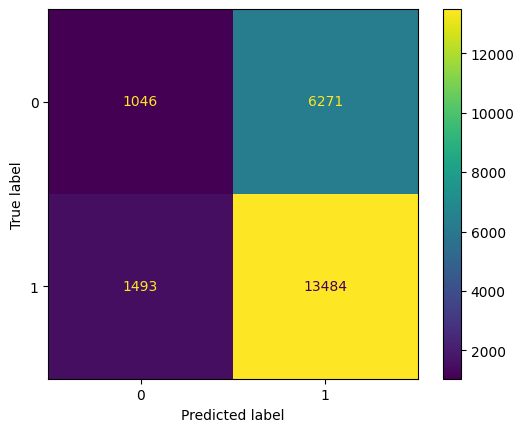

In [ ]:

group_df, group_col_names = has_group_df(10, SmallBatchTotal_Adj) # Make sure number is the same as the Kmeans number of clusters
group_col_names += ['bathrooms', 'bedrooms', 'accommodates']

train_df, test_df = train_test_split(group_df, train_size = 0.8)
#Splits our dataframe into a testing and training sample

#Load/fit our model
optimal_steps = [('ru', RandomUnderSampler(sampling_strategy = 0.75)), ('rf', RandomForestClassifier(n_estimators = 154, max_depth = 16))]
optimal_pipeline = Pipeline(steps = optimal_steps)
optimal_pipeline.fit(train_df[group_col_names], train_df['user_experience'])

#Prediction
y_pred = optimal_pipeline.predict(test_df[group_col_names])
y_actual = test_df['user_experience']
accuracy = accuracy_score(y_pred, test_df['user_experience'])
belowavg_accuracy = ((y_pred == 0) & (test_df['user_experience'] == 0)).sum()  / (test_df['user_experience'] == 0).sum()
balanced_acc = balanced_accuracy_score(y_pred, test_df['user_experience'])
#Plotting/printing accuracy
print(f"Overall accuracy: {accuracy}")
print(f"Accuracy on label 0 data: {belowavg_accuracy}")
print(f"Balanced accuracy: {balanced_acc}")
cm = confusion_matrix(y_actual, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm,
                              display_labels=optimal_pipeline.classes_)
disp.plot()
plt.show()

#### Takeaways

Although the vectorization of our string amenity features seemed like it had potential for linking together similar amenities in our dataset, it seems that even after using optimal parameters, our accuracy is much worse than what we had when we just directly input our string amenities as a one-hot encoding.

Likely, this is due to the fact that our vectorization/ Kmeans was not able to sufficiently distguish between a large class of amenities (see cluster 5, for example - which included things from 'Host will greet you at the door', all the way to 'easy beach access'), and other amenities were split into too fine of categories (e.g. one category seemed to be filled only with amenities involving body soap).

Given more computing resources and time, we would have liked to repeat this analysis using a more sophisticated model than model2vec, like Jina. Such a model might have been better able to sense semantic similarities and differences between our amenities, and thus provided better cluster divisions after applying a KMeans clustering algorithm.

# Part 2 - NY rental pricing vs Airbnb pricing

## 2.1 - Preparing and visualizing the data

We begin by reloading the relevant dataset.

In [ ]:

#Uses kagglehub api to load datasets from Kaggle
NYHousingdf = kagglehub.load_dataset(
     KaggleDatasetAdapter.PANDAS,
    "ericpierce/new-york-housing-zillow-api",
    "newyork_housing.csv"
)[[ "address/zipcode", "bathrooms", "bedrooms", "price","latitude","longitude"]]
#Since the dataset consist of thousands of features, it will be easier for us to reduce to just the features above

NYAirbnbdf = kagglehub.load_dataset(
    KaggleDatasetAdapter.PANDAS,
    "arianazmoudeh/airbnbopendata",
    "Airbnb_Open_Data.csv"
)
#[["id","lat","long","price","neighbourhood","room type"]]

/tmp/ipykernel_2132/183753190.py:2: DeprecationWarning: Use dataset_load() instead of load_dataset(). load_dataset() will be removed in a future version.
  NYHousingdf = kagglehub.load_dataset(


Using Colab cache for faster access to the 'new-york-housing-zillow-api' dataset.


/usr/local/lib/python3.12/dist-packages/kagglehub/pandas_datasets.py:92: DtypeWarning: Columns (2,5,51,52,53,54,55,56,57,58,59,60,61,62,63,64,65,66,67,68,69,70,71,72,73,74,75,76,77,78,79,80,81,82,83,84,85,86,87,88,89,90,91,92,93,94,95,96,97,98,99,100,101,102,103,104,105,106,107,108,109,110,111,112,113,114,115,116,117,118,119,120,121,122,123,124,125,126,127,128,129,130,131,132,133,134,135,136,137,138,139,140,141,142,143,144,145,146,147,148,149,150,151,152,153,154,155,156,157,158,159,160,161,162,163,164,165,166,167,168,169,170,171,172,173,174,175,176,177,178,179,180,181,182,183,184,185,186,187,188,189,190,191,192,193,194,195,196,197,198,199,200,201,202,203,204,205,206,207,208,209,210,211,212,213,214,215,216,217,218,219,220,221,222,223,224,225,226,227,228,229,230,231,232,233,234,235,236,237,238,239,240,241,242,243,244,245,246,247,248,249,250,251,252,253,254,255,256,257,258,259,260,261,262,263,264,265,266,267,268,269,270,271,272,273,274,275,276,277,278,279,280,281,282,283,284,285,286,287,2

Using Colab cache for faster access to the 'airbnbopendata' dataset.


/usr/local/lib/python3.12/dist-packages/kagglehub/pandas_datasets.py:92: DtypeWarning: Columns (25) have mixed types. Specify dtype option on import or set low_memory=False.
  result = read_function(


In [ ]:
NYAirbnbdf.columns

Index(['id', 'NAME', 'host id', 'host_identity_verified', 'host name',
       'neighbourhood group', 'neighbourhood', 'lat', 'long', 'country',
       'country code', 'instant_bookable', 'cancellation_policy', 'room type',
       'Construction year', 'price', 'service fee', 'minimum nights',
       'number of reviews', 'last review', 'reviews per month',
       'review rate number', 'calculated host listings count',
       'availability 365', 'house_rules', 'license'],
      dtype='object')

We clean our dataset, for example by extracting the dollar price and removing null rows.

In [ ]:

#Drop any null values
NYAirbnbCleandf = NYAirbnbdf.dropna(subset=["id","lat","long","price","neighbourhood","room type"]).copy()

#Remove $ from price feature
NYAirbnbCleandf['price'] = (
    NYAirbnbCleandf['price']
    .replace('[\$,]', '', regex=True)
)

#Convert price to float
NYAirbnbCleandf['price'] = pd.to_numeric(
    NYAirbnbCleandf['price'],
    errors='coerce'
)

#Remove null values leftover from the process above in the price feature
NYAirbnbCleandf = NYAirbnbCleandf.dropna(subset=['price'])


#Need to repeat this cleaning for the other dataset now:

#Drop null values
NYHousingCleandf = NYHousingdf.dropna(
    subset=["address/zipcode", "bathrooms", "bedrooms", "price", "latitude", "longitude"]
).copy()

#Reformat column names
NYHousingCleandf.rename(columns={"address/zipcode": "zipcode"}, inplace=True)

#Convert price to float (Here we did not have to worry about having a '$' symbol)
NYHousingCleandf['price'] = pd.to_numeric(
    NYHousingCleandf['price'],
    errors='coerce'
)


NYHousingCleandf = NYHousingCleandf.dropna(subset=['price'])

#Extract digits from zipcode feature (in the dataset, zipcode is hidden inside a longer address feature)
NYHousingCleandf['zipcode'] = (
    NYHousingCleandf['zipcode']
    .astype(str)
    .str.extract(r'(\d{5})')[0]
)
NYHousingCleandf = NYHousingCleandf.dropna(subset=['zipcode'])

<>:7: SyntaxWarning: invalid escape sequence '\$'
<>:7: SyntaxWarning: invalid escape sequence '\$'
/tmp/ipykernel_2132/508468498.py:7: SyntaxWarning: invalid escape sequence '\$'
  .replace('[\$,]', '', regex=True)


Visualize the ditribution of our data.

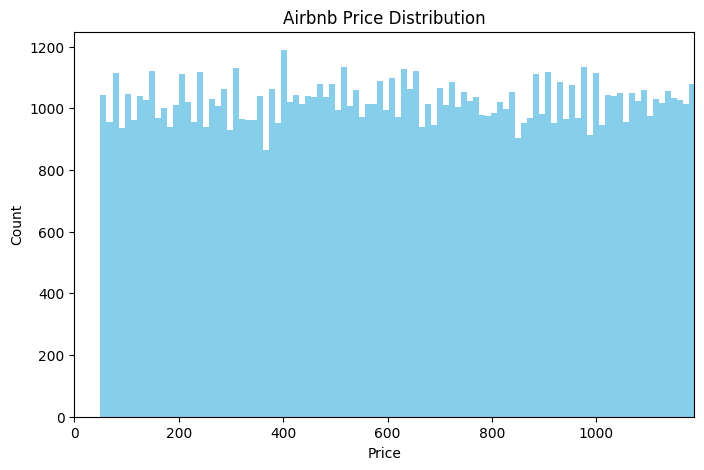

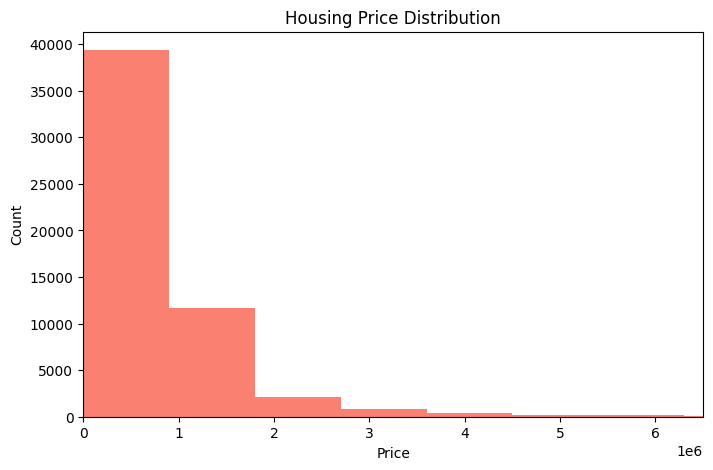

In [ ]:
import matplotlib.pyplot as plt


plt.figure(figsize=(8,5))
#Groups airbnb's into bins based on price
plt.hist(NYAirbnbCleandf["price"], bins=100, color="skyblue")
plt.title("Airbnb Price Distribution")
plt.xlabel("Price")
plt.ylabel("Count")

#limits us from seeing outliers in price
plt.xlim(0, NYAirbnbCleandf["price"].quantile(0.99))  # zoom in
plt.show()

#Does the same thing as above, but with the NYHousing dataset
plt.figure(figsize=(8,5))
plt.hist(NYHousingCleandf["price"], bins=100, color="salmon")
plt.title("Housing Price Distribution")
plt.xlabel("Price")
plt.ylabel("Count")
plt.xlim(0, NYHousingCleandf["price"].quantile(0.99))
plt.show()

Note that there are more anomalies towards the higher end of the prices. We pick the quantile between 2 and 95 and replot our data.

In [ ]:
# Function to trim top and bottom 1% based on price
def trim_price_outliers(df, column='price'):
    lower_bound = df[column].quantile(0.02)
    upper_bound = df[column].quantile(0.95)
    return df[(df[column] >= lower_bound) & (df[column] <= upper_bound)]

# Apply to both datasets
NYAirbnbCleandf = trim_price_outliers(NYAirbnbCleandf, 'price')
NYHousingCleandf = trim_price_outliers(NYHousingCleandf, 'price')

print("Airbnb rows after trim:", len(NYAirbnbCleandf))
print("Housing rows after trim:", len(NYHousingCleandf))

Airbnb rows after trim: 95284
Housing rows after trim: 51460


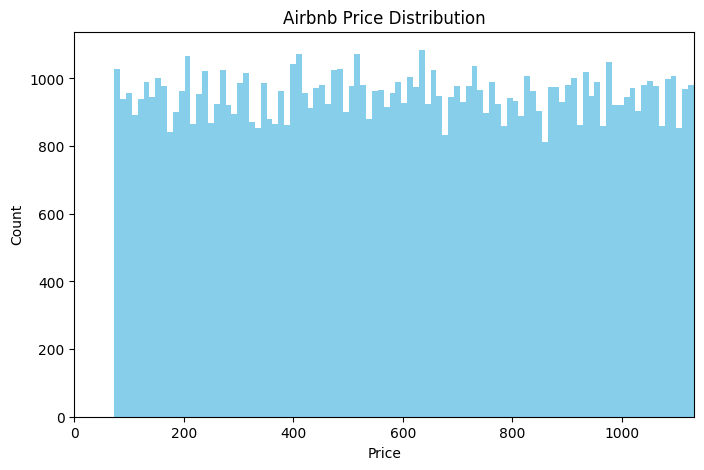

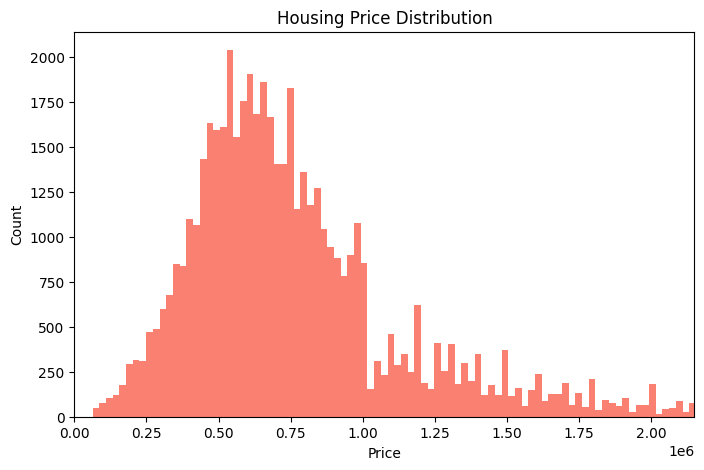

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))
plt.hist(NYAirbnbCleandf["price"], bins=100, color="skyblue")
plt.title("Airbnb Price Distribution")
plt.xlabel("Price")
plt.ylabel("Count")
plt.xlim(0, NYAirbnbCleandf["price"].quantile(0.99))  # zoom in
plt.show()

plt.figure(figsize=(8,5))
plt.hist(NYHousingCleandf["price"], bins=100, color="salmon")
plt.title("Housing Price Distribution")
plt.xlabel("Price")
plt.ylabel("Count")
plt.xlim(0, NYHousingCleandf["price"].quantile(0.99))
plt.show()

In [ ]:
NYAirbnbCleandf.shape

(95284, 26)

## 2.2 - Zipcode matching

We would like to compare the correlation between Airbnb price and housing price. To do this, we need to match the prices from the same neighborhood. Unfortunately, while the NYHousing dataset contains the zipcode information, the NYAirbnb dataset doesn't. However, it does contain the latitude / longitude information, from which we determine each Airbnb's zipcode and match it with the NYHousing zipcode. (When you are running it, if there is a prompt then enter A).

In [ ]:
!wget https://www2.census.gov/geo/tiger/TIGER2023/ZCTA520/tl_2023_us_zcta520.zip
!unzip tl_2023_us_zcta520.zip

#Imports
import geopandas as gpd

#Reads a file containing zipcodes from the US
zip_shapes = gpd.read_file("tl_2023_us_zcta520.shp")
zip_shapes = zip_shapes.rename(columns={"ZCTA5CE20": "zipcode"})

#Limits to just the necessary features
NYAirbnbCleandf = NYAirbnbCleandf.dropna(subset=["lat", "long", "price"]).copy()

#Creates a geoDataFrame using the Lat/Long data from the new york airbnb dataset
gdf_airbnb = gpd.GeoDataFrame(
    NYAirbnbCleandf,
    geometry=gpd.points_from_xy(
        NYAirbnbCleandf["long"],
        NYAirbnbCleandf["lat"]
    ),
    crs="EPSG:4326"
)
#The 'crs' specifies Coordinate Reference System
#  - Whenever you see us use '4326', it means we are using
#  - the traditional lat/long coordinates within our geodataframe

#Currently, the zipcodes use a different coordinate system
# so we convert to lat/long in order to merge with our dataset
zip_shapes = zip_shapes.to_crs("EPSG:4326")

#Joins our airbnb listings with zipcode information along the lat/long values
gdf_airbnb = gpd.sjoin(
    gdf_airbnb,
    zip_shapes,
    how="left",
    predicate="within"
)
gdf_airbnb = gdf_airbnb.dropna(subset=["zipcode"])
print(gdf_airbnb[["lat", "long", "zipcode"]].head())
print("Number of Airbnb rows with ZIP:", len(gdf_airbnb))
print("Unique ZIP codes:", gdf_airbnb["zipcode"].nunique())


--2026-04-27 14:17:45--  https://www2.census.gov/geo/tiger/TIGER2023/ZCTA520/tl_2023_us_zcta520.zip
Resolving www2.census.gov (www2.census.gov)... 172.65.90.25, 172.65.90.26, 172.65.90.27, ...
Connecting to www2.census.gov (www2.census.gov)|172.65.90.25|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 528313293 (504M) [application/zip]
Saving to: ‘tl_2023_us_zcta520.zip’

tl_2023_us_zcta520. 100%[===================>] 503.84M  76.4MB/s    in 9.0s    

2026-04-27 14:17:54 (55.8 MB/s) - ‘tl_2023_us_zcta520.zip’ saved [528313293/528313293]

Archive:  tl_2023_us_zcta520.zip
 extracting: tl_2023_us_zcta520.cpg  
  inflating: tl_2023_us_zcta520.dbf  
  inflating: tl_2023_us_zcta520.prj  
  inflating: tl_2023_us_zcta520.shp  
  inflating: tl_2023_us_zcta520.shp.ea.iso.xml  
  inflating: tl_2023_us_zcta520.shp.iso.xml  
  inflating: tl_2023_us_zcta520.shx  
        lat      long zipcode
0  40.64749 -73.97237   11218
1  40.75362 -73.98377   10018
2  40.80902 -73.94190  

We keep zipcodes that have more than 10 Airbnb entries and more than 10 housing entries.

In [ ]:
#Tells us how many times each unique zipcode value occurs
airbnb_counts = gdf_airbnb["zipcode"].value_counts()

#Repeats above, but for our housing dataset
housing_counts = NYHousingCleandf["zipcode"].value_counts()

#Refines our datasets to zipcodes which appear >= 10 times
valid_zips = airbnb_counts[airbnb_counts >= 10].index.intersection(
    housing_counts[housing_counts >= 10].index
)

#Refines our datasets to include only listings which appear in
# zipcodes that have more than 10 entries
gdf_airbnb_filt = gdf_airbnb[gdf_airbnb["zipcode"].isin(valid_zips)].copy()
NYHousing_filt = NYHousingCleandf[NYHousingCleandf["zipcode"].isin(valid_zips)].copy()

In [ ]:
#Aggregates our New york housing data by zipcode
# taking mean of rental price
#       mean of num of bathrooms
#       mean of num of bedrooms
housing_zip_features = (
    NYHousing_filt
    .groupby("zipcode")
    .agg(
        avg_rental_price=("price", "mean"),
        avg_rental_bedrooms=("bedrooms", "mean"),
        avg_rental_bathrooms=("bathrooms", "mean"),
    )
    .reset_index()
)
#( Doing this will allow us to compare airbnb vs housing listings, along zipcodes)

#Aggregates our new york airbnb data by zipcode
#  taking mean of price
#         total count of num of listings in a zipcode
#         mean of how many airbnb listings were listed as an "Entire home/apt"
airbnb_zip_features = (
    gdf_airbnb_filt
    .groupby("zipcode")
    .agg(
        avg_airbnb_price=("price", "mean"),
        num_listings=("price", "count"),
        pct_entire_home=("room type", lambda x: (x == "Entire home/apt").mean()),
        pct_private_room=("room type", lambda x: (x == "Private room").mean()),
    )
    .reset_index()
)


#Merges the two aggregated datasets above along the index (zipcode)
merged = pd.merge(housing_zip_features, airbnb_zip_features, on="zipcode").dropna()
print(f"ZIP codes in enriched dataset: {len(merged)}")

#Keeps track of features we can work with
feature_cols = [
    "avg_rental_price", "num_listings",
    "pct_entire_home", "pct_private_room", "avg_rental_bedrooms", "avg_rental_bathrooms",
]



ZIP codes in enriched dataset: 161


## 2.3 - Linear regression and random forest

We test whether New York housing prices can predict Airbnb nightly prices at the ZIP code level. To do this, we aggregate both datasets by ZIP code and compare a Random Forest against a linear regression baseline.

Plot: Avg Airbnb Price vs. average house price per zip code

R²: 0.0008158369197933668


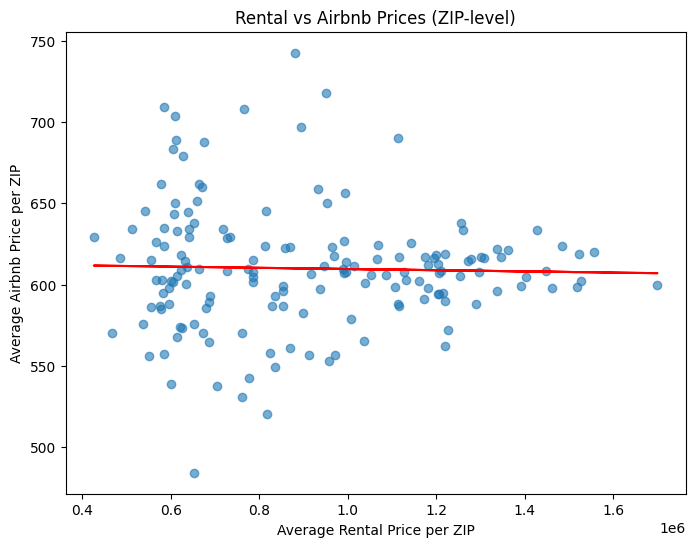

In [ ]:
from sklearn.linear_model import LinearRegression

X = merged[["avg_rental_price"]]
y = merged["avg_airbnb_price"]

#Imports / fits linear regression with rental data as our input, and avg_airbnb price as output
model = LinearRegression()
model.fit(X, y)

#Recall that our data is indexed by zipcode - so we are plotting features (x,y) which belong to the same zipcode

print("R²:", model.score(X, y))
#Calculates R^2 for our regression

plt.figure(figsize=(8,6))

#Plots average rental price and average airbnb price, from our actual data
plt.scatter(merged["avg_rental_price"], merged["avg_airbnb_price"], alpha=0.6)


#Plots our average rental price and the PREDICTED average airbnb price, as a line in red
plt.plot(
    merged["avg_rental_price"],
    model.predict(X),
    color="red"
)

plt.xlabel("Average Rental Price per ZIP")
plt.ylabel("Average Airbnb Price per ZIP")
plt.title("Rental vs Airbnb Prices (ZIP-level)")
plt.show()

**Testing housing characteristics**: We test whether average housing characteristics per ZIP code can predict the average Airbnb nightly price in that ZIP.

Random Forest  →  R²: -0.145   MAE: $18.74
Linear Reg     →  R²: -0.105   MAE: $21.06


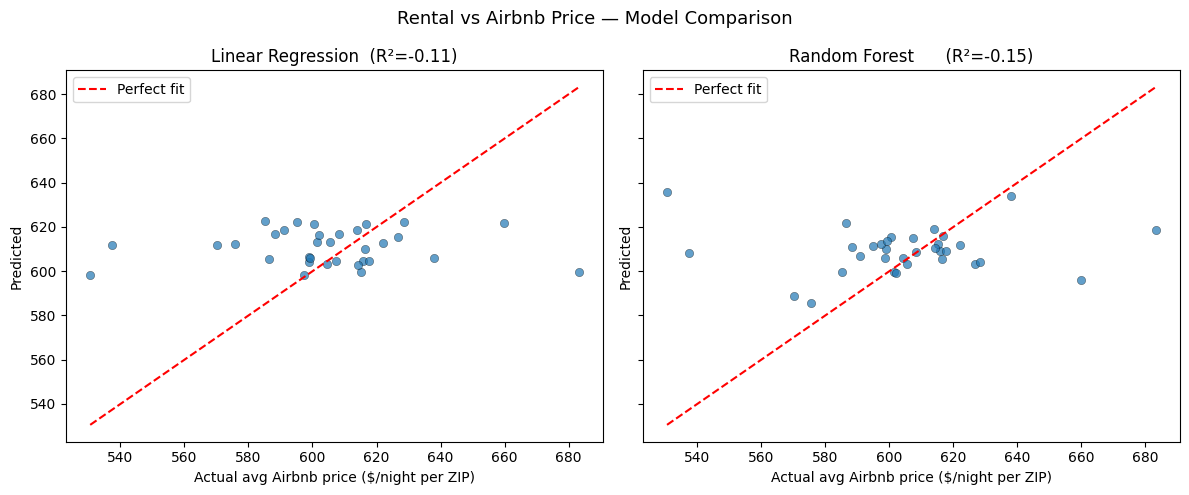

In [ ]:
#Splits our data
X_train, X_test, y_train, y_test = train_test_split(
    merged[feature_cols], merged["avg_airbnb_price"], test_size=0.2, random_state=42
)

# instantiates Random Forest Regressor
rf = RandomForestRegressor(n_estimators=200, random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)
y_pred_rf = rf.predict(X_test)
r2_rf = r2_score(y_test, y_pred_rf)

lr_base = LinearRegression().fit(X_train, y_train)
y_pred_lr = lr_base.predict(X_test)

#Calculates r^2 for each of our models, along with mean absolute error, and prints these
print(f"Random Forest  →  R²: {r2_rf:.3f}   MAE: ${mean_absolute_error(y_test, y_pred_rf):.2f}")
print(f"Linear Reg     →  R²: {r2_score(y_test, y_pred_lr):.3f}   MAE: ${mean_absolute_error(y_test, y_pred_lr):.2f}")


#Create two subplots, one for our linear regression, and one for our random forest regression
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)
for ax, preds, title in zip(
    axes,
    [y_pred_lr, y_pred_rf],
    [f"Linear Regression  (R²={r2_score(y_test, y_pred_lr):.2f})",
     f"Random Forest      (R²={r2_rf:.2f})"],
):
    ax.scatter(y_test, preds, alpha=0.7, edgecolors="k", linewidths=0.3)
    lims = [min(y_test.min(), preds.min()), max(y_test.max(), preds.max())]
    ax.plot(lims, lims, "r--", label="Perfect fit")
    ax.set_xlabel("Actual avg Airbnb price ($/night per ZIP)")
    ax.set_ylabel("Predicted")
    ax.set_title(title)
    ax.legend()
fig.suptitle("Rental vs Airbnb Price — Model Comparison", fontsize=13)
plt.tight_layout()
plt.show()

**Takeaways**:
Both a Random Forest and linear regression return negative R² values, indicating no meaningful relationship between neighborhood housing prices and Airbnb pricing at the ZIP level.

**Test individual property level**: We test whether neighborhood housing characteristics can predict individual Airbnb nightly prices. Each listing is joined with the average housing price, bedrooms, and bathrooms for its ZIP code, then combined with listing-level features like room type and location to compare a Random Forest against a linear regression baseline.

In [ ]:
gdf_airbnb_filt.columns

Index(['id', 'NAME', 'host id', 'host_identity_verified', 'host name',
       'neighbourhood group', 'neighbourhood', 'lat', 'long', 'country',
       'country code', 'instant_bookable', 'cancellation_policy', 'room type',
       'Construction year', 'price', 'service fee', 'minimum nights',
       'number of reviews', 'last review', 'reviews per month',
       'review rate number', 'calculated host listings count',
       'availability 365', 'house_rules', 'license', 'geometry', 'index_right',
       'zipcode', 'GEOID20', 'GEOIDFQ20', 'CLASSFP20', 'MTFCC20', 'FUNCSTAT20',
       'ALAND20', 'AWATER20', 'INTPTLAT20', 'INTPTLON20'],
      dtype='object')

In [ ]:
airbnb_with_housing = gdf_airbnb_filt.merge(housing_zip_features, on="zipcode", how="inner")
airbnb_with_housing = pd.get_dummies(airbnb_with_housing, columns=["room type"], drop_first=True)
# Use all available useful features from the dataset
feature_cols_full = [
    "lat", "long",
    "instant_bookable",
    "Construction year", "minimum nights",
    "number of reviews", "reviews per month",
    "review rate number", "calculated host listings count",
    "availability 365",
    "room type_Hotel room", "room type_Private room", "room type_Shared room"
]

# Same but WITH avg_rental_price
feature_cols_with_housing = feature_cols_full + ["avg_rental_bedrooms", "avg_rental_bathrooms","avg_rental_price"]
# I deleted "housing_avg_rental_price" because it's not in the table

airbnb_with_housing["price"] = airbnb_with_housing["price"].astype(str).str.replace("[$,]", "", regex=True).str.strip().astype(float)

airbnb_with_housing = airbnb_with_housing.dropna(subset=feature_cols_with_housing + ["price"]).reset_index(drop=True)

# Redefine y AFTER the dropna
y = airbnb_with_housing["price"]

results = {}
for name, cols in [("Without Housing Price", feature_cols_full),
                   ("With Housing Price", feature_cols_with_housing)]:
    X = airbnb_with_housing[cols]
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

    rf = RandomForestRegressor(n_estimators=200, random_state=42, n_jobs=-1)
    rf.fit(X_train, y_train)
    y_pred = rf.predict(X_test)

    r2 = r2_score(y_test, y_pred)
    mae = mean_absolute_error(y_test, y_pred)
    results[name] = {"R2": r2, "MAE": mae, "model": rf, "cols": cols}
    print(f"{name} -> R²: {r2:.3f}  MAE: ${mae:.2f}")

Without Housing Price -> R²: 0.384  MAE: $189.06
With Housing Price -> R²: 0.387  MAE: $188.01


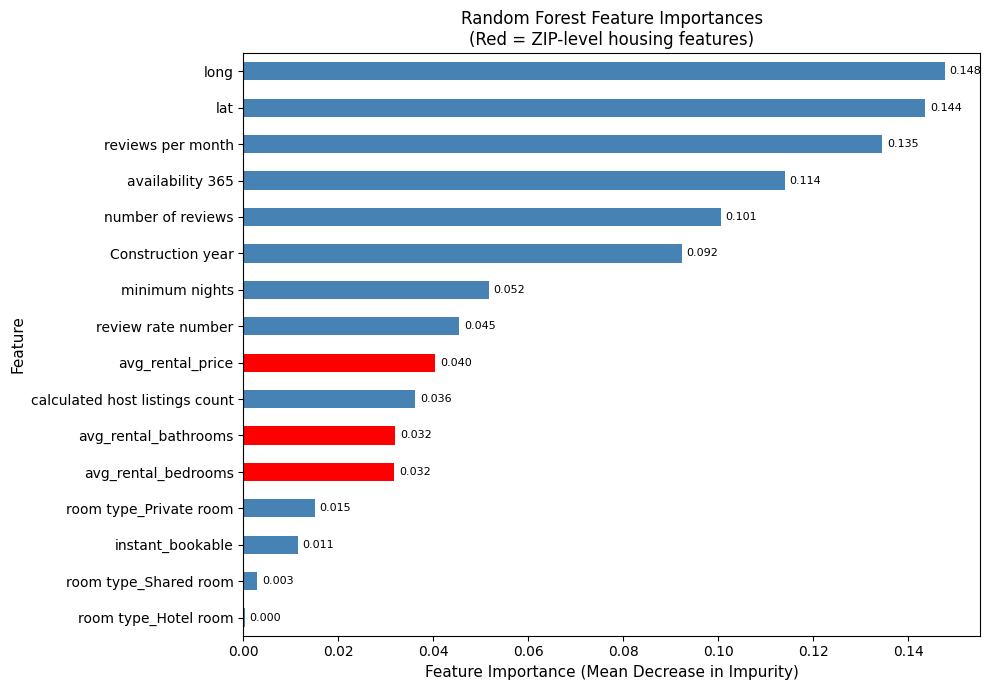

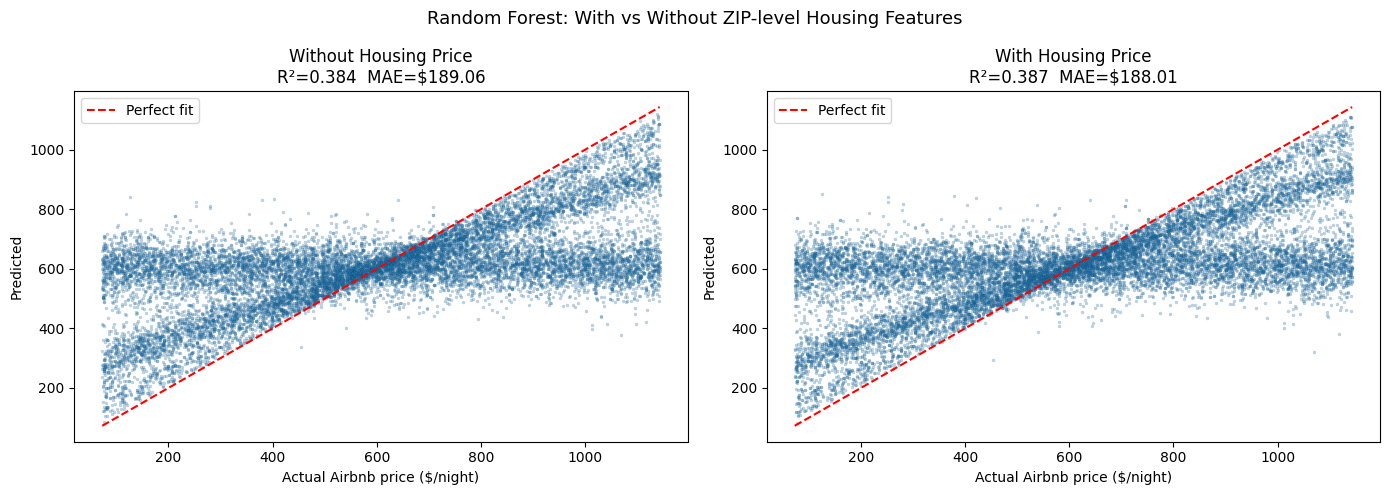

In [ ]:
importances = pd.Series(results["With Housing Price"]["model"].feature_importances_,
                        index=feature_cols_with_housing)

fig, ax = plt.subplots(figsize=(10, 7))
colors = ["red" if "avg_rental" in i or "avg_bath" in i or "avg_bed" in i
          else "steelblue" for i in importances.sort_values().index]

importances.sort_values().plot(kind='barh', ax=ax, color=colors)

ax.set_xlabel("Feature Importance (Mean Decrease in Impurity)", fontsize=11)
ax.set_ylabel("Feature", fontsize=11)
ax.set_title("Random Forest Feature Importances\n(Red = ZIP-level housing features)", fontsize=12)

# Add value labels
for i, (val, name) in enumerate(zip(importances.sort_values(), importances.sort_values().index)):
    ax.text(val + 0.001, i, f"{val:.3f}", va='center', fontsize=8)

plt.tight_layout()
plt.show()


fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, (name, res) in zip(axes, results.items()):
    X = airbnb_with_housing[res["cols"]]
    _, X_test, _, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
    y_pred = res["model"].predict(X_test)

    lims = [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())]
    ax.scatter(y_test, y_pred, alpha=0.3, edgecolors="k", linewidths=0.1, s=5)
    ax.plot(lims, lims, "r--", label="Perfect fit")
    ax.set_xlabel("Actual Airbnb price ($/night)")
    ax.set_ylabel("Predicted")
    ax.set_title(f"{name}\nR²={res['R2']:.3f}  MAE=${res['MAE']:.2f}")
    ax.legend()

fig.suptitle("Random Forest: With vs Without ZIP-level Housing Features", fontsize=13)
plt.tight_layout()
plt.show()

In [ ]:
print(gdf_airbnb_filt.columns.tolist())

['id', 'NAME', 'host id', 'host_identity_verified', 'host name', 'neighbourhood group', 'neighbourhood', 'lat', 'long', 'country', 'country code', 'instant_bookable', 'cancellation_policy', 'room type', 'Construction year', 'price', 'service fee', 'minimum nights', 'number of reviews', 'last review', 'reviews per month', 'review rate number', 'calculated host listings count', 'availability 365', 'house_rules', 'license', 'geometry', 'index_right', 'zipcode', 'GEOID20', 'GEOIDFQ20', 'CLASSFP20', 'MTFCC20', 'FUNCSTAT20', 'ALAND20', 'AWATER20', 'INTPTLAT20', 'INTPTLON20']


# Part 3 - Summarizing our findings and conclusions



Recall that the two original questions we sought to answer were as follows:
1. How do the features of an airbnb (bedrooms, bathrooms, amenities offered, etc.) affect the average user experience (as reflected by the rating the user leaves on an airbnb?
2. How does average price of a rental unit/home in a neighborhood relate to the average price of an airbnb in the same area?

In terms of **analyzing amenities and their effect on price/review scores**, we have found that the amenities which seem to have the largest effect on price were
 - Number of bedrooms/bathrooms
 - Having a hair dryer / other personal care items

The amenities which seem to have the largest effect on review score of a listing (based on looking at the first 3 layers of a binary decision tree ) were:
- Having a kitchen / cooking utensils
- Number of bedrooms / bathrooms
- Number of people a listing can accomodate

Ultimately our model to predict whether a listing had an above average review rating performed somewhat better than guessing, but still was far from perfect. Most likely, this is due to two fundamental shortcomings with our data/problem
- Luxury amenities which one might expect to cause a drastic increase in price / user experience (e.g. Pool, large home, having a patio, etc.) are extremely rare - so these features have no impact on our model
- Reviews are probably more a reflection of other aspects of an airbnb listing, like how caring/responsive the host is, how clean the property is, having a good location, etc. - none of these are reflected by the list of amenities under an airbnb

For our **second question**, we have found that there seems to be *little correlation* between the average airbnb price in a neighborhood and the average price of a housing property in a neighborhood (within New York City). This was very surprising for us, since it seems that it would be a necessity for hosts of an airbnb to charge more if their mortgage on a property is more expensive. We believe there are a few things this could be indicative of:
- New York City as a whole has some of the highest housing costs within the United States. It is possible that if we were to repeat this analysis and included **other cities** then we would see a more general trend that airbnb costs might on average be higher in cities that had more expensive housing costs on average
- Although we did control for outliers as a whole within our data, since areas like central Manhattan might have substantially higher housing costs than boroughs like Long Island or Harlem, it is possible that we ended up keeping the outliers in less expensive neighborhoods. Perhaps a better approach would have been to try and break up zipcodes into larger neighborhods, and remove outliers based on these neighborhoods


### Future Ideas

If given more time, then it would be interesting to instead approach our question of analyzing which amenities affect user experience as an NLP problem - namely, one could parse the actual reviews left by users, and try to extract key amenities which were listed in the review, along with some sentiment analysis to understand whether the user felt positive or negative about that amenity.

Additionally, rather than approach modelling review scores based on features of the home, we would be interested in trying to model review scores based on **features of the host** - e.g. things like host response time, number of reviews, number of separate listings, etc. This could inform Airbnb about whether the user experience tends to be more based on the quality of the host, rather than quality of the home listed.